In [1]:
# Cell 1 - Inspect existing data and path-export capability
from pathlib import Path
import shutil
import subprocess
import numpy as np
import pandas as pd
import nibabel as nib

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
DWI, BPX, ANAT, TRACK = [ROOT / x for x in
    ("BEDPOSTX", "BEDPOSTX.bedpostX", "T1", "PROBTRACKX")]
assert ROOT.is_dir(), f"Directory not found: {ROOT}"
print("Project:", ROOT)

posterior_files = [
    BPX / f"merged_{part}{k}samples.nii.gz"
    for k in (1, 2) for part in ("th", "ph", "f")
]
image_files = [
    DWI / "data.nii.gz", DWI / "nodif_brain_mask.nii.gz",
    BPX / "nodif_brain_mask.nii.gz",
] + posterior_files
required = image_files + [DWI / "bvals", DWI / "bvecs"]
missing = [str(p.relative_to(ROOT)) for p in required if not p.is_file()]
assert not missing, f"Missing files: {missing}"

# Load headers only; do not read the full 4D arrays.
images = {p: nib.load(p) for p in image_files}
diff_ref = images[BPX / "nodif_brain_mask.nii.gz"]
rows = []
for p, img in images.items():
    same = img.shape[:3] == diff_ref.shape[:3] and np.allclose(
        img.affine, diff_ref.affine, atol=1e-4, rtol=0
    )
    rows.append({
        "file": str(p.relative_to(ROOT)), "shape": str(img.shape),
        "grid_match": same,
    })
header_qc = pd.DataFrame(rows)
print(header_qc.to_string(index=False))
assert header_qc.grid_match.all(), "Diffusion/posterior grid mismatch."

shapes = {images[p].shape for p in posterior_files}
assert len(shapes) == 1, "Posterior sample shapes differ."
post_shape = next(iter(shapes))
assert len(post_shape) == 4 and post_shape[3] > 0, "Expected 4D posterior samples."
dwi_shape = images[DWI / "data.nii.gz"].shape
bvals = np.loadtxt(DWI / "bvals").ravel()
bvecs = np.loadtxt(DWI / "bvecs", ndmin=2)
assert len(dwi_shape) == 4 and bvals.size == dwi_shape[3], "Volume/b-value mismatch."
assert bvecs.shape in ((3, bvals.size), (bvals.size, 3)), "Gradient-table shape mismatch."

print("\nVoxel sizes:", diff_ref.header.get_zooms()[:3])
print("Spatial units:", diff_ref.header.get_xyzt_units()[0])
print("Posterior samples per component:", post_shape[3])
print("DWI volumes:", dwi_shape[3])
print("Transform files:", sorted(p.name for p in (BPX / "xfms").glob("*") if p.is_file()))
print(f"Free disk space: {shutil.disk_usage(ROOT).free / 2**30:.1f} GiB")

exe = shutil.which("probtrackx2")
print("\nprobtrackx2:", exe)
print("probtrackx2_gpu:", shutil.which("probtrackx2_gpu"))
if exe:
    try:
        help_result = subprocess.run(
            [exe, "--help"], capture_output=True, text=True, timeout=15
        )
        help_text = help_result.stdout + help_result.stderr
        for flag in ("--savepaths", "--opathdir"):
            lines = [s.strip() for s in help_text.splitlines() if flag in s]
            print(flag + ":", " | ".join(lines) if lines else "Not listed in help")
    except (OSError, subprocess.TimeoutExpired) as error:
        print("Help check failed:", error)
print("\nInspection complete. No tracking was run and no data files were changed.")

Project: /mnt/g/Research/TUM_connectome/HyperbolicTest
                                      file              shape  grid_match
                      BEDPOSTX/data.nii.gz (130, 130, 60, 31)        True
          BEDPOSTX/nodif_brain_mask.nii.gz     (130, 130, 60)        True
 BEDPOSTX.bedpostX/nodif_brain_mask.nii.gz     (130, 130, 60)        True
BEDPOSTX.bedpostX/merged_th1samples.nii.gz (130, 130, 60, 50)        True
BEDPOSTX.bedpostX/merged_ph1samples.nii.gz (130, 130, 60, 50)        True
 BEDPOSTX.bedpostX/merged_f1samples.nii.gz (130, 130, 60, 50)        True
BEDPOSTX.bedpostX/merged_th2samples.nii.gz (130, 130, 60, 50)        True
BEDPOSTX.bedpostX/merged_ph2samples.nii.gz (130, 130, 60, 50)        True
 BEDPOSTX.bedpostX/merged_f2samples.nii.gz (130, 130, 60, 50)        True

Voxel sizes: (2.0, 2.0, 2.0)
Spatial units: mm
Posterior samples per component: 50
DWI volumes: 31
Transform files: ['diff2str.mat', 'eye.mat', 'str2diff.mat']
Free disk space: 217.2 GiB

probtrackx2: Non

Brain-mask voxels: 227,635
                 file             shape  grid_match
mean_f1samples.nii.gz    (130, 130, 60)        True
mean_f2samples.nii.gz    (130, 130, 60)        True
        dyads1.nii.gz (130, 130, 60, 3)        True
        dyads2.nii.gz (130, 130, 60, 3)        True

Component checks:
 component  mean_fraction_in_brain  median_nonzero_dyad_norm  invalid_direction_at_f_ge_0.05
         1                0.211971                       1.0                               0
         2                0.018427                       1.0                               0

Direction support at several QC thresholds:
 fraction_threshold  component_1_voxels  component_2_voxels  either_component_voxels  both_components_voxels
               0.05              163850               18736                   163850                   18736
               0.10              132271               15569                   132271                   15569
               0.20               94718    

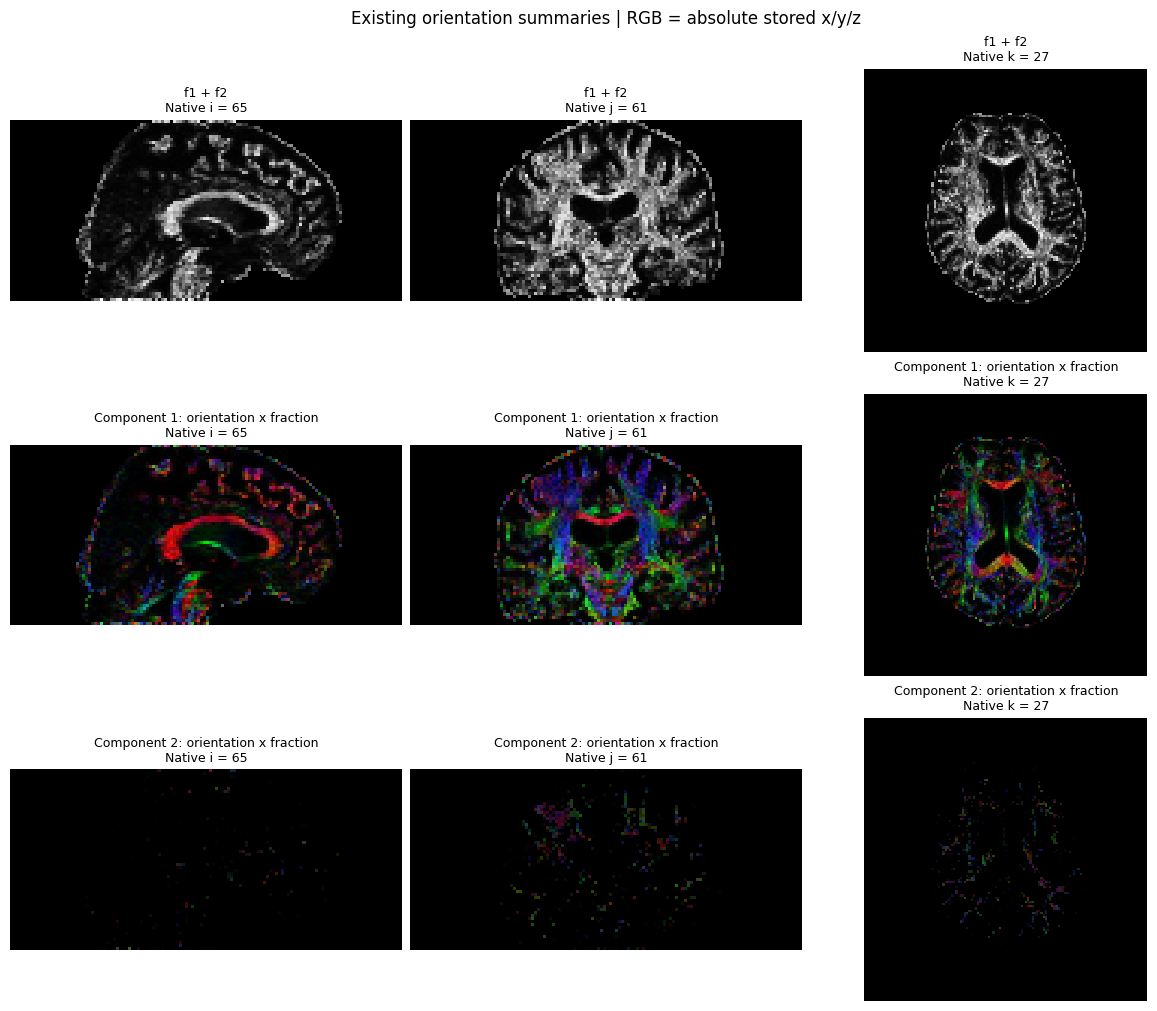


Saved QC outputs: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell02_direction_qc
No tracking was run. Original input files were not changed.


In [2]:
# Cell 2: Inspect existing fiber orientation summaries with Python.
# Fractions are BEDPOSTX model fractions, not FA or axon counts.
# Orientation axes are unsigned: v and -v represent the same axis.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
BPX = ROOT / "BEDPOSTX.bedpostX"
OUT = ROOT / "results" / "cell02_direction_qc"

ref = nib.load(BPX / "nodif_brain_mask.nii.gz")
mask_data = ref.get_fdata(dtype=np.float32)
if not np.isfinite(mask_data).all():
    raise ValueError("The brain mask contains non-finite values.")
brain = mask_data > 0
if not brain.any():
    raise ValueError("The brain mask is empty.")

file_rows = []

def load_field(name, vector=False):
    path = BPX / name
    img = nib.load(path)
    expected = brain.shape + ((3,) if vector else ())
    same_grid = img.shape == expected and np.allclose(
        img.affine, ref.affine, rtol=0, atol=1e-4
    )
    file_rows.append({
        "file": name,
        "shape": str(img.shape),
        "grid_match": bool(same_grid),
    })
    if not same_grid:
        raise ValueError(f"Unexpected shape or affine: {name}")
    data = img.get_fdata(dtype=np.float32)
    if not np.isfinite(data[brain]).all():
        raise ValueError(f"Non-finite values inside the brain: {name}")
    return np.where(brain[..., None] if vector else brain, data, 0)

# Array layouts:
# f_mean[i, j, k, component]
# directions[i, j, k, component, xyz]
f_mean = np.stack([
    load_field(f"mean_f{k}samples.nii.gz") for k in (1, 2)
], axis=-1)

raw_directions = np.stack([
    load_field(f"dyads{k}.nii.gz", vector=True) for k in (1, 2)
], axis=-2)

if np.any((f_mean[brain] < -1e-4) | (f_mean[brain] > 1.0001)):
    raise ValueError("Model fractions outside the expected [0, 1] range.")

norms = np.linalg.norm(raw_directions, axis=-1)
valid_direction = brain[..., None] & (norms > 1e-8)
directions = np.divide(
    raw_directions,
    norms[..., None],
    out=np.zeros_like(raw_directions),
    where=valid_direction[..., None],
)
f_sum = f_mean.sum(axis=-1)

component_rows = []
for k in range(2):
    n = norms[..., k][valid_direction[..., k]]
    component_rows.append({
        "component": k + 1,
        "mean_fraction_in_brain": float(f_mean[..., k][brain].mean()),
        "median_nonzero_dyad_norm": (
            float(np.median(n)) if n.size else np.nan
        ),
        "invalid_direction_at_f_ge_0.05": int(np.count_nonzero(
            brain & (f_mean[..., k] >= 0.05) & ~valid_direction[..., k]
        )),
    })
component_qc = pd.DataFrame(component_rows)

# QC thresholds only: these do not define the final analysis mask.
support_rows = []
for threshold in (0.05, 0.10, 0.20):
    supported = valid_direction & (f_mean >= threshold)
    support_rows.append({
        "fraction_threshold": threshold,
        "component_1_voxels": int(supported[..., 0].sum()),
        "component_2_voxels": int(supported[..., 1].sum()),
        "either_component_voxels": int(supported.any(axis=-1).sum()),
        "both_components_voxels": int(supported.all(axis=-1).sum()),
    })
support_qc = pd.DataFrame(support_rows)

# Axial angles are invariant to sign flips of either direction.
both = (valid_direction & (f_mean >= 0.10)).all(axis=-1)
dot = np.sum(directions[..., 0, :] * directions[..., 1, :], axis=-1)
angles = np.degrees(np.arccos(np.clip(np.abs(dot[both]), 0, 1)))
angle_quantiles = (
    np.percentile(angles, [10, 50, 90]).round(2).tolist()
    if angles.size else None
)

print(f"Brain-mask voxels: {brain.sum():,}")
print(pd.DataFrame(file_rows).to_string(index=False))
print("\nComponent checks:")
print(component_qc.to_string(index=False))
print("\nDirection support at several QC thresholds:")
print(support_qc.to_string(index=False))
print(
    "\nAxial angle P10/P50/P90 at f1,f2 >= 0.10 (degrees):",
    angle_quantiles,
)
sum_violations = int(np.count_nonzero(brain & (f_sum > 1.001)))
print(f"Brain voxels with f1 + f2 > 1.001: {sum_violations}")
if component_qc["invalid_direction_at_f_ge_0.05"].sum() or sum_violations:
    print("WARNING: Review the flagged values before constructing a graph.")

# Native-grid previews; no anatomical reorientation or vector conversion.
# RGB = absolute stored x/y/z components; brightness = model fraction.
center = np.median(np.argwhere(brain), axis=0).astype(int)
rgb_fields = [
    np.abs(directions[..., k, :]) * np.clip(f_mean[..., k, None], 0, 1)
    for k in range(2)
]
views = [f_sum] + rgb_fields
titles = [
    "f1 + f2",
    "Component 1: orientation x fraction",
    "Component 2: orientation x fraction",
]
fig, axes = plt.subplots(
    3, 3, figsize=(12, 10), constrained_layout=True
)
for row, volume in enumerate(views):
    for axis, index in enumerate(center):
        plane = np.take(volume, int(index), axis=axis).swapaxes(0, 1)
        ax = axes[row, axis]
        options = (
            {"cmap": "gray", "vmin": 0, "vmax": 1} if row == 0 else {}
        )
        ax.imshow(
            plane, origin="lower", interpolation="nearest", **options
        )
        ax.set_title(
            f"{titles[row]}\nNative {'ijk'[axis]} = {index}", fontsize=9
        )
        ax.axis("off")
fig.suptitle(
    "Existing orientation summaries | RGB = absolute stored x/y/z"
)

OUT.mkdir(parents=True, exist_ok=True)
pd.DataFrame(file_rows).to_csv(OUT / "input_grid_checks.csv", index=False)
component_qc.to_csv(OUT / "component_qc.csv", index=False)
support_qc.to_csv(OUT / "direction_support.csv", index=False)
if "header_qc" in globals():
    header_qc.to_csv(OUT / "cell01_header_qc.csv", index=False)

metadata = {
    "project": str(ROOT),
    "shape": list(brain.shape),
    "voxel_sizes_mm": [float(v) for v in ref.header.get_zooms()[:3]],
    "affine": ref.affine.tolist(),
    "brain_voxels": int(brain.sum()),
    "qc_fraction_thresholds": [0.05, 0.10, 0.20],
    "axial_angle_threshold": 0.10,
    "axial_angle_p10_p50_p90_degrees": angle_quantiles,
    "fraction_sum_violations": sum_violations,
    "direction_convention": (
        "Stored BEDPOSTX components; not converted to world axes"
    ),
    "scope": "Orientation-summary QC; no trajectories or geometric inference",
}
(OUT / "qc_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

header = ref.header.copy()
header.set_data_dtype(np.float32)
nib.save(
    nib.Nifti1Image(f_sum, ref.affine, header),
    OUT / "f_sum.nii.gz",
)
fig.savefig(OUT / "orientation_preview.png", dpi=180)
plt.show()

print(f"\nSaved QC outputs: {OUT}")
print("No tracking was run. Original input files were not changed.")

Reading posterior component 1/2 ...
Reading posterior component 2/2 ...

Stored posterior samples per component: 50
 component  supported_voxels  median_cone95_deg  p90_cone95_deg  mean_P_f_ge_0.10  center_check_voxels  dyad_error_p95_deg  max_fraction_mean_error
         1            132271            31.6723         81.5212          0.898802               131789                   0              1.78814e-07
         2             15569            66.2389         85.1562          0.875988                15426                   0               8.9407e-08


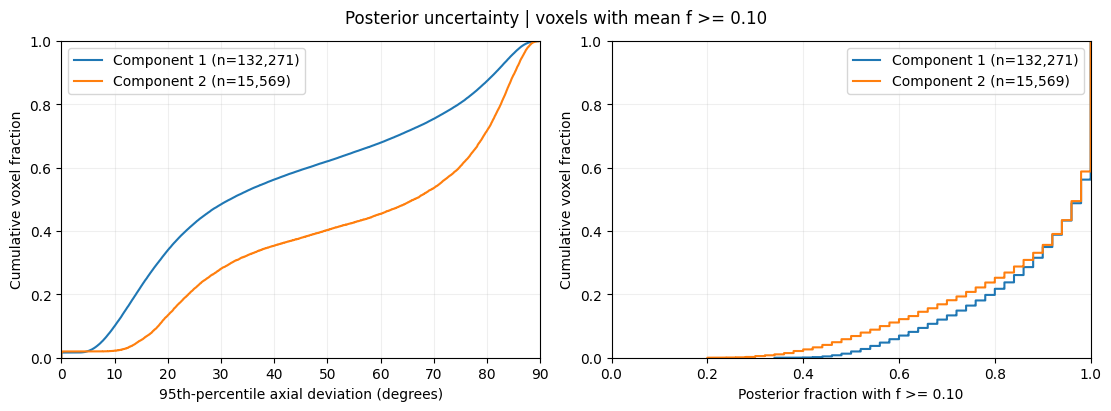


Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell03_posterior_qc


In [3]:
# Cell 3: Summarize existing posterior uncertainty. Run after Cell 2.
# Axial directions are sign-invariant. No FSL or tracking is used.

import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

OUT3 = ROOT / "results" / "cell03_posterior_qc"
F_MIN = 0.10  # Descriptive QC threshold; not a final analysis mask.
ijk = np.argwhere(brain).astype(np.int16)
axes_stored = directions[brain]
valid_axes = valid_direction[brain]
fractions = f_mean[brain]
eligible = valid_axes & (fractions >= F_MIN)
cone95 = np.full(fractions.shape, np.nan, dtype=np.float32)
p_fraction = np.zeros_like(fractions)
rows = []
sample_counts = []

def load_samples(part, component):
    path = BPX / f"merged_{part}{component}samples.nii.gz"
    img = nib.load(path)
    if (len(img.shape) != 4 or img.shape[:3] != brain.shape or
            not np.allclose(img.affine, ref.affine, rtol=0, atol=1e-4)):
        raise ValueError(f"Posterior grid mismatch: {path.name}")
    # Decompress each file once, then retain only brain voxels.
    data = img.get_fdata(dtype=np.float32, caching="unchanged")[brain]
    if not np.isfinite(data).all():
        raise ValueError(f"Non-finite posterior values: {path.name}")
    return data

def axial_summary(theta, phi, center_axes):
    u = np.stack([
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi),
        np.cos(theta),
    ], axis=-1)
    cosine = np.abs(np.einsum("nsc,nc->ns", u, center_axes))
    deviations = np.degrees(np.arccos(np.clip(cosine, 0, 1)))
    q95 = np.percentile(deviations, 95, axis=1)

    # Reconstruct the axial center to check against the saved dyad.
    moment = np.einsum("nsi,nsj->nij", u, u) / u.shape[1]
    values, vectors = np.linalg.eigh(moment)
    alignment = np.abs(np.sum(vectors[..., -1] * center_axes, axis=1))
    error = np.degrees(np.arccos(np.clip(alignment, 0, 1)))
    gap = values[:, -1] - values[:, -2]
    return q95, error, gap

for k in range(2):
    print(f"Reading posterior component {k + 1}/2 ...", flush=True)
    theta = load_samples("th", k + 1)
    phi = load_samples("ph", k + 1)
    f_samples = load_samples("f", k + 1)
    if theta.shape != phi.shape or theta.shape != f_samples.shape:
        raise ValueError("Posterior sample counts do not match.")
    if theta.shape[1] < 2:
        raise ValueError("At least two posterior samples are required.")
    if np.any((f_samples < -1e-4) | (f_samples > 1.0001)):
        raise ValueError("Posterior fractions outside [0, 1].")

    sample_counts.append(theta.shape[1])
    p_fraction[:, k] = (f_samples >= F_MIN).mean(axis=1)
    mean_error = float(np.max(np.abs(
        f_samples.mean(axis=1) - fractions[:, k]
    )))
    del f_samples

    q95, center_error, gap = axial_summary(
        theta, phi, axes_stored[:, k]
    )
    del theta, phi
    cone95[valid_axes[:, k], k] = q95[valid_axes[:, k]]
    keep = eligible[:, k]

    # Exclude nearly degenerate centers from the consistency check.
    check_center = keep & (gap > 0.05)
    rows.append({
        "component": k + 1,
        "supported_voxels": int(keep.sum()),
        "median_cone95_deg": (
            float(np.median(q95[keep])) if keep.any() else np.nan
        ),
        "p90_cone95_deg": (
            float(np.percentile(q95[keep], 90)) if keep.any() else np.nan
        ),
        "mean_P_f_ge_0.10": (
            float(p_fraction[keep, k].mean()) if keep.any() else np.nan
        ),
        "center_check_voxels": int(check_center.sum()),
        "dyad_error_p95_deg": (
            float(np.percentile(center_error[check_center], 95))
            if check_center.any() else np.nan
        ),
        "max_fraction_mean_error": mean_error,
    })

if len(set(sample_counts)) != 1:
    raise ValueError("The two components have different sample counts.")

posterior_qc = pd.DataFrame(rows)
print(f"\nStored posterior samples per component: {sample_counts[0]}")
print(posterior_qc.to_string(
    index=False, float_format=lambda x: f"{x:.6g}"
))
if ((posterior_qc["max_fraction_mean_error"] > 1e-3).any() or
        (posterior_qc["dyad_error_p95_deg"] > 1).any()):
    print(
        "WARNING: Posterior summaries differ from saved summaries; "
        "review before graph construction."
    )

fig, plot_axes = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True
)
for k in range(2):
    keep = eligible[:, k]
    for ax, data in zip(
        plot_axes, [cone95[keep, k], p_fraction[keep, k]]
    ):
        x = np.sort(data[np.isfinite(data)])
        if x.size:
            ax.step(
                x, np.arange(1, x.size + 1) / x.size, where="post",
                label=f"Component {k + 1} (n={x.size:,})",
            )
for ax, label, limits in zip(
    plot_axes,
    ["95th-percentile axial deviation (degrees)",
     "Posterior fraction with f >= 0.10"],
    [(0, 90), (0, 1)],
):
    ax.set(
        xlabel=label, ylabel="Cumulative voxel fraction",
        xlim=limits, ylim=(0, 1),
    )
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle("Posterior uncertainty | voxels with mean f >= 0.10")

OUT3.mkdir(parents=True, exist_ok=True)
posterior_qc.to_csv(OUT3 / "posterior_qc.csv", index=False)

# Compact inputs for the next analysis cell.
np.savez_compressed(
    OUT3 / "orientation_posterior_summary.npz",
    ijk=ijk, affine=ref.affine, shape=np.array(brain.shape),
    directions_stored=axes_stored, valid_direction=valid_axes,
    mean_f=fractions, cone95_deg=cone95,
    p_f_ge_threshold=p_fraction,
    fraction_threshold=F_MIN,
    samples_per_component=sample_counts[0],
)

# Uncertainty maps for FSLeyes; undefined/background values are NaN.
for k in range(2):
    volume = np.full(brain.shape, np.nan, dtype=np.float32)
    volume[brain] = cone95[:, k]
    header = ref.header.copy()
    header.set_data_dtype(np.float32)
    nib.save(
        nib.Nifti1Image(volume, ref.affine, header),
        OUT3 / f"cone95_component{k + 1}.nii.gz",
    )

metadata = {
    "source_directory": str(BPX),
    "samples_per_component": sample_counts[0],
    "fraction_threshold": F_MIN,
    "cone95_definition": (
        "95th percentile of acos(abs(u_sample dot dyad)), in degrees"
    ),
    "cone95_conditioning": (
        "All stored direction samples, without filtering by sample f"
    ),
    "quantile_method": "NumPy default linear interpolation",
    "center_check_min_eigenvalue_gap": 0.05,
    "direction_basis": (
        "Stored BEDPOSTX basis; not converted to world axes"
    ),
    "nifti_background": (
        "NaN outside the brain and at invalid center directions"
    ),
    "interpretation": (
        "Within-model posterior summaries; "
        "samples are not independent subjects"
    ),
}
(OUT3 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
fig.savefig(OUT3 / "posterior_uncertainty.png", dpi=180)
plt.show()
print(f"\nSaved: {OUT3}")

Supported orientation nodes: 147,840
FSL vector x-component correction: +1
Building local compatibility graph ...


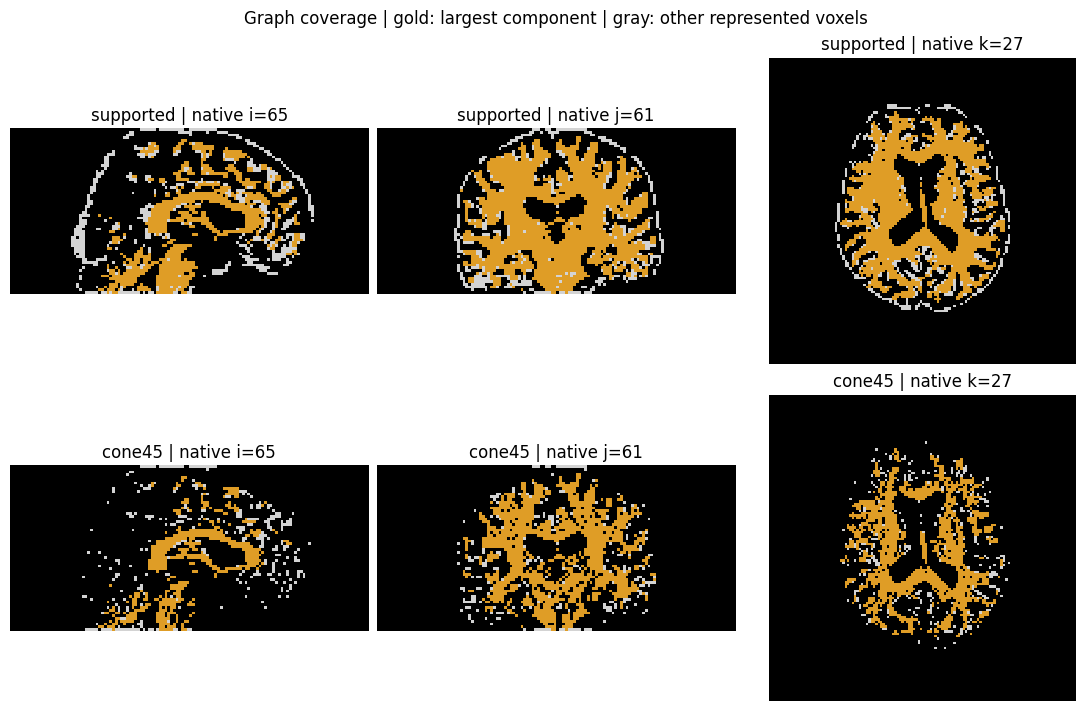


    graph  nodes  represented_voxels  edges  isolates  components  largest_nodes  largest_node_fraction  largest_voxels  mean_degree
supported 147840              132271 238809     22518       26796         112254               0.759294           99926     3.230641
   cone45  84328               78481 133750     12211       14088          65918               0.781686           62630     3.172137

Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell04_orientation_graph
No tracking, ROI aggregation, or hyperbolicity test was run.


In [4]:
# Cell 4: Build exploratory voxel-orientation graphs from saved summaries.
# Each node is (voxel, component). Edges represent local compatibility,
# not observed axons or recovered PROBTRACKX trajectories.

from pathlib import Path
from itertools import product
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import sparse
from scipy.sparse.csgraph import connected_components

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results" / "cell03_posterior_qc"
OUT4 = ROOT / "results" / "cell04_orientation_graph"

# Exploratory parameters fixed before any geometry tests.
F_MIN, STEP_MAX_DEG, TURN_MAX_DEG = 0.10, 45.0, 45.0
VARIANTS = {"supported": None, "cone45": 45.0}

qc = pd.read_csv(SRC / "posterior_qc.csv")
if ((qc["max_fraction_mean_error"] > 1e-3).any() or
        (qc["dyad_error_p95_deg"] > 1).any()):
    raise ValueError("Resolve Cell 3 consistency warnings before building graphs.")

with np.load(SRC / "orientation_posterior_summary.npz") as z:
    ijk, f, u, valid, cone, pf, affine, shape = [
        z[key] for key in [
            "ijk", "mean_f", "directions_stored", "valid_direction",
            "cone95_deg", "p_f_ge_threshold", "affine", "shape"
        ]
    ]
    if not np.isclose(float(z["fraction_threshold"]), F_MIN):
        raise ValueError("Posterior support threshold differs from F_MIN.")

shape = tuple(int(n) for n in shape)
ref = nib.load(ROOT / "BEDPOSTX.bedpostX" / "nodif_brain_mask.nii.gz")
if ref.shape != shape or not np.allclose(
    ref.affine, affine, rtol=0, atol=1e-4
):
    raise ValueError("Cached geometry differs from the reference image.")
if ref.header.get_xyzt_units()[0] != "mm":
    raise ValueError("Physical edge lengths require spatial units in mm.")

qform, qcode = ref.get_qform(coded=True)
sform, scode = ref.get_sform(coded=True)
if not (qcode or scode):
    raise ValueError("A coded spatial affine is required.")
if qcode and scode and (
    np.sign(np.linalg.det(qform[:3, :3])) !=
    np.sign(np.linalg.det(sform[:3, :3]))
):
    raise ValueError("qform and sform disagree on storage handedness.")

# Convert vector components only; voxel indices stay unchanged.
A = affine[:3, :3]
rotation = A / np.asarray(ref.header.get_zooms()[:3])[None, :]
if not np.allclose(
    rotation.T @ rotation, np.eye(3), rtol=0, atol=1e-4
):
    raise ValueError("Non-orthogonal image affine: review vector conversion.")

x_sign = -1.0 if np.linalg.det(A) > 0 else 1.0
vector_to_world = rotation @ np.diag([x_sign, 1.0, 1.0])

voxel_row, component = np.where(valid & (f >= F_MIN))
node_ijk = ijk[voxel_row]
node_u = u[voxel_row, component] @ vector_to_world.T
node_u /= np.linalg.norm(node_u, axis=1, keepdims=True)
node_cone = cone[voxel_row, component]
if not len(node_ijk) or not np.isfinite(node_cone).all():
    raise ValueError("Missing nodes or undefined uncertainty at supported nodes.")

def build_graph(coords, components, axes, grid_shape, voxel_matrix):
    n = len(coords)
    lookup = np.full((*grid_shape, 2), -1, dtype=np.int32)
    lookup[tuple(coords.T) + (components,)] = np.arange(n, dtype=np.int32)

    # One offset per unordered neighboring voxel pair.
    offsets = [
        d for d in product((-1, 0, 1), repeat=3) if d > (0, 0, 0)
    ]
    step_cos = np.cos(np.deg2rad(STEP_MAX_DEG)) - 1e-7
    turn_cos = np.cos(np.deg2rad(TURN_MAX_DEG)) - 1e-7
    rr, cc, lengths = [], [], []

    for offset in offsets:
        displacement = voxel_matrix @ np.asarray(offset)
        distance = np.linalg.norm(displacement)
        step = displacement / distance

        source = np.flatnonzero(np.abs(axes @ step) >= step_cos)
        target_xyz = coords[source] + offset
        inside = (
            (target_xyz >= 0) & (target_xyz < grid_shape)
        ).all(axis=1)
        source, target_xyz = source[inside], target_xyz[inside]

        for target_component in (0, 1):
            destination = lookup[
                tuple(target_xyz.T) + (target_component,)
            ]
            exists = destination >= 0
            a, b = source[exists], destination[exists]
            compatible = (
                (np.abs(axes[b] @ step) >= step_cos) &
                (np.abs(np.sum(axes[a] * axes[b], axis=1)) >= turn_cos)
            )
            a, b = a[compatible], b[compatible]
            if a.size:
                rr.append(a.astype(np.int32))
                cc.append(b)
                lengths.append(
                    np.full(a.size, distance, dtype=np.float32)
                )

    if not rr:
        return sparse.csr_matrix((n, n), dtype=np.float32)
    G = sparse.coo_matrix(
        (np.concatenate(lengths),
         (np.concatenate(rr), np.concatenate(cc))),
        shape=(n, n),
    ).tocsr()
    return (G + G.T).tocsr()

print(f"Supported orientation nodes: {len(node_ijk):,}")
print(f"FSL vector x-component correction: {x_sign:+.0f}")
print("Building local compatibility graph ...", flush=True)

G = build_graph(node_ijk, component, node_u, shape, A)
if G.diagonal().any() or (G != G.T).nnz:
    raise ValueError("Graph must be symmetric with no self-loops.")

OUT4.mkdir(parents=True, exist_ok=True)
fig, panels = plt.subplots(
    2, 3, figsize=(11, 7), constrained_layout=True
)
center = np.median(ijk, axis=0).astype(int)
cmap = ListedColormap(["black", "lightgray", "#df9d26"])
summary = []

for row, (name, limit) in enumerate(VARIANTS.items()):
    selected = np.flatnonzero(
        np.ones(len(node_ijk), dtype=bool)
        if limit is None else node_cone <= limit
    )
    H = G[selected][:, selected].tocsr()
    n = H.shape[0]
    n_components, labels = connected_components(H, directed=False)
    sizes = np.bincount(labels)
    in_largest = (
        labels == sizes.argmax() if n else np.zeros(0, dtype=bool)
    )
    coords = node_ijk[selected]
    degree = np.diff(H.indptr)
    n_voxels = len(np.unique(voxel_row[selected]))
    largest_voxels = len(np.unique(voxel_row[selected][in_largest]))

    summary.append({
        "graph": name,
        "nodes": n,
        "represented_voxels": n_voxels,
        "edges": H.nnz // 2,
        "isolates": int((degree == 0).sum()),
        "components": n_components,
        "largest_nodes": int(in_largest.sum()),
        "largest_node_fraction": (
            float(in_largest.mean()) if n else 0.0
        ),
        "largest_voxels": largest_voxels,
        "mean_degree": float(degree.mean()) if n else 0.0,
    })

    # Sparse entries are distances, not connection strengths.
    sparse.save_npz(OUT4 / f"edge_lengths_{name}.npz", H)
    np.savez_compressed(
        OUT4 / f"nodes_{name}.npz",
        base_node_id=selected,
        ijk=coords,
        world_xyz_mm=coords @ A.T + affine[:3, 3],
        component=component[selected] + 1,
        direction_world=node_u[selected],
        mean_f=f[voxel_row[selected], component[selected]],
        cone95_deg=node_cone[selected],
        p_f_ge_threshold=pf[voxel_row[selected], component[selected]],
        connected_component=labels,
        degree=degree,
        in_largest=in_largest,
    )
    pd.DataFrame({
        "component_id": np.arange(len(sizes)),
        "nodes": sizes,
    }).sort_values("nodes", ascending=False).to_csv(
        OUT4 / f"component_sizes_{name}.csv", index=False
    )

    # 0=excluded, 1=represented, 2=any node in largest component.
    volume = np.zeros(shape, dtype=np.uint8)
    volume[tuple(coords.T)] = 1
    volume[tuple(coords[in_largest].T)] = 2
    header = ref.header.copy()
    header.set_data_dtype(np.uint8)
    nib.save(
        nib.Nifti1Image(volume, affine, header),
        OUT4 / f"coverage_{name}.nii.gz",
    )

    for axis, index in enumerate(center):
        panels[row, axis].imshow(
            np.take(volume, int(index), axis=axis).T,
            origin="lower", cmap=cmap, vmin=0, vmax=2,
            interpolation="nearest",
        )
        panels[row, axis].set_title(
            f"{name} | native {'ijk'[axis]}={index}"
        )
        panels[row, axis].axis("off")

graph_qc = pd.DataFrame(summary)
graph_qc.to_csv(OUT4 / "graph_qc.csv", index=False)
metadata = {
    "source": str(SRC / "orientation_posterior_summary.npz"),
    "node": (
        "Voxel and fiber-component pair; "
        "both components retained when eligible"
    ),
    "mean_fraction_min": F_MIN,
    "variants_cone95_max_deg": VARIANTS,
    "neighborhood": "26 spatial neighbors; no within-voxel edges",
    "max_axis_to_displacement_deg": STEP_MAX_DEG,
    "max_interaxis_deg": TURN_MAX_DEG,
    "edge_values": (
        "Positive physical step length in mm, not connection strength"
    ),
    "direction_to_world": vector_to_world.tolist(),
    "affine": affine.tolist(),
    "isolates": (
        "Retained; no graph is reduced to its largest component"
    ),
    "interpretation": (
        "Exploratory local compatibility graphs, "
        "not observed fiber trajectories"
    ),
}
(OUT4 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

fig.suptitle(
    "Graph coverage | gold: largest component | gray: other represented voxels"
)
fig.savefig(OUT4 / "graph_coverage.png", dpi=180)
plt.show()
print("\n" + graph_qc.to_string(index=False))
print(f"\nSaved: {OUT4}")
print("No tracking, ROI aggregation, or hyperbolicity test was run.")

Common largest-component nodes: 65,918
Common distinct voxels: 62,630
Matched landmarks: 64 | pairs: 2,016 | seed: 7
Computing supported: 64 shortest-path sources ...
Finished supported: 4.6 s
Computing cone45: 64 shortest-path sources ...
Finished cone45: 2.4 s


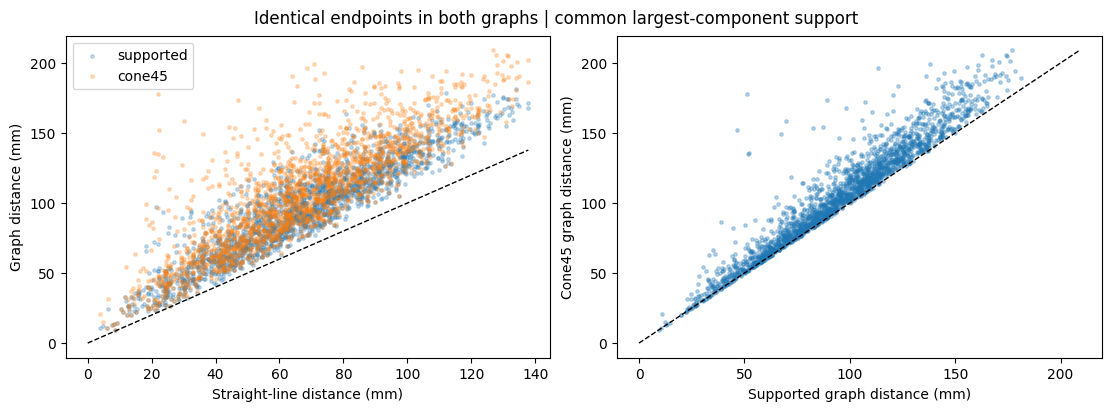

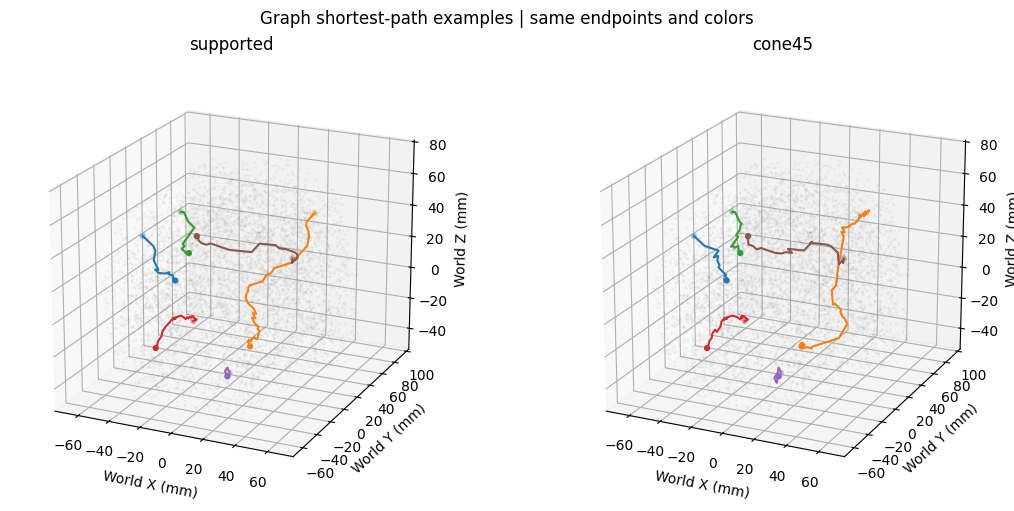


    graph  landmarks  pairs  median_distance_mm  median_detour  p95_detour
supported         64   2016           94.999754       1.392229    2.009940
   cone45         64   2016          105.750314       1.537443    2.421158

Example-path checks:
    graph  preview_pair  source_landmark  target_landmark  edges  euclidean_mm    path_mm   detour  max_step_turn_deg  turns_over_90_deg
supported             0                0               32     18     32.680270  49.312251 1.508930         135.000001                  5
supported             1                1               33     53     93.338096 144.087146 1.543712         135.000001                  6
supported             2                2               34     22     40.693980  55.019722 1.352036         144.735611                  3
supported             3                3               35     28     55.821144  71.161858 1.274819         134.999999                  2
supported             4                4               36      4   

In [5]:
# Cell 5: Matched-endpoint shortest paths and distance QC.
# These are graph paths, not reconstructed or observed fiber trajectories.

from pathlib import Path
import json
from time import perf_counter
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import scipy
from scipy import sparse
from scipy.sparse.csgraph import dijkstra
from scipy.spatial.distance import cdist

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results" / "cell04_orientation_graph"
OUT5 = ROOT / "results" / "cell05_path_geometry"
SEED, N_LANDMARKS = 7, 64
names = ("supported", "cone45")

nodes = {}
for name in names:
    with np.load(SRC / f"nodes_{name}.npz") as z:
        nodes[name] = {key: z[key] for key in (
            "base_node_id", "ijk", "world_xyz_mm",
            "component", "in_largest"
        )}

# Match the same orientation nodes in the two largest components.
a, b = [nodes[name] for name in names]
la = np.flatnonzero(a["in_largest"])
lb = np.flatnonzero(b["in_largest"])
common, ia, ib = np.intersect1d(
    a["base_node_id"][la], b["base_node_id"][lb],
    assume_unique=True, return_indices=True,
)
locations = {"supported": la[ia], "cone45": lb[ib]}
common_xyz = a["world_xyz_mm"][locations["supported"]]

if not np.allclose(
    common_xyz, b["world_xyz_mm"][locations["cone45"]]
):
    raise ValueError("Matched node coordinates differ between graphs.")
if not np.array_equal(
    a["component"][locations["supported"]],
    b["component"][locations["cone45"]],
):
    raise ValueError("Matched nodes have different orientation components.")

# Sample distinct common voxels, then one common component per voxel.
unique_voxels, inverse = np.unique(
    a["ijk"][locations["supported"]],
    axis=0, return_inverse=True,
)
n = min(N_LANDMARKS, len(unique_voxels))
if n < 8:
    raise ValueError("Too few common voxels for this comparison.")

rng = np.random.default_rng(SEED)
chosen = np.array([
    rng.choice(np.flatnonzero(inverse == v))
    for v in rng.choice(len(unique_voxels), n, replace=False)
])
landmark_ids = {
    name: locations[name][chosen] for name in names
}
xyz = common_xyz[chosen]
E = cdist(xyz, xyz)
i, j = np.triu_indices(n, 1)
if np.any(E[i, j] <= 0):
    raise ValueError("Landmarks must occupy distinct physical locations.")

# Preview pairs are fixed before examining their paths or distances.
preview_pairs = [
    (k, k + n // 2) for k in range(min(6, n // 2))
]

def trace_path(predecessor, source, target):
    path = [int(target)]
    while path[-1] != source:
        previous = int(predecessor[path[-1]])
        if previous < 0 or len(path) >= len(predecessor):
            raise ValueError("Invalid or unreachable predecessor chain.")
        path.append(previous)
    return np.array(path[::-1], dtype=np.int32)

def path_stats(points):
    steps = np.diff(points, axis=0)
    lengths = np.linalg.norm(steps, axis=1)
    if np.any(lengths <= 0):
        raise ValueError("A path contains a zero-length spatial step.")
    cosine = (
        np.sum(steps[:-1] * steps[1:], axis=1) /
        (lengths[:-1] * lengths[1:])
    )
    turns = np.degrees(np.arccos(np.clip(cosine, -1, 1)))
    return (
        float(lengths.sum()),
        float(turns.max()) if turns.size else 0.0,
        int(np.count_nonzero(turns > 90.001)),
    )

print(f"Common largest-component nodes: {len(common):,}")
print(f"Common distinct voxels: {len(unique_voxels):,}")
print(f"Matched landmarks: {n} | pairs: {len(i):,} | seed: {SEED}")

distances, previews, path_rows, summary = {}, {}, [], []
for name in names:
    start = perf_counter()
    G = sparse.load_npz(SRC / f"edge_lengths_{name}.npz").tocsr()
    if G.shape != (len(nodes[name]["base_node_id"]),) * 2:
        raise ValueError("Graph and node table sizes do not match.")
    if ((G != G.T).nnz or not np.isfinite(G.data).all()
            or np.any(G.data <= 0)):
        raise ValueError("Expected symmetric, positive, finite edge lengths.")

    print(f"Computing {name}: {n} shortest-path sources ...", flush=True)

    # Intermediate nodes can use the complete graph for each variant.
    all_distances, predecessors = dijkstra(
        G, directed=False, indices=landmark_ids[name],
        return_predecessors=True,
    )
    D = all_distances[:, landmark_ids[name]]
    if not np.isfinite(D).all() or not np.allclose(D, D.T, atol=1e-5):
        raise ValueError("Landmark distances are disconnected or asymmetric.")
    if np.any(D < E - 1e-3):
        raise ValueError(
            "Graph distance is shorter than physical straight-line distance."
        )

    distances[name] = D
    detour = D[i, j] / E[i, j]
    summary.append({
        "graph": name,
        "landmarks": n,
        "pairs": len(i),
        "median_distance_mm": float(np.median(D[i, j])),
        "median_detour": float(np.median(detour)),
        "p95_detour": float(np.percentile(detour, 95)),
    })

    previews[name] = []
    for pair_id, (s, t) in enumerate(preview_pairs):
        path = trace_path(
            predecessors[s],
            landmark_ids[name][s],
            landmark_ids[name][t],
        )
        points = nodes[name]["world_xyz_mm"][path]
        length, max_turn, reversals = path_stats(points)
        if not np.isclose(length, D[s, t], rtol=1e-6, atol=1e-3):
            raise ValueError(
                "Reconstructed path length differs from graph distance."
            )

        previews[name].append(points.astype(np.float32))
        path_rows.append({
            "graph": name,
            "preview_pair": pair_id,
            "source_landmark": s,
            "target_landmark": t,
            "edges": len(path) - 1,
            "euclidean_mm": float(E[s, t]),
            "path_mm": length,
            "detour": length / E[s, t],
            "max_step_turn_deg": max_turn,
            "turns_over_90_deg": reversals,
        })

    del G, all_distances, predecessors
    print(f"Finished {name}: {perf_counter() - start:.1f} s", flush=True)

D0, D1 = distances["supported"], distances["cone45"]
if np.any(D1 < D0 - 1e-3):
    raise ValueError(
        "Removing nodes shortened a matched path; review graph provenance."
    )

OUT5.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    OUT5 / "landmark_distances.npz",
    supported_mm=D0, cone45_mm=D1, euclidean_mm=E,
    base_node_id=common[chosen], world_xyz_mm=xyz,
    component=a["component"][landmark_ids["supported"]],
    seed=SEED,
)
pd.DataFrame({
    "landmark_id": np.arange(n),
    "base_node_id": common[chosen],
    "component": a["component"][landmark_ids["supported"]],
    "supported_node_id": landmark_ids["supported"],
    "cone45_node_id": landmark_ids["cone45"],
    "x_mm": xyz[:, 0], "y_mm": xyz[:, 1], "z_mm": xyz[:, 2],
}).to_csv(OUT5 / "landmarks.csv", index=False)

pairs = pd.DataFrame({
    "landmark_a": i, "landmark_b": j,
    "euclidean_mm": E[i, j],
    "supported_mm": D0[i, j],
    "cone45_mm": D1[i, j],
    "detour_supported": D0[i, j] / E[i, j],
    "detour_cone45": D1[i, j] / E[i, j],
    "cone45_over_supported": D1[i, j] / D0[i, j],
})
pairs.to_csv(OUT5 / "pair_distances.csv", index=False)
path_qc = pd.DataFrame(path_rows)
path_qc.to_csv(OUT5 / "preview_path_qc.csv", index=False)
summary = pd.DataFrame(summary)
summary.to_csv(OUT5 / "distance_summary.csv", index=False)

# Export graph-path examples for viewing; these are not tractography outputs.
for name in names:
    nib.streamlines.save(
        nib.streamlines.Tractogram(
            previews[name], affine_to_rasmm=np.eye(4)
        ),
        str(OUT5 / f"model_shortest_paths_{name}.tck"),
    )

fig, ax = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True
)
for name in names:
    ax[0].scatter(
        E[i, j], distances[name][i, j],
        s=6, alpha=0.25, label=name,
    )
ax[0].plot([0, E.max()], [0, E.max()], "k--", lw=1)
ax[0].set(
    xlabel="Straight-line distance (mm)",
    ylabel="Graph distance (mm)",
)
ax[0].legend()
ax[1].scatter(D0[i, j], D1[i, j], s=6, alpha=0.3)
limit = max(D0.max(), D1.max())
ax[1].plot([0, limit], [0, limit], "k--", lw=1)
ax[1].set(
    xlabel="Supported graph distance (mm)",
    ylabel="Cone45 graph distance (mm)",
)
fig.suptitle(
    "Identical endpoints in both graphs | common largest-component support"
)
fig.savefig(OUT5 / "matched_distances.png", dpi=180)

# Identical spatial context, endpoints, colors, and view for both previews.
cloud_rng = np.random.default_rng(SEED + 1)
cloud = a["world_xyz_mm"][
    cloud_rng.choice(
        len(a["world_xyz_mm"]),
        min(6000, len(a["world_xyz_mm"])),
        replace=False,
    )
]
low = a["world_xyz_mm"].min(axis=0)
high = a["world_xyz_mm"].max(axis=0)
fig2 = plt.figure(figsize=(11, 5), constrained_layout=True)

for panel, name in enumerate(names, 1):
    ax3 = fig2.add_subplot(1, 2, panel, projection="3d")
    ax3.scatter(*cloud.T, s=1, color="gray", alpha=0.05)
    for k, points in enumerate(previews[name]):
        ax3.plot(*points.T, color=f"C{k}", lw=1.5)
        ax3.scatter(*points[[0, -1]].T, color=f"C{k}", s=12)
    ax3.set(
        title=name,
        xlabel="World X (mm)",
        ylabel="World Y (mm)",
        zlabel="World Z (mm)",
        xlim=(low[0], high[0]),
        ylim=(low[1], high[1]),
        zlim=(low[2], high[2]),
    )
    ax3.set_box_aspect(np.maximum(high - low, 1))
    ax3.view_init(elev=20, azim=-65)

fig2.suptitle(
    "Graph shortest-path examples | same endpoints and colors"
)
fig2.savefig(OUT5 / "model_path_preview.png", dpi=180)
plt.show()

metadata = {
    "source_directory": str(SRC),
    "seed": SEED,
    "landmarks": n,
    "sampling": (
        "Uniform distinct common-LCC voxels, "
        "then one common component per voxel"
    ),
    "conditioning": (
        "Endpoints belong to both largest components; "
        "results are not whole-graph estimates"
    ),
    "routing": "Each complete graph retains all its intermediate nodes",
    "preview_pairs": preview_pairs,
    "scipy_version": scipy.__version__,
    "interpretation": (
        "Graph path QC only; detour is not evidence of hyperbolicity"
    ),
    "ties": (
        "A single shortest path is shown; "
        "equal-length alternatives may exist"
    ),
}
(OUT5 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("\n" + summary.to_string(index=False))
print("\nExample-path checks:")
print(path_qc.to_string(index=False))
print(
    "\nMedian cone45/supported distance: "
    f"{pairs['cone45_over_supported'].median():.3f}"
)
print(
    "Pairs lengthened by >10%: "
    f"{(pairs['cone45_over_supported'] > 1.10).mean():.1%}"
)
if (path_qc["turns_over_90_deg"] > 0).any():
    print(
        "WARNING: Sharp reversals occur in example graph paths; "
        "review the path model."
    )
print(f"\nSaved: {OUT5}")

Fixed turn cap: 60 degrees
Unchanged landmarks: 64 | pairs: 2,016

supported: 477,618 step states, 1,025,800 allowed transitions
  Sources finished: 8/64
  Sources finished: 16/64
  Sources finished: 24/64
  Sources finished: 32/64
  Sources finished: 40/64
  Sources finished: 48/64
  Sources finished: 56/64
  Sources finished: 64/64

cone45: 267,500 step states, 547,212 allowed transitions
  Sources finished: 8/64
  Sources finished: 16/64
  Sources finished: 24/64
  Sources finished: 32/64
  Sources finished: 40/64
  Sources finished: 48/64
  Sources finished: 56/64
  Sources finished: 64/64


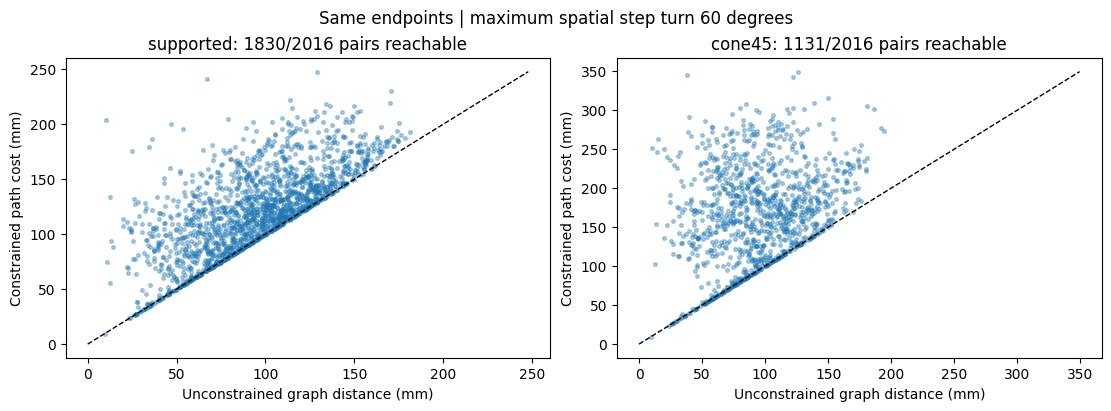

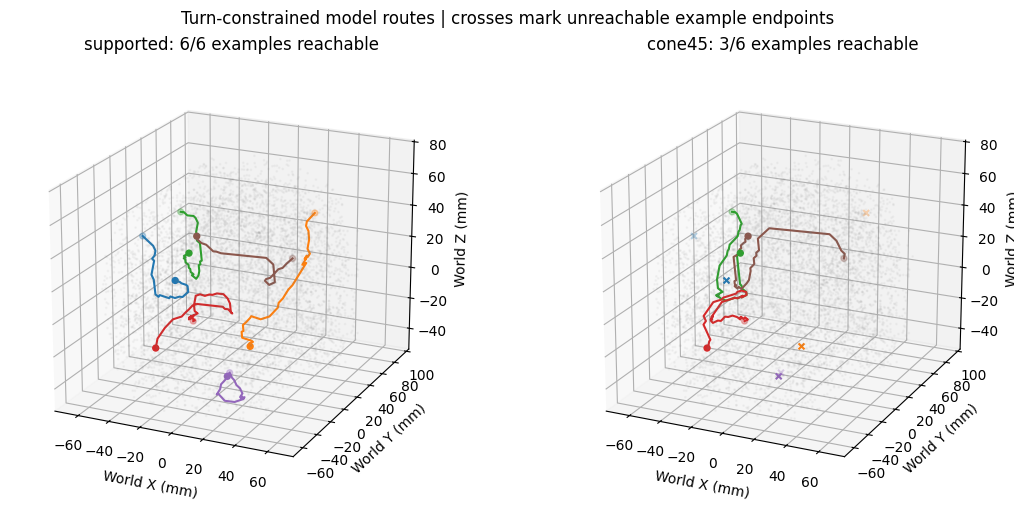


Route summary (cost ratios condition on reachable pairs):
    graph  pairs  reachable_pairs  reachable_fraction  median_cost_over_baseline  seconds
supported   2016             1830            0.907738                   1.176835     12.4
   cone45   2016             1131            0.561012                   1.550194      3.4

Unchanged preview-pair checks:
    graph  preview_pair  source_landmark  target_landmark  reachable  baseline_mm    path_mm  edges  max_step_turn_deg  turns_over_90_deg  tck_streamline_index
supported             0                0               32       True    49.312250  90.675117   34.0          60.000000                0.0                   0.0
supported             1                1               33       True   144.087143 168.394729   65.0          54.735610                0.0                   1.0
supported             2                2               34       True    55.019721 115.796073   45.0          54.735610                0.0                   2.0

In [6]:
# Cell 6: Turn-constrained routes on the existing orientation graphs.
# Graph-model paths only. No FSL, tracking rerun, or hyperbolicity test.

from pathlib import Path
from time import perf_counter
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import dijkstra

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results/cell04_orientation_graph"
PREV = ROOT / "results/cell05_path_geometry"
MAX_TURN_DEG = 60.0  # Exploratory model parameter, not a physiological estimate.
OUT6 = ROOT / "results" / f"cell06_turn{MAX_TURN_DEG:g}_paths"
OUT6.mkdir(parents=True, exist_ok=True)
NAMES = ("supported", "cone45")


def build_turn_graph(G, xyz, max_turn_deg):
    # State e means: the last step was tail[e] -> head[e].
    G = G.tocsr().astype(np.float64)
    G.sort_indices()
    if (G != G.T).nnz or not np.isfinite(G.data).all() or np.any(G.data <= 0):
        raise ValueError("Expected symmetric positive edge lengths.")
    degree = np.diff(G.indptr)
    tail = np.repeat(np.arange(G.shape[0], dtype=np.int32), degree)
    head = G.indices.copy()
    step = xyz[head] - xyz[tail]
    length = np.linalg.norm(step, axis=1)
    if np.any(length <= 0) or not np.allclose(length, G.data, atol=1e-4):
        raise ValueError("Graph weights must equal physical step lengths.")
    unit = step / length[:, None]
    rows, cols = [], []
    threshold = np.cos(np.radians(max_turn_deg))
    for slot in range(int(degree.max(initial=0))):
        e = np.flatnonzero(degree[head] > slot)
        f = G.indptr[head[e]] + slot
        # Signed spatial step angle: do NOT take the absolute dot product.
        keep = np.einsum("ij,ij->i", unit[e], unit[f]) >= threshold - 1e-8
        rows.append(e[keep])
        cols.append(f[keep])
    r = np.concatenate(rows) if rows else np.empty(0, dtype=int)
    c = np.concatenate(cols) if cols else np.empty(0, dtype=int)
    H = sparse.csr_matrix((G.data[c], (r, c)), shape=(G.nnz, G.nnz))
    return G, H, tail, head


def route_from_source(G, H, source):
    # A temporary source pays the FIRST edge length as well.
    lo, hi = G.indptr[source:source + 2]
    starts = np.arange(lo, hi, dtype=H.indices.dtype)
    m = H.shape[0]
    augmented = sparse.csr_matrix((
        np.concatenate((H.data, G.data[lo:hi])),
        np.concatenate((H.indices, starts)),
        np.concatenate((H.indptr, [H.nnz + len(starts)])),
    ), shape=(m + 1, m + 1))
    return dijkstra(augmented, directed=True, indices=m, return_predecessors=True)


def recover_nodes(pred, state, tail, head):
    states = []
    super_source = len(head)
    while state != super_source:
        if state < 0 or len(states) >= len(head):
            raise ValueError("Invalid predecessor chain.")
        states.append(int(state))
        state = int(pred[state])
    states = states[::-1]
    return np.r_[tail[states[0]], head[states]]


def route_stats(points):
    steps = np.diff(points, axis=0)
    lengths = np.linalg.norm(steps, axis=1)
    unit = steps / lengths[:, None]
    turns = np.degrees(np.arccos(np.clip(
        np.einsum("ij,ij->i", unit[:-1], unit[1:]), -1, 1
    )))
    return lengths.sum(), turns.max(initial=0), np.count_nonzero(turns > 90.001)


def triangle_qc(C):
    # Free endpoint orientations can break the triangle inequality.
    ii, jj = np.triu_indices(len(C), 1)
    tested = violations = unreachable_via_middle = 0
    max_excess = 0.0
    for k in range(len(C)):
        via = C[ii, k] + C[k, jj]
        valid = (ii != k) & (jj != k) & np.isfinite(via)
        unreachable_via_middle += int(np.sum(valid & ~np.isfinite(C[ii, jj])))
        finite = valid & np.isfinite(C[ii, jj])
        excess = C[ii[finite], jj[finite]] - via[finite]
        tested += len(excess)
        violations += int(np.sum(excess > 1e-3))
        max_excess = max(max_excess, float(excess.max(initial=0)))
    return dict(finite_triangle_checks=tested, finite_violations=violations,
                unreachable_despite_two_finite_legs=unreachable_via_middle,
                max_excess_mm=max_excess)


landmarks = pd.read_csv(PREV / "landmarks.csv").sort_values("landmark_id")
n = len(landmarks)
if not np.array_equal(landmarks.landmark_id, np.arange(n)):
    raise ValueError("Unexpected landmark ordering.")
with np.load(PREV / "landmark_distances.npz") as z:
    baseline = {name: z[f"{name}_mm"].copy() for name in NAMES}
    E = z["euclidean_mm"].copy()
    landmark_xyz = z["world_xyz_mm"].copy()
    if not np.array_equal(z["base_node_id"], landmarks.base_node_id):
        raise ValueError("Cell 5 landmark files do not match.")
old_meta = json.loads((PREV / "metadata.json").read_text())
preview_pairs = [tuple(p) for p in old_meta["preview_pairs"]]
ii, jj = np.triu_indices(n, 1)
print(f"Fixed turn cap: {MAX_TURN_DEG:g} degrees")
print(f"Unchanged landmarks: {n} | pairs: {len(ii):,}")
costs, previews, summary, preview_rows, metric_rows = {}, {}, [], [], []

for name in NAMES:
    start = perf_counter()
    ids = landmarks[f"{name}_node_id"].to_numpy(dtype=int)
    with np.load(SRC / f"nodes_{name}.npz") as z:
        xyz = z["world_xyz_mm"].astype(np.float64)
        if not np.array_equal(z["base_node_id"][ids], landmarks.base_node_id):
            raise ValueError("Cell 4 and Cell 5 node mappings differ.")
    if not np.allclose(xyz[ids], landmark_xyz, atol=1e-5):
        raise ValueError("Landmark coordinates differ.")
    G, H, tail, head = build_turn_graph(
        sparse.load_npz(SRC / f"edge_lengths_{name}.npz"), xyz, MAX_TURN_DEG
    )
    print(f"\n{name}: {H.shape[0]:,} step states, {H.nnz:,} allowed transitions", flush=True)
    incoming = [np.flatnonzero(head == node) for node in ids]
    C = np.full((n, n), np.inf)
    previews[name] = {}
    for s, source in enumerate(ids):
        d, pred = route_from_source(G, H, int(source))
        for t, states in enumerate(incoming):
            if len(states):
                C[s, t] = d[states].min()
        C[s, s] = 0.0
        for pair_id, (a, b) in enumerate(preview_pairs):
            if a != s:
                continue
            row = dict(graph=name, preview_pair=pair_id, source_landmark=a,
                       target_landmark=b, reachable=bool(np.isfinite(C[a, b])),
                       baseline_mm=float(baseline[name][a, b]), path_mm=C[a, b],
                       edges=np.nan, max_step_turn_deg=np.nan, turns_over_90_deg=np.nan,
                       tck_streamline_index=np.nan)
            if row["reachable"]:
                states = incoming[b]
                last = states[np.argmin(d[states])]
                path = recover_nodes(pred, int(last), tail, head)
                points = xyz[path]
                length, turn, reversals = route_stats(points)
                if path[0] != source or path[-1] != ids[b]:
                    raise ValueError("Incorrect route endpoints.")
                if not np.isclose(length, C[a, b], atol=1e-3, rtol=1e-6):
                    raise ValueError("Route and search costs differ.")
                if turn > MAX_TURN_DEG + 1e-3:
                    raise ValueError("A route violates the turn cap.")
                row.update(edges=len(path)-1, max_step_turn_deg=float(turn),
                           turns_over_90_deg=int(reversals),
                           tck_streamline_index=len(previews[name]))
                previews[name][pair_id] = points.astype(np.float32)
            preview_rows.append(row)
        if (s + 1) % 8 == 0 or s + 1 == n:
            print(f"  Sources finished: {s + 1}/{n}", flush=True)
    finite = np.isfinite(C)
    if not np.array_equal(finite, finite.T) or not np.allclose(C[finite], C.T[finite], atol=1e-3):
        raise ValueError("Reverse-route symmetry failed.")
    if np.any(C < baseline[name] - 1e-3) or np.any(C < E - 1e-3):
        raise ValueError("A constrained route is shorter than its lower bound.")
    costs[name] = C
    reachable = np.isfinite(C[ii, jj])
    ratios = C[ii[reachable], jj[reachable]] / baseline[name][ii[reachable], jj[reachable]]
    summary.append(dict(graph=name, pairs=len(ii), reachable_pairs=int(reachable.sum()),
                        reachable_fraction=float(reachable.mean()),
                        median_cost_over_baseline=float(np.median(ratios)) if len(ratios) else np.nan,
                        seconds=round(perf_counter()-start, 1)))
    metric_rows.append(dict(graph=name, **triangle_qc(C)))
    # Empty tractograms are valid when none of the preselected examples is reachable.
    nib.streamlines.save(nib.streamlines.Tractogram(
        list(previews[name].values()), affine_to_rasmm=np.eye(4)
    ), str(OUT6 / f"model_turn_constrained_{name}.tck"))
    del G, H, tail, head, d, pred, incoming

C0, C1 = (costs[name] for name in NAMES)
if np.any(np.isfinite(C1) & ~np.isfinite(C0)) or np.any(C1 < C0 - 1e-3):
    raise ValueError("The restricted graph improved reachability or route cost.")
summary = pd.DataFrame(summary)
path_qc = pd.DataFrame(preview_rows)
metric_qc = pd.DataFrame(metric_rows)
summary.to_csv(OUT6 / "route_summary.csv", index=False)
path_qc.to_csv(OUT6 / "preview_path_qc.csv", index=False)
metric_qc.to_csv(OUT6 / "endpoint_triangle_qc.csv", index=False)
landmarks.to_csv(OUT6 / "landmarks.csv", index=False)
np.savez_compressed(OUT6 / "landmark_path_costs.npz", supported_mm=C0, cone45_mm=C1,
                    euclidean_mm=E, base_node_id=landmarks.base_node_id.to_numpy(),
                    world_xyz_mm=landmark_xyz, max_turn_deg=MAX_TURN_DEG)
pairs = pd.DataFrame(dict(landmark_a=ii, landmark_b=jj, euclidean_mm=E[ii, jj]))
for name in NAMES:
    pairs[f"{name}_baseline_mm"] = baseline[name][ii, jj]
    pairs[f"{name}_constrained_mm"] = costs[name][ii, jj]
    pairs[f"{name}_reachable"] = np.isfinite(costs[name][ii, jj])
pairs.to_csv(OUT6 / "pair_path_costs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, name in zip(axes, NAMES):
    valid = np.isfinite(costs[name][ii, jj])
    x, y = baseline[name][ii[valid], jj[valid]], costs[name][ii[valid], jj[valid]]
    ax.scatter(x, y, s=7, alpha=0.35)
    lim = max(float(x.max(initial=0)), float(y.max(initial=0)), 1)
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set(title=f"{name}: {valid.sum()}/{len(ii)} pairs reachable",
           xlabel="Unconstrained graph distance (mm)", ylabel="Constrained path cost (mm)")
fig.suptitle(f"Same endpoints | maximum spatial step turn {MAX_TURN_DEG:g} degrees")
fig.savefig(OUT6 / "route_cost_comparison.png", dpi=180)

with np.load(SRC / "nodes_supported.npz") as z:
    context = z["world_xyz_mm"]
cloud = context[np.random.default_rng(8).choice(len(context), min(6000, len(context)), replace=False)]
low, high = context.min(axis=0), context.max(axis=0)
fig2 = plt.figure(figsize=(11, 5), constrained_layout=True)
for panel, name in enumerate(NAMES, 1):
    ax = fig2.add_subplot(1, 2, panel, projection="3d")
    ax.scatter(*cloud.T, s=1, color="gray", alpha=0.05)
    for pair_id, (a, b) in enumerate(preview_pairs):
        points = previews[name].get(pair_id)
        if points is not None:
            ax.plot(*points.T, color=f"C{pair_id}", lw=1.5)
        ax.scatter(*landmark_xyz[[a, b]].T, color=f"C{pair_id}",
                   marker="o" if points is not None else "x", s=18)
    ax.set(title=f"{name}: {len(previews[name])}/{len(preview_pairs)} examples reachable",
           xlabel="World X (mm)", ylabel="World Y (mm)", zlabel="World Z (mm)",
           xlim=(low[0], high[0]), ylim=(low[1], high[1]), zlim=(low[2], high[2]))
    ax.set_box_aspect(np.maximum(high-low, 1))
    ax.view_init(elev=20, azim=-65)
fig2.suptitle("Turn-constrained model routes | crosses mark unreachable example endpoints")
fig2.savefig(OUT6 / "turn_constrained_preview.png", dpi=180)
plt.show()

(OUT6 / "metadata.json").write_text(json.dumps(dict(
    max_turn_deg=MAX_TURN_DEG, source_graph_directory=str(SRC), baseline_directory=str(PREV),
    routing="Directed previous-edge states; physical step lengths; first edge included",
    endpoint_conditioning="Unchanged Cell 5 common-LCC landmarks; free initial/final heading",
    preview_pairs=preview_pairs, unreachable_value="positive infinity; never imputed",
    interpretation="Model path QC only; endpoint costs are not guaranteed to be a metric",
    triangle_qc="Only the selected landmarks; passing is not a proof for all graph nodes",
), indent=2), encoding="utf-8")
print("\nRoute summary (cost ratios condition on reachable pairs):")
print(summary.to_string(index=False))
print("\nUnchanged preview-pair checks:")
print(path_qc.to_string(index=False))
print("\nEndpoint triangle-inequality checks:")
print(metric_qc.to_string(index=False))
print("\nThese endpoint costs are not automatically a metric. No hyperbolicity test was run.")
print(f"Saved: {OUT6}")

Formula checks passed: line delta = 0; unit-edge four-cycle delta = 1.
Unchanged landmarks: 64 | pairs: 2,016

supported spatial reference: 132,271 voxels, 1,270,273 edges
  Sources finished: 16/64
  Sources finished: 32/64
  Sources finished: 48/64
  Sources finished: 64/64

cone45 spatial reference: 78,481 voxels, 598,178 edges
  Sources finished: 16/64
  Sources finished: 32/64
  Sources finished: 48/64
  Sources finished: 64/64


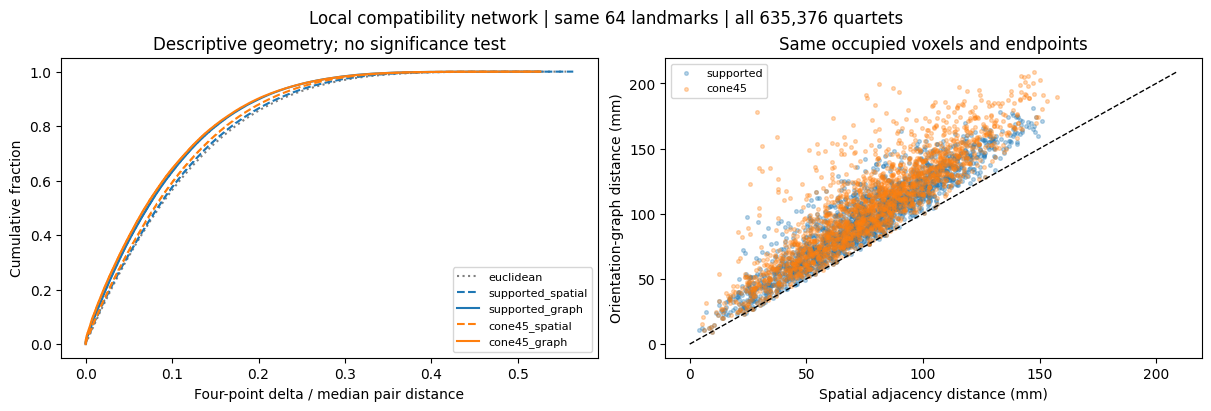


Spatial reference checks:
    graph  spatial_voxels  spatial_edges  median_graph_over_spatial  seconds
supported          132271        1270273                   1.254017      9.8
   cone45           78481         598178                   1.333028      4.8

Matched four-point summary:
           metric  landmarks  quartets  triangle_excess_mm  median_pair_mm  subset_diameter_mm  delta_subset_mm  delta_subset_over_diameter  p95_delta_over_median_pair
        euclidean         64    635376        7.105427e-15       66.015149          137.840488        36.690690                    0.266182                    0.271963
supported_spatial         64    635376        1.563194e-13       74.094190          151.179341        41.803848                    0.276518                    0.265443
  supported_graph         64    635376        0.000000e+00       94.999754          181.477208        50.145535                    0.276319                    0.244026
   cone45_spatial         64    635376   

In [7]:
# Cell 7: Four-point screening of the LOCAL ORIENTATION-COMPATIBILITY NETWORK.
# Uses Cell 5 graph distances, not Cell 6 turn-constrained endpoint costs.
# Spatial references keep occupied voxels but remove orientation constraints.

from pathlib import Path
from itertools import combinations, product
from math import comb
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import dijkstra

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results/cell04_orientation_graph"
PREV = ROOT / "results/cell05_path_geometry"
OUT7 = ROOT / "results/cell07_network_geometry"
OUT7.mkdir(parents=True, exist_ok=True)
NAMES = ("supported", "cone45")

landmarks = pd.read_csv(PREV / "landmarks.csv").sort_values("landmark_id")
n = len(landmarks)
if not np.array_equal(landmarks.landmark_id, np.arange(n)):
    raise ValueError("Unexpected landmark ordering.")

with np.load(PREV / "landmark_distances.npz") as z:
    if not np.array_equal(z["base_node_id"], landmarks.base_node_id):
        raise ValueError("Cell 5 landmark files do not match.")
    E = z["euclidean_mm"].copy()
    landmark_xyz = z["world_xyz_mm"].copy()
    network = {name: z[f"{name}_mm"].copy() for name in NAMES}

if not 4 <= n <= 64:
    raise ValueError("This exhaustive pilot expects 4 to 64 saved landmarks.")
p, q = np.triu_indices(n, 1)


def spatial_reference(ijk, xyz):
    # Collapse multiple orientation nodes at the same voxel.
    vox, first, inverse = np.unique(
        ijk, axis=0, return_index=True, return_inverse=True
    )
    points = xyz[first]
    shape = vox.max(axis=0) + 1
    lookup = np.full(tuple(shape), -1, dtype=np.int32)
    lookup[tuple(vox.T)] = np.arange(len(vox), dtype=np.int32)

    rows, cols, weights = [], [], []
    for offset in product((-1, 0, 1), repeat=3):
        if offset <= (0, 0, 0):
            continue
        neighbor = vox + offset
        valid = np.all((neighbor >= 0) & (neighbor < shape), axis=1)
        a = np.flatnonzero(valid)
        b = lookup[tuple(neighbor[valid].T)]
        exists = b >= 0
        a, b = a[exists], b[exists]
        rows.append(a)
        cols.append(b)
        weights.append(np.linalg.norm(points[a] - points[b], axis=1))

    a = np.concatenate(rows)
    b = np.concatenate(cols)
    w = np.concatenate(weights)
    S = sparse.csr_matrix(
        (np.r_[w, w], (np.r_[a, b], np.r_[b, a])),
        shape=(len(vox), len(vox)),
    )
    return S, inverse


def metric_checks(D):
    if not np.isfinite(D).all() or not np.allclose(D, D.T, atol=1e-5):
        raise ValueError("Expected a finite symmetric matrix.")
    a, b = np.triu_indices(len(D), 1)
    if np.any(D[a, b] <= 0) or not np.allclose(np.diag(D), 0):
        raise ValueError("Invalid diagonal or nonpositive off-diagonal distance.")

    excess = max(
        float(np.max(D - D[:, k, None] - D[k, None, :]))
        for k in range(len(D))
    )
    if excess > 1e-3:
        raise ValueError(f"Triangle inequality failed by {excess:.6f} mm.")
    return max(excess, 0.0)


def four_point_delta(D, quartets):
    a, b, c, d = quartets.T
    sums = np.sort(
        np.column_stack((
            D[a, b] + D[c, d],
            D[a, c] + D[b, d],
            D[a, d] + D[b, c],
        )),
        axis=1,
    )
    return (sums[:, 2] - sums[:, 1]) / 2


# Known cases verify the factor of two and distinguish a line from a cycle.
line = np.abs(np.arange(4)[:, None] - np.arange(4)[None, :]).astype(float)
cycle = np.minimum(line, 4 - line)
test_quartet = np.array([[0, 1, 2, 3]])
assert np.allclose(four_point_delta(line, test_quartet), 0)
assert np.allclose(four_point_delta(cycle, test_quartet), 1)

print("Formula checks passed: line delta = 0; unit-edge four-cycle delta = 1.")
print(f"Unchanged landmarks: {n} | pairs: {len(p):,}")

metrics, reference_rows = {"euclidean": E}, []
for name in NAMES:
    start = perf_counter()
    with np.load(SRC / f"nodes_{name}.npz") as z:
        ijk = z["ijk"].copy()
        xyz = z["world_xyz_mm"].astype(float)
        ids = landmarks[f"{name}_node_id"].to_numpy(dtype=int)
        if not np.array_equal(z["base_node_id"][ids], landmarks.base_node_id):
            raise ValueError("Cell 4 and Cell 5 node mappings differ.")

    if not np.allclose(xyz[ids], landmark_xyz, atol=1e-5):
        raise ValueError("Landmark coordinates differ.")

    S, inverse = spatial_reference(ijk, xyz)
    targets = inverse[ids]
    if len(np.unique(targets)) != n:
        raise ValueError("Landmarks must occupy distinct voxels.")

    print(
        f"\n{name} spatial reference: "
        f"{S.shape[0]:,} voxels, {S.nnz // 2:,} edges",
        flush=True,
    )

    D = np.empty((n, n))
    for k, source in enumerate(targets):
        D[k] = dijkstra(S, directed=False, indices=int(source))[targets]
        if (k + 1) % 16 == 0 or k + 1 == n:
            print(f"  Sources finished: {k + 1}/{n}", flush=True)

    metric_checks(D)
    if np.any(D < E - 1e-3) or np.any(D > network[name] + 1e-3):
        raise ValueError(
            "Expected Euclidean <= spatial <= orientation-graph distance."
        )

    metrics[f"{name}_spatial"] = D
    metrics[f"{name}_graph"] = network[name]
    reference_rows.append(dict(
        graph=name,
        spatial_voxels=S.shape[0],
        spatial_edges=S.nnz // 2,
        median_graph_over_spatial=float(
            np.median(network[name][p, q] / D[p, q])
        ),
        seconds=round(perf_counter() - start, 1),
    ))
    del S, inverse, ijk, xyz

if np.any(metrics["cone45_spatial"] < metrics["supported_spatial"] - 1e-3):
    raise ValueError("Removing occupied voxels shortened a spatial route.")

# Enumerate all quartets of these landmarks, not of the full brain graph.
quartets = np.fromiter(
    (v for four in combinations(range(n), 4) for v in four),
    dtype=np.int16,
    count=4 * comb(n, 4),
).reshape(-1, 4)

rows, deltas = [], {}
for name, D in metrics.items():
    error = metric_checks(D)
    delta = four_point_delta(D, quartets)
    diameter = D[p, q].max()
    median_pair = np.median(D[p, q])
    deltas[name] = delta

    rows.append(dict(
        metric=name,
        landmarks=n,
        quartets=len(quartets),
        triangle_excess_mm=error,
        median_pair_mm=median_pair,
        subset_diameter_mm=diameter,
        delta_subset_mm=delta.max(),
        delta_subset_over_diameter=delta.max() / diameter,
        p95_delta_over_median_pair=np.percentile(delta, 95) / median_pair,
    ))

summary = pd.DataFrame(rows)
references = pd.DataFrame(reference_rows)
summary.to_csv(OUT7 / "four_point_summary.csv", index=False)
references.to_csv(OUT7 / "spatial_reference_qc.csv", index=False)

np.savez_compressed(
    OUT7 / "matched_metrics.npz",
    **metrics,
    base_node_id=landmarks.base_node_id.to_numpy(),
    world_xyz_mm=landmark_xyz,
)
np.savez_compressed(
    OUT7 / "four_point_values.npz",
    quartet_indices=quartets,
    **deltas,
)
landmarks.to_csv(OUT7 / "landmarks.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
styles = {
    "euclidean": ("gray", ":"),
    "supported_spatial": ("C0", "--"),
    "supported_graph": ("C0", "-"),
    "cone45_spatial": ("C1", "--"),
    "cone45_graph": ("C1", "-"),
}

for name, D in metrics.items():
    values = np.sort(deltas[name] / np.median(D[p, q]))
    index = np.unique(
        np.linspace(0, len(values) - 1, min(2000, len(values))).astype(int)
    )
    color, style = styles[name]
    axes[0].plot(
        values[index], (index + 1) / len(values),
        color=color, ls=style, label=name,
    )

for name in NAMES:
    axes[1].scatter(
        metrics[f"{name}_spatial"][p, q],
        metrics[f"{name}_graph"][p, q],
        s=7, alpha=0.3, label=name,
    )

lim = max(network[name].max() for name in NAMES)
axes[1].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set(
    xlabel="Four-point delta / median pair distance",
    ylabel="Cumulative fraction",
    title="Descriptive geometry; no significance test",
)
axes[1].set(
    xlabel="Spatial adjacency distance (mm)",
    ylabel="Orientation-graph distance (mm)",
    title="Same occupied voxels and endpoints",
)
for ax in axes:
    ax.legend(fontsize=8)

fig.suptitle(
    f"Local compatibility network | same {n} landmarks | "
    f"all {len(quartets):,} quartets"
)
fig.savefig(OUT7 / "network_geometry_screen.png", dpi=180)
plt.show()

metadata = dict(
    source_graphs=str(SRC),
    source_distances=str(PREV),
    landmarks=n,
    endpoints="Original Cell 5 endpoints; no replacements or exclusions",
    spatial_reference=(
        "26-neighbor occupied-voxel graph; "
        "no orientation or component distinction"
    ),
    weights="Physical edge lengths in millimeters",
    four_point=(
        "Half the difference between the largest two opposing distance sums"
    ),
    scope="Exact delta on selected landmarks; lower bound on full-graph delta only",
    normalization=(
        "Maximum delta/subset diameter and quartet deltas/median pair distance"
    ),
    interpretation=(
        "Local orientation-compatibility network, not anatomical fiber trajectories"
    ),
    limitations=(
        "Endpoints conditioned on common LCC; "
        "degree changes in spatial references; no null ensemble"
    ),
    inference=(
        "Descriptive pilot; overlapping quartets are not independent "
        "biological replicates; no p-values"
    ),
    excluded_input=(
        "Cell 6 endpoint costs violate triangle inequalities and are not used"
    ),
)
(OUT7 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("\nSpatial reference checks:")
print(references.to_string(index=False))
print("\nMatched four-point summary:")
print(summary.to_string(index=False))
print("\nSmall normalized delta alone is not evidence of biological hyperbolicity.")
print(f"Saved: {OUT7}")

Fixed landmarks: 64 | pairs: 2,016 | pair CV folds: 5
supported: endpoint omissions 16/64
supported: endpoint omissions 32/64
supported: endpoint omissions 48/64
supported: endpoint omissions 64/64
cone45: endpoint omissions 16/64
cone45: endpoint omissions 32/64
cone45: endpoint omissions 48/64
cone45: endpoint omissions 64/64


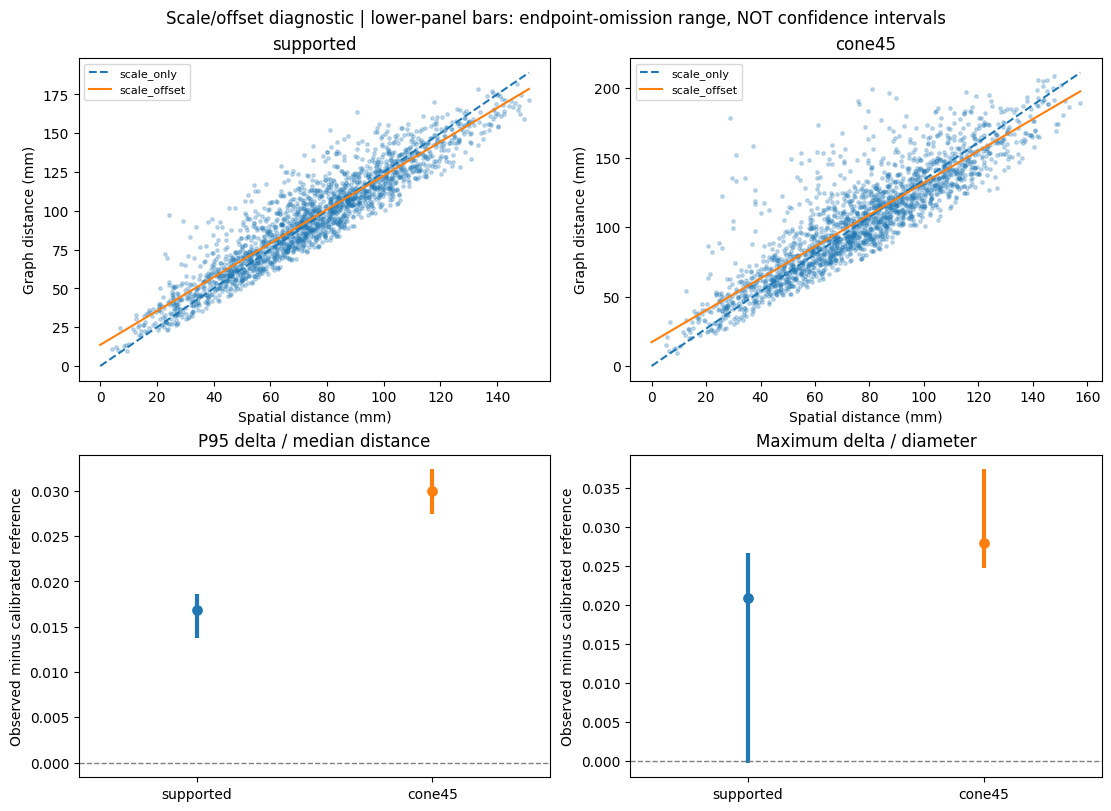


Distance calibration (CV predicts held-out pairs among the same landmarks):
    graph        model  full_fit_scale  full_fit_offset_mm  pair_cv_RMSE_mm  pair_cv_MAE_mm  pair_cv_nRMSE
supported   scale_only        1.250524            0.000000        12.901758        9.682236       0.135808
supported scale_offset        1.090905           13.618198        11.965148        9.137537       0.125949
   cone45   scale_only        1.341877            0.000000        18.923740       13.343440       0.178947
   cone45 scale_offset        1.147412           17.149803        17.937039       12.987718       0.169617

Geometry after calibration (LOO ranges are sensitivity checks, not CIs):
    graph                      score  spatial  scale_offset_reference  observed  observed_minus_spatial  observed_minus_reference   LOO_min  LOO_max
supported p95_delta_over_median_pair 0.265443                0.227169  0.244026               -0.021417                  0.016857  0.013802 0.018637
supported       

In [8]:
# Cell 8: Scale/offset calibration and leave-one-landmark-out sensitivity.
# Saved matrices only. No tracking, graph rebuilding, or significance claims.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import nnls

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results/cell07_network_geometry"
OUT8 = ROOT / "results/cell08_scale_offset_check"
OUT8.mkdir(parents=True, exist_ok=True)
NAMES = ("supported", "cone45")
SEED, FOLDS = 7, 5

with np.load(SRC / "matched_metrics.npz") as z:
    distances = {name: z[name].copy() for name in (
        "supported_spatial", "supported_graph",
        "cone45_spatial", "cone45_graph",
    )}
    base_ids = z["base_node_id"].copy()

with np.load(SRC / "four_point_values.npz") as z:
    quartets = z["quartet_indices"].copy()
    deltas = {name: z[name].copy() for name in distances}

n = len(base_ids)
p, q = np.triu_indices(n, 1)
fold = np.empty(len(p), dtype=int)
fold[np.random.default_rng(SEED).permutation(len(p))] = (
    np.arange(len(p)) % FOLDS
)


def fit_reference(x, y, with_offset):
    scale = np.median(x)
    X = (x / scale)[:, None]
    if with_offset:
        X = np.column_stack((X, np.ones(len(x))))
    beta = nnls(X, y)[0]
    return float(beta[0] / scale), float(beta[1]) if with_offset else 0.0


def geometry_scores(x, y, ds, dg, a, b):
    # Adding b to every off-diagonal distance adds 2b to each opposing
    # sum. Therefore delta(a*S+b) = a*delta(S) for distinct points.
    s95, g95 = np.percentile(ds, 95), np.percentile(dg, 95)
    spatial = np.array([
        s95 / np.median(x),
        ds.max() / x.max(),
    ])
    observed = np.array([
        g95 / np.median(y),
        dg.max() / y.max(),
    ])
    calibrated = np.array([
        a * s95 / (a * np.median(x) + b),
        a * ds.max() / (a * x.max() + b),
    ])
    return spatial, observed, calibrated


SCORES = ("p95_delta_over_median_pair", "delta_over_diameter")
fit_rows, geometry_rows, loo_rows, pair_tables = [], [], [], []
plot_data, calibrated_metrics = {}, {}

print(f"Fixed landmarks: {n} | pairs: {len(p):,} | pair CV folds: {FOLDS}")

for name in NAMES:
    S = distances[f"{name}_spatial"]
    G = distances[f"{name}_graph"]
    ds = deltas[f"{name}_spatial"]
    dg = deltas[f"{name}_graph"]
    x, y = S[p, q], G[p, q]

    if not np.isfinite(S).all() or not np.isfinite(G).all() or np.any(x <= 0):
        raise ValueError("Invalid saved distances.")

    # Verify that saved quartet values match these distance matrices.
    indices = np.linspace(
        0, len(quartets) - 1, min(256, len(quartets))
    ).astype(int)
    check = quartets[indices]
    for D, stored in ((S, ds), (G, dg)):
        a0, b0, c0, d0 = check.T
        sums = np.sort(np.column_stack((
            D[a0, b0] + D[c0, d0],
            D[a0, c0] + D[b0, d0],
            D[a0, d0] + D[b0, c0],
        )), axis=1)
        expected = (sums[:, 2] - sums[:, 1]) / 2
        if not np.allclose(expected, stored[indices], atol=1e-5):
            raise ValueError("Saved metrics and quartet values do not match.")

    pairs = pd.DataFrame(dict(
        landmark_a=p, landmark_b=q, fold=fold,
        spatial_mm=x, observed_graph_mm=y, graph=name,
    ))
    params = {}

    # Predict held-out pairs. The same endpoints occur across folds.
    for model, with_offset in (
        ("scale_only", False),
        ("scale_offset", True),
    ):
        predicted = np.empty(len(x))
        for k in range(FOLDS):
            test = fold == k
            a, b = fit_reference(x[~test], y[~test], with_offset)
            predicted[test] = a * x[test] + b

        a, b = fit_reference(x, y, with_offset)
        params[model] = (a, b)
        residual = predicted - y
        rmse = float(np.sqrt(np.mean(residual ** 2)))

        fit_rows.append(dict(
            graph=name,
            model=model,
            full_fit_scale=a,
            full_fit_offset_mm=b,
            pair_cv_RMSE_mm=rmse,
            pair_cv_MAE_mm=float(np.mean(np.abs(residual))),
            pair_cv_nRMSE=rmse / np.median(y),
        ))
        pairs[f"{model}_out_of_fold_mm"] = predicted

    pair_tables.append(pairs)
    a, b = params["scale_offset"]

    # Full-data reference is a metric; mixed out-of-fold predictions
    # are NOT used as a distance matrix for geometry.
    calibrated_metrics[name] = a * S + b * (1 - np.eye(n))
    spatial, observed, calibrated = geometry_scores(x, y, ds, dg, a, b)

    full_rows = []
    for k, score in enumerate(SCORES):
        full_rows.append(dict(
            graph=name,
            score=score,
            spatial=spatial[k],
            scale_offset_reference=calibrated[k],
            observed=observed[k],
            observed_minus_spatial=observed[k] - spatial[k],
            observed_minus_reference=observed[k] - calibrated[k],
        ))

    # Drop an endpoint from the measurement set, not from the graph.
    # Refit the reference on the remaining pairs each time.
    sensitivity = []
    for omitted in range(n):
        keep_pairs = (p != omitted) & (q != omitted)
        keep_quartets = np.all(quartets != omitted, axis=1)
        xx, yy = x[keep_pairs], y[keep_pairs]
        aa, bb = fit_reference(xx, yy, True)
        ss, gg, cc = geometry_scores(
            xx, yy, ds[keep_quartets], dg[keep_quartets], aa, bb
        )
        sensitivity.append(gg - cc)

        for k, score in enumerate(SCORES):
            loo_rows.append(dict(
                graph=name,
                omitted_landmark=omitted,
                omitted_base_node_id=int(base_ids[omitted]),
                score=score,
                refit_scale=aa,
                refit_offset_mm=bb,
                observed_minus_spatial=gg[k] - ss[k],
                observed_minus_reference=gg[k] - cc[k],
            ))
        if (omitted + 1) % 16 == 0 or omitted + 1 == n:
            print(
                f"{name}: endpoint omissions {omitted + 1}/{n}",
                flush=True,
            )

    sensitivity = np.asarray(sensitivity)
    for k, row in enumerate(full_rows):
        row.update(
            LOO_min=float(sensitivity[:, k].min()),
            LOO_max=float(sensitivity[:, k].max()),
        )
    geometry_rows.extend(full_rows)
    plot_data[name] = (x, y, params)

fits = pd.DataFrame(fit_rows)
geometry = pd.DataFrame(geometry_rows)
fits.to_csv(OUT8 / "distance_reference_fits.csv", index=False)
geometry.to_csv(OUT8 / "geometry_calibration_summary.csv", index=False)
pd.DataFrame(loo_rows).to_csv(
    OUT8 / "landmark_sensitivity.csv", index=False
)
pd.concat(pair_tables, ignore_index=True).to_csv(
    OUT8 / "heldout_pair_predictions.csv", index=False
)
np.savez_compressed(
    OUT8 / "calibrated_reference_metrics.npz",
    **calibrated_metrics,
    base_node_id=base_ids,
)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)

for ax, name in zip(axes[0], NAMES):
    x, y, params = plot_data[name]
    ax.scatter(x, y, s=6, alpha=0.25)
    xx = np.linspace(0, x.max(), 100)
    for model, style in (("scale_only", "--"), ("scale_offset", "-")):
        a, b = params[model]
        ax.plot(xx, a * xx + b, ls=style, label=model)
    ax.set(
        title=name,
        xlabel="Spatial distance (mm)",
        ylabel="Graph distance (mm)",
    )
    ax.legend(fontsize=8)

for k, ax in enumerate(axes[1]):
    for j, name in enumerate(NAMES):
        row = geometry[
            (geometry.graph == name) & (geometry.score == SCORES[k])
        ].iloc[0]
        ax.vlines(j, row.LOO_min, row.LOO_max, color=f"C{j}", lw=3)
        ax.scatter(
            j, row.observed_minus_reference,
            color=f"C{j}", s=45, zorder=3,
        )
    ax.axhline(0, color="gray", ls="--", lw=1)
    ax.set(
        xticks=range(2),
        xticklabels=NAMES,
        xlim=(-0.5, 1.5),
        ylabel="Observed minus calibrated reference",
        title=(
            "P95 delta / median distance"
            if k == 0 else "Maximum delta / diameter"
        ),
    )

fig.suptitle(
    "Scale/offset diagnostic | lower-panel bars: "
    "endpoint-omission range, NOT confidence intervals"
)
fig.savefig(OUT8 / "scale_offset_diagnostic.png", dpi=180)
plt.show()

metadata = dict(
    source=str(SRC),
    seed=SEED,
    folds=FOLDS,
    reference="a*S_ij+b for i!=j; zero diagonal; a,b>=0",
    fitting=(
        "Nonnegative least squares on pair distances, "
        "not on hyperbolicity scores"
    ),
    CV=(
        "Same held-out pairs for both models; endpoints shared across folds; "
        "no new-subject generalization"
    ),
    geometry=(
        "Full-data fitted reference; "
        "out-of-fold predictions are never used as a metric"
    ),
    sensitivity=(
        "Leave one sampled landmark out, retain graph paths, "
        "refit reference; ranges are not CIs"
    ),
    offset="Mathematical distance baseline, not an estimated biological cost",
    inference=(
        "Exploratory calibration, not a graph null ensemble "
        "or evidence of biological hyperbolicity"
    ),
)
(OUT8 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("\nDistance calibration (CV predicts held-out pairs among the same landmarks):")
print(fits.to_string(index=False))
print("\nGeometry after calibration (LOO ranges are sensitivity checks, not CIs):")
print(geometry.to_string(index=False))
print(f"\nSaved: {OUT8}")

Intrinsic dimension: 3 | landmarks: 64 | split seeds: (7, 17, 27)
Train/validation/test: 60/20/20%; two starts per fit; test distances excluded from selection.

supported, split 7: selecting curvature ...
  euclidean: selected curvature 0
  hyperbolic: selected curvature -4
  spherical: selected curvature 0.0625
  Finished split in 0.7 s

supported, split 17: selecting curvature ...
  euclidean: selected curvature 0
  hyperbolic: selected curvature -4
  spherical: selected curvature 0.0625
  Finished split in 0.9 s

supported, split 27: selecting curvature ...
  euclidean: selected curvature 0
  hyperbolic: selected curvature -4
  spherical: selected curvature 0.0625
  Finished split in 0.8 s

cone45, split 7: selecting curvature ...
  euclidean: selected curvature 0
  hyperbolic: selected curvature -4
  spherical: selected curvature 0.0625
  Finished split in 0.8 s

cone45, split 17: selecting curvature ...
  euclidean: selected curvature 0
  hyperbolic: selected curvature -4
  spheri

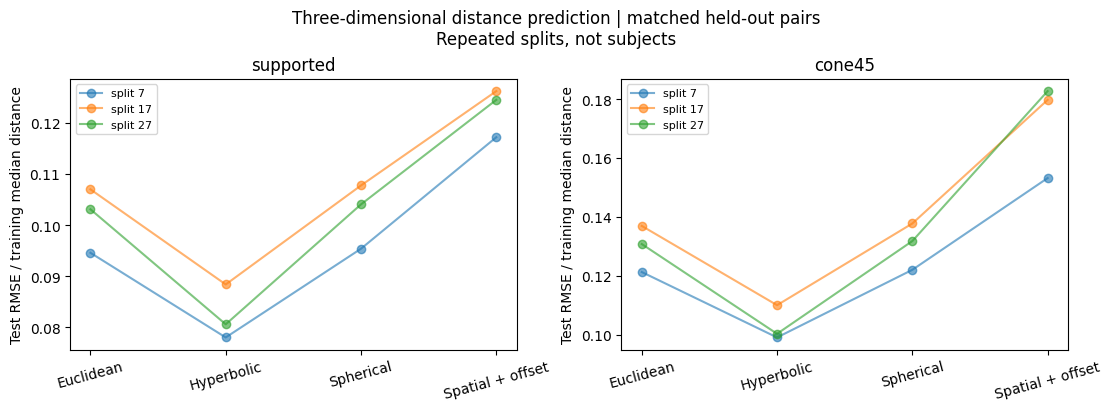


Held-out comparison (split SD is not a confidence interval):
    graph          model  mean_test_RMSE_mm  sd_across_splits_mm  mean_test_nRMSE  all_selected_fits_converged
supported      euclidean           9.660014             0.646834         0.101613                         True
supported     hyperbolic           7.831026             0.565643         0.082365                         True
supported      spherical           9.740174             0.646811         0.102457                         True
supported spatial_offset          11.665563             0.499843         0.122720                         True
   cone45      euclidean          13.675085             0.827290         0.129782                         True
   cone45     hyperbolic          10.882727             0.678009         0.103263                         True
   cone45      spherical          13.766358             0.830618         0.130649                         True
   cone45 spatial_offset          18.115498       

In [9]:
# Cell 9: Held-out distance prediction in E^3, H^3 and S^3.
# Same landmarks; no FSL, GPU, ROI aggregation or new tractography.

from pathlib import Path
from time import perf_counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, nnls
from scipy.sparse.csgraph import dijkstra

ROOT = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest")
SRC = ROOT / "results/cell07_network_geometry"
OUT9 = ROOT / "results/cell09_geometry_prediction"
OUT9.mkdir(parents=True, exist_ok=True)

DIM, MAXITER = 3, 600
SEEDS = (7, 17, 27)
CURVATURES = (0.0625, 0.25, 1.0, 4.0)
KINDS = ("euclidean", "hyperbolic", "spherical")
EPS = 1e-12
OPT_LOG = []


def pair_geometry(Z, kind, curvature, i, j):
    """Distances and derivatives with respect to both endpoints."""
    A, B = Z[i], Z[j]

    if kind == "euclidean":
        diff = A - B
        d = np.linalg.norm(diff, axis=1)
        grad = diff / np.maximum(d[:, None], EPS)
        return d, grad, -grad

    R = 1 / np.sqrt(abs(curvature))

    if kind == "hyperbolic":
        # Spatial Lorentz coordinates; time coordinate is implicit.
        ta = np.sqrt(R * R + np.sum(A * A, axis=1))
        tb = np.sqrt(R * R + np.sum(B * B, axis=1))
        raw = (ta * tb - np.sum(A * B, axis=1)) / (R * R)
        c = np.maximum(raw, 1 + EPS)

        factor = (raw > 1 + EPS) / (R * np.sqrt(c * c - 1))
        ga = ((tb / ta)[:, None] * A - B) * factor[:, None]
        gb = ((ta / tb)[:, None] * B - A) * factor[:, None]
        return R * np.arccosh(c), ga, gb

    # Normalized R^4 vectors represent the intrinsic 3-sphere.
    na = np.maximum(np.linalg.norm(A, axis=1), EPS)
    nb = np.maximum(np.linalg.norm(B, axis=1), EPS)
    U, V = A / na[:, None], B / nb[:, None]
    raw = np.sum(U * V, axis=1)
    c = np.clip(raw, -1 + EPS, 1 - EPS)

    factor = (
        -R * ((raw > -1 + EPS) & (raw < 1 - EPS))
        / np.sqrt(1 - c * c)
    )
    ga = (V - raw[:, None] * U) * (factor / na)[:, None]
    gb = (U - raw[:, None] * V) * (factor / nb)[:, None]
    return R * np.arccos(c), ga, gb


def stress_and_gradient(flat, shape, kind, curvature, i, j, target):
    Z = flat.reshape(shape)
    pred, gi, gj = pair_geometry(Z, kind, curvature, i, j)
    residual = pred - target
    weight = 2 * residual / len(target)

    gradient = np.zeros_like(Z)
    np.add.at(gradient, i, weight[:, None] * gi)
    np.add.at(gradient, j, weight[:, None] * gj)

    return float(np.mean(residual**2)), gradient.ravel()


def encode_start(X, kind, curvature):
    if kind == "euclidean":
        return X.copy()

    R = 1 / np.sqrt(abs(curvature))
    radius = np.linalg.norm(X, axis=1)
    unit = X / np.maximum(radius[:, None], EPS)
    angle = radius / R

    if kind == "hyperbolic":
        return R * np.sinh(angle)[:, None] * unit

    return np.column_stack((
        np.cos(angle),
        np.sin(angle)[:, None] * unit,
    ))


def training_starts(n, i, j, target, seed):
    # Initialization uses training distances only.
    W = np.zeros((n, n))
    W[i, j] = W[j, i] = target
    filled = dijkstra(W, directed=False)

    if not np.isfinite(filled).all():
        raise ValueError("Training-pair graph is disconnected.")

    J = np.eye(n) - np.ones((n, n)) / n
    values, vectors = np.linalg.eigh(-0.5 * J @ (filled**2) @ J)
    X = vectors[:, -DIM:] * np.sqrt(np.maximum(values[-DIM:], 0))
    random = np.random.default_rng(seed).normal(size=(n, DIM))

    starts = []
    for Z in (X, random):
        Z = Z - Z.mean(axis=0)
        current = np.linalg.norm(Z[i] - Z[j], axis=1)
        Z *= np.dot(current, target) / np.dot(current, current)
        starts.append(Z)

    return starts


def fit_best(starts, kind, curvature, i, j, target, context):
    fits = []

    for start_id, Z in enumerate(starts):
        result = minimize(
            stress_and_gradient,
            Z.ravel(),
            args=(Z.shape, kind, curvature, i, j, target),
            jac=True,
            method="L-BFGS-B",
            options=dict(
                maxiter=MAXITER, ftol=1e-10, gtol=1e-6, maxls=40
            ),
        )

        if not np.isfinite(result.fun) or not np.isfinite(result.x).all():
            raise ValueError(
                "Nonfinite optimization; inspect this model before proceeding."
            )

        OPT_LOG.append(dict(
            **context,
            kind=kind,
            curvature=curvature,
            start=start_id,
            success=bool(result.success),
            iterations=int(result.nit),
            loss=float(result.fun),
            message=str(result.message),
        ))
        fits.append((result, result.x.reshape(Z.shape)))

    # Choose initialization by fitting loss, never test error.
    result, Z = min(fits, key=lambda item: item[0].fun)
    return Z, bool(result.success), float(result.fun)


with np.load(SRC / "matched_metrics.npz") as z:
    data = {
        name: z[name].astype(float)
        for name in (
            "supported_graph", "cone45_graph",
            "supported_spatial", "cone45_spatial",
        )
    }
    base_ids = z["base_node_id"].copy()

n = len(base_ids)
i, j = np.triu_indices(n, 1)
results, candidates, predictions = [], [], []
splits = {}

for seed in SEEDS:
    order = np.random.default_rng(seed).permutation(len(i))
    train, val, test = np.split(
        order, [int(0.6 * len(i)), int(0.8 * len(i))]
    )
    splits[seed] = (train, val, test)

    np.savez_compressed(
        OUT9 / f"split_{seed}.npz",
        i=i, j=j, train=train, val=val, test=test,
        base_node_id=base_ids,
    )

print(f"Intrinsic dimension: {DIM} | landmarks: {n} | split seeds: {SEEDS}")
print(
    "Train/validation/test: 60/20/20%; two starts per fit; "
    "test distances excluded from selection."
)

for graph in ("supported", "cone45"):
    raw = data[f"{graph}_graph"][i, j]
    spatial = data[f"{graph}_spatial"][i, j]

    for seed in SEEDS:
        begin = perf_counter()
        tr, va, te = splits[seed]

        scale = float(np.median(raw[tr]))
        target = raw / scale
        # Retain this training scale during the final refit.
        starts = training_starts(n, i[tr], j[tr], target[tr], seed)
        selected = {}

        print(
            f"\n{graph}, split {seed}: selecting curvature ...",
            flush=True,
        )

        for kind in KINDS:
            grid = (
                (0.0,) if kind == "euclidean"
                else tuple(
                    c * (-1 if kind == "hyperbolic" else 1)
                    for c in CURVATURES
                )
            )
            choices = []

            for curvature in grid:
                initial = [
                    encode_start(X, kind, curvature) for X in starts
                ]
                Z, success, loss = fit_best(
                    initial, kind, curvature,
                    i[tr], j[tr], target[tr],
                    dict(graph=graph, seed=seed, stage="selection"),
                )
                pred = pair_geometry(
                    Z, kind, curvature, i[va], j[va]
                )[0]
                val_rmse = float(
                    np.sqrt(np.mean((pred - target[va])**2))
                )

                candidates.append(dict(
                    graph=graph, seed=seed, kind=kind,
                    curvature=curvature,
                    train_RMSE_mm=np.sqrt(loss) * scale,
                    validation_RMSE_mm=val_rmse * scale,
                    converged=success,
                ))
                choices.append((val_rmse, curvature, Z, success))

            selected[kind] = min(choices, key=lambda item: item[0])
            print(
                f"  {kind}: selected curvature {selected[kind][1]:g}",
                flush=True,
            )

        # Freeze curvature, then refit coordinates on train + validation.
        fit = np.r_[tr, va]
        refit_starts = training_starts(
            n, i[fit], j[fit], target[fit], seed + 1000
        )

        for kind in KINDS:
            val_rmse, curvature, warm, selection_ok = selected[kind]
            initial = [
                warm,
                encode_start(refit_starts[0], kind, curvature),
            ]
            Z, success, loss = fit_best(
                initial, kind, curvature,
                i[fit], j[fit], target[fit],
                dict(graph=graph, seed=seed, stage="refit"),
            )

            pred = pair_geometry(
                Z, kind, curvature, i[te], j[te]
            )[0] * scale
            error = pred - raw[te]
            rmse = float(np.sqrt(np.mean(error**2)))

            results.append(dict(
                graph=graph, seed=seed, model=kind, dimension=DIM,
                curvature_scaled=curvature,
                curvature_per_mm2=curvature / scale**2,
                train_scale_mm=scale,
                test_RMSE_mm=rmse,
                test_MAE_mm=float(np.mean(np.abs(error))),
                test_nRMSE=rmse / scale,
                selected_fit_converged=bool(selection_ok and success),
                curvature_grid_boundary=bool(
                    curvature != 0
                    and abs(curvature) in (
                        min(CURVATURES), max(CURVATURES)
                    )
                ),
            ))
            predictions.append(pd.DataFrame(dict(
                graph=graph, seed=seed, model=kind,
                landmark_a=i[te], landmark_b=j[te],
                observed_mm=raw[te], predicted_mm=pred,
            )))

            np.savez_compressed(
                OUT9 / f"fit_{graph}_{seed}_{kind}.npz",
                coordinates=Z, kind=kind,
                curvature_scaled=curvature,
                train_scale_mm=scale,
                base_node_id=base_ids,
                fit_pairs=fit, test_pairs=te, i=i, j=j,
            )

        # Cell 8 spatial reference: identical final fit/test pairs.
        x = spatial / scale
        a, b = nnls(
            np.column_stack((x[fit], np.ones(len(fit)))),
            target[fit],
        )[0]
        pred = (a * x[te] + b) * scale
        error = pred - raw[te]
        rmse = float(np.sqrt(np.mean(error**2)))

        results.append(dict(
            graph=graph, seed=seed, model="spatial_offset",
            dimension=np.nan,
            curvature_scaled=np.nan, curvature_per_mm2=np.nan,
            train_scale_mm=scale,
            test_RMSE_mm=rmse,
            test_MAE_mm=float(np.mean(np.abs(error))),
            test_nRMSE=rmse / scale,
            selected_fit_converged=True,
            curvature_grid_boundary=False,
        ))
        predictions.append(pd.DataFrame(dict(
            graph=graph, seed=seed, model="spatial_offset",
            landmark_a=i[te], landmark_b=j[te],
            observed_mm=raw[te], predicted_mm=pred,
        )))

        # Save progress after every graph/split combination.
        pd.DataFrame(results).to_csv(
            OUT9 / "test_results.csv", index=False
        )
        pd.DataFrame(candidates).to_csv(
            OUT9 / "curvature_validation.csv", index=False
        )
        pd.DataFrame(OPT_LOG).to_csv(
            OUT9 / "optimizer_runs.csv", index=False
        )
        print(
            f"  Finished split in {perf_counter() - begin:.1f} s",
            flush=True,
        )

results = pd.DataFrame(results)
pd.concat(predictions, ignore_index=True).to_csv(
    OUT9 / "test_pair_predictions.csv", index=False
)

summary = results.groupby(["graph", "model"], sort=False).agg(
    mean_test_RMSE_mm=("test_RMSE_mm", "mean"),
    sd_across_splits_mm=("test_RMSE_mm", "std"),
    mean_test_nRMSE=("test_nRMSE", "mean"),
    all_selected_fits_converged=("selected_fit_converged", "all"),
).reset_index()
summary.to_csv(OUT9 / "model_comparison.csv", index=False)

order = (*KINDS, "spatial_offset")
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True
)

for ax, graph in zip(axes, ("supported", "cone45")):
    table = results[results.graph == graph].pivot(
        index="seed", columns="model", values="test_nRMSE"
    )
    for seed in SEEDS:
        ax.plot(
            range(4), table.loc[seed, list(order)],
            "o-", alpha=0.6, label=f"split {seed}",
        )

    ax.set(
        xticks=range(4),
        xticklabels=(
            "Euclidean", "Hyperbolic", "Spherical", "Spatial + offset"
        ),
        ylabel="Test RMSE / training median distance",
        title=graph,
    )
    ax.tick_params(axis="x", rotation=15)
    ax.legend(fontsize=8)

fig.suptitle(
    "Three-dimensional distance prediction | matched held-out pairs\n"
    "Repeated splits, not subjects"
)
fig.savefig(OUT9 / "geometry_prediction.png", dpi=180)
plt.show()

metadata = dict(
    dimension=DIM,
    seeds=list(SEEDS),
    curvature_magnitudes=list(CURVATURES),
    maxiter=MAXITER,
    objective="Mean squared pair-distance error; equal weights; float64",
    split=(
        "60% train, 20% validation, 20% test; "
        "identical pairs for every model and graph"
    ),
    initialization="Training-only distance completion and MDS, plus random start",
    selection="Starts by training loss; curvature by validation RMSE",
    refit="Train+validation; fixed curvature and original training scale",
    coordinates=(
        "Euclidean: R^3; hyperbolic: spatial Lorentz coordinates; "
        "spherical: R^4 parameters normalized before distance computation"
    ),
    complexity=(
        "Same intrinsic dimension; curved models select curvature "
        "on validation data; spatial_offset is a separate two-parameter reference"
    ),
    scope=(
        "Distance interpolation among the same landmarks; "
        "not link prediction or new-subject validation"
    ),
    limitations=(
        "Finite curvature grid and two starts; "
        "boundary choices/nonconvergence require review"
    ),
    inference="Exploratory comparison, not proof of biological hyperbolicity",
)
(OUT9 / "metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

print("\nHeld-out comparison (split SD is not a confidence interval):")
print(summary.to_string(index=False))

print("\nSelected curvatures and convergence:")
print(results[results.model.isin(KINDS)][[
    "graph", "seed", "model", "curvature_scaled",
    "test_RMSE_mm", "selected_fit_converged",
    "curvature_grid_boundary",
]].to_string(index=False))

if not results.selected_fit_converged.all():
    print(
        "WARNING: Some selected fits did not converge; "
        "review optimization before ranking geometries."
    )

print(
    f"Optimizer convergence: "
    f"{sum(run['success'] for run in OPT_LOG)}/{len(OPT_LOG)} runs"
)
print(f"\nSaved: {OUT9}")

Same 64 landmarks | dimension 3 | validation only | |curvature| <= 16
No test errors computed. Spatial controls are separately embedded.

supported_graph, split 7
  euclidean: k=0, validation nRMSE=0.1015, converged=True
  hyperbolic: k=-4, validation nRMSE=0.0851, converged=True
  spherical: k=0.015625, validation nRMSE=0.1016, converged=True

supported_graph, split 17
  euclidean: k=0, validation nRMSE=0.0958, converged=True
  hyperbolic: k=-4, validation nRMSE=0.0814, converged=True
  spherical: k=0.015625, validation nRMSE=0.0960, converged=True

supported_graph, split 27
  euclidean: k=0, validation nRMSE=0.0984, converged=True
  hyperbolic: k=-4, validation nRMSE=0.0860, converged=True
  spherical: k=0.015625, validation nRMSE=0.0986, converged=True

supported_spatial, split 7
  euclidean: k=0, validation nRMSE=0.0361, converged=True
  hyperbolic: k=-0.25, validation nRMSE=0.0346, converged=True
  spherical: k=0.015625, validation nRMSE=0.0363, converged=True

supported_spatial, 

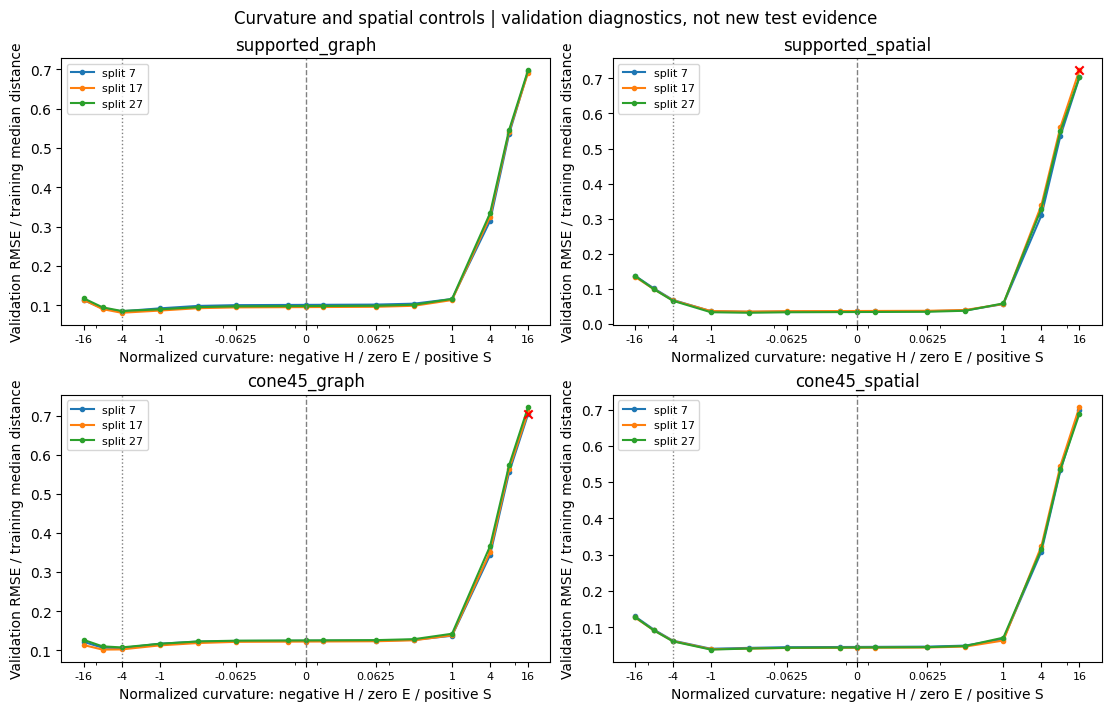


Validation summary (selected on validation; not unbiased performance estimates):
           metric      model  mean_val_nRMSE     k_min     k_max  all_converged  all_numerical_ok  boundary_selections
  supported_graph  euclidean        0.098561  0.000000  0.000000           True              True                    0
  supported_graph hyperbolic        0.084161 -4.000000 -4.000000           True              True                    0
  supported_graph  spherical        0.098749  0.015625  0.015625           True              True                    3
supported_spatial  euclidean        0.035891  0.000000  0.000000           True              True                    0
supported_spatial hyperbolic        0.034170 -0.250000 -0.250000           True              True                    0
supported_spatial  spherical        0.036045  0.015625  0.015625           True              True                    3
     cone45_graph  euclidean        0.124209  0.000000  0.000000           True      

In [10]:
# Cell 10: validation-only curvature scan and matched spatial controls.
# Run after Cell 9 in the same kernel. No new tracking or graph construction.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required10 = ("pair_geometry", "training_starts", "encode_start", "fit_best", "OPT_LOG")
if any(name not in globals() for name in required10):
    raise RuntimeError("Run Cell 9 first; this cell reuses its fitting functions.")
if DIM != 3:
    raise ValueError("This comparison requires DIM=3, unchanged from Cell 9.")


def run_cell10():
    root = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest/results")
    out = root / "cell10_curvature_controls"
    out.mkdir(parents=True, exist_ok=True)
    seeds = (7, 17, 27)
    mags = (0.015625, 0.0625, 0.25, 1., 4., 8., 16.)
    metrics = ("supported_graph", "supported_spatial", "cone45_graph", "cone45_spatial")
    kinds = ("euclidean", "hyperbolic", "spherical")
    with np.load(root / "cell07_network_geometry/matched_metrics.npz") as z:
        matrices = {name: z[name].astype(float) for name in metrics}
        ids = z["base_node_id"].copy()
    n = len(ids)
    i, j = np.triu_indices(n, 1)
    rows, chosen = [], []
    log_start = len(OPT_LOG)
    print(f"Same {n} landmarks | dimension 3 | validation only | |curvature| <= 16")
    print("No test errors computed. Spatial controls are separately embedded.")

    for metric in metrics:
        D = matrices[metric]
        if D.shape != (n, n) or not np.isfinite(D).all() or not np.allclose(D, D.T):
            raise ValueError(f"Invalid distance matrix: {metric}")
        raw = D[i, j]
        if np.any(raw <= 0):
            raise ValueError(f"Nonpositive off-diagonal distance: {metric}")
        for seed in seeds:
            with np.load(root / f"cell09_geometry_prediction/split_{seed}.npz") as z:
                assert np.array_equal(z["base_node_id"], ids)
                assert np.array_equal(z["i"], i) and np.array_equal(z["j"], j)
                tr, va = z["train"].copy(), z["val"].copy()
            scale = float(np.median(raw[tr]))
            target = raw / scale
            starts = training_starts(n, i[tr], j[tr], target[tr], seed)
            print(f"\n{metric}, split {seed}", flush=True)
            for kind in kinds:
                grid = (0.,) if kind == "euclidean" else tuple(
                    m * (-1 if kind == "hyperbolic" else 1) for m in mags
                )
                choices = []
                for k in grid:
                    initial = [encode_start(X, kind, k) for X in starts]
                    Z, ok, loss = fit_best(
                        initial, kind, k, i[tr], j[tr], target[tr],
                        dict(graph=metric, seed=seed, stage="cell10_validation"),
                    )
                    pred = pair_geometry(Z, kind, k, i[va], j[va])[0]
                    score = float(np.sqrt(np.mean((pred - target[va])**2)))
                    # Stronger curvature can amplify Lorentz roundoff.
                    # Check validation predictions with extended precision.
                    roundoff = 0.
                    if kind == "hyperbolic":
                        A, B = Z[i[va]].astype(np.longdouble), Z[j[va]].astype(np.longdouble)
                        R = 1 / np.sqrt(np.longdouble(abs(k)))
                        ta, tb = np.sqrt(R*R + (A*A).sum(1)), np.sqrt(R*R + (B*B).sum(1))
                        c = (ta*tb - (A*B).sum(1)) / (R*R)
                        precise = R * np.arccosh(np.maximum(c, 1))
                        roundoff = float(np.max(np.abs(precise - pred)))
                    row = dict(
                        metric=metric, seed=seed, model=kind, curvature_scaled=k,
                        curvature_per_mm2=k/scale**2, train_scale_mm=scale,
                        train_nRMSE=np.sqrt(loss), val_nRMSE=score,
                        val_RMSE_mm=score*scale, converged=ok,
                        numerical_error_normalized=roundoff,
                        numerical_ok=bool(np.isfinite(roundoff) and roundoff <= 1e-6),
                        grid_boundary=bool(k and abs(k) in (min(mags), max(mags))),
                    )
                    rows.append(row)
                    choices.append((row, Z))
                # Keep the minimum as reported; flag failures rather than hiding them.
                best, Z = min(choices, key=lambda item: item[0]["val_nRMSE"])
                chosen.append(best.copy())
                np.savez_compressed(
                    out / f"selected_{metric}_{seed}_{kind}.npz",
                    coordinates=Z, kind=kind, curvature_scaled=best["curvature_scaled"],
                    train_scale_mm=scale, base_node_id=ids, i=i, j=j, train=tr, val=va,
                )
                print(
                    f"  {kind}: k={best['curvature_scaled']:g}, "
                    f"validation nRMSE={best['val_nRMSE']:.4f}, "
                    f"converged={best['converged']}", flush=True,
                )
            pd.DataFrame(rows).to_csv(out / "validation_scan.csv", index=False)
            pd.DataFrame(chosen).to_csv(out / "selected_models.csv", index=False)
            pd.DataFrame(OPT_LOG[log_start:]).to_csv(out / "optimizer_runs.csv", index=False)

    scan, selected = pd.DataFrame(rows), pd.DataFrame(chosen)
    summary = selected.groupby(["metric", "model"], sort=False).agg(
        mean_val_nRMSE=("val_nRMSE", "mean"),
        k_min=("curvature_scaled", "min"), k_max=("curvature_scaled", "max"),
        all_converged=("converged", "all"), all_numerical_ok=("numerical_ok", "all"),
        boundary_selections=("grid_boundary", "sum"),
    ).reset_index()
    summary.to_csv(out / "validation_summary.csv", index=False)
    errors = selected.pivot(index=["metric", "seed"], columns="model", values="val_nRMSE")
    reduction = errors["euclidean"] - errors["hyperbolic"]
    contrast = pd.DataFrame([
        dict(graph=g, seed=s,
             graph_nRMSE_reduction=reduction.loc[(g+"_graph", s)],
             spatial_nRMSE_reduction=reduction.loc[(g+"_spatial", s)],
             extra_reduction=reduction.loc[(g+"_graph", s)]-reduction.loc[(g+"_spatial", s)])
        for g in ("supported", "cone45") for s in seeds
    ])
    contrast.to_csv(out / "graph_spatial_contrast.csv", index=False)

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
    for ax, metric in zip(axes.ravel(), metrics):
        for seed in seeds:
            s = scan[(scan.metric == metric) & (scan.seed == seed)].sort_values("curvature_scaled")
            ax.plot(s.curvature_scaled, s.val_nRMSE, ".-", label=f"split {seed}")
            bad = ~(s.converged & s.numerical_ok)
            ax.scatter(s.loc[bad, "curvature_scaled"], s.loc[bad, "val_nRMSE"],
                       marker="x", color="red", zorder=5)
        ax.set_xscale("symlog", linthresh=0.0625)
        ax.set_xticks([-16, -4, -1, -0.0625, 0, 0.0625, 1, 4, 16])
        ax.set_xticklabels(["-16", "-4", "-1", "-0.0625", "0", "0.0625", "1", "4", "16"], fontsize=8)
        ax.axvline(0, color="grey", ls="--", lw=1)
        ax.axvline(-4, color="grey", ls=":", lw=1)
        ax.set(title=metric, xlabel="Normalized curvature: negative H / zero E / positive S",
               ylabel="Validation RMSE / training median distance")
        ax.legend(fontsize=8)
    fig.suptitle("Curvature and spatial controls | validation diagnostics, not new test evidence")
    fig.savefig(out / "curvature_controls.png", dpi=180)
    plt.show()
    (out / "metadata.json").write_text(json.dumps(dict(
        dimension=3, seeds=seeds, curvature_magnitudes=mags, maxiter=MAXITER,
        starts=2, objective="Equal-weight pair-distance MSE, unchanged from Cell 9",
        protocol="Reuse Cell 9 training/validation pairs; no refit or test scoring",
        scale="Each target uses its own training median; curvature reported in both units",
        status="Adaptive exploratory validation after Cell 9, not independent confirmation",
        control="Direction-free spatial graph; not a degree-matched or biological null",
        inference="Gain difference is descriptive; overlapping splits are not independent subjects",
        roundoff_check="Validation distances in longdouble; normalized tolerance 1e-6",
        longdouble_mantissa_bits=int(np.finfo(np.longdouble).nmant),
    ), indent=2), encoding="utf-8")
    print("\nValidation summary (selected on validation; not unbiased performance estimates):")
    print(summary.to_string(index=False))
    print("\nHyperbolic nRMSE reduction = Euclidean - hyperbolic (positive favors H):")
    print(contrast.to_string(index=False))
    nbad = int((~(scan.converged & scan.numerical_ok)).sum())
    print(f"\nCandidates needing optimization/numerical review: {nbad}/{len(scan)}")
    if nbad:
        print("WARNING: Do not interpret a minimum involving failed optimization/numerics as evidence.")
    print("Boundary selections mean the optimum is not bracketed by this grid.")
    print(f"Saved: {out}")
    return scan, selected, contrast


scan10, selected10, contrast10 = run_cell10()

New panels: 3 x 64 landmarks; no voxel overlap with old or other panels.
Curvatures frozen before fitting: {'supported_graph': -4.0, 'supported_spatial': -0.25, 'cone45_graph': -4.0, 'cone45_spatial': -1.0} | spherical: 0.015625
Distances: supported_graph, panel 101 complete
Distances: supported_graph, panel 202 complete
Distances: supported_graph, panel 303 complete
Distances: supported_spatial, panel 101 complete
Distances: supported_spatial, panel 202 complete
Distances: supported_spatial, panel 303 complete
Distances: cone45_graph, panel 101 complete
Distances: cone45_graph, panel 202 complete
Distances: cone45_graph, panel 303 complete
Distances: cone45_spatial, panel 101 complete
Distances: cone45_spatial, panel 202 complete
Distances: cone45_spatial, panel 303 complete
Fitting/test pairs per panel: 1612/404; no new validation search.
Fitted: panel 101, supported_graph
Fitted: panel 101, supported_spatial
Fitted: panel 101, cone45_graph
Fitted: panel 101, cone45_spatial
Fitted: p

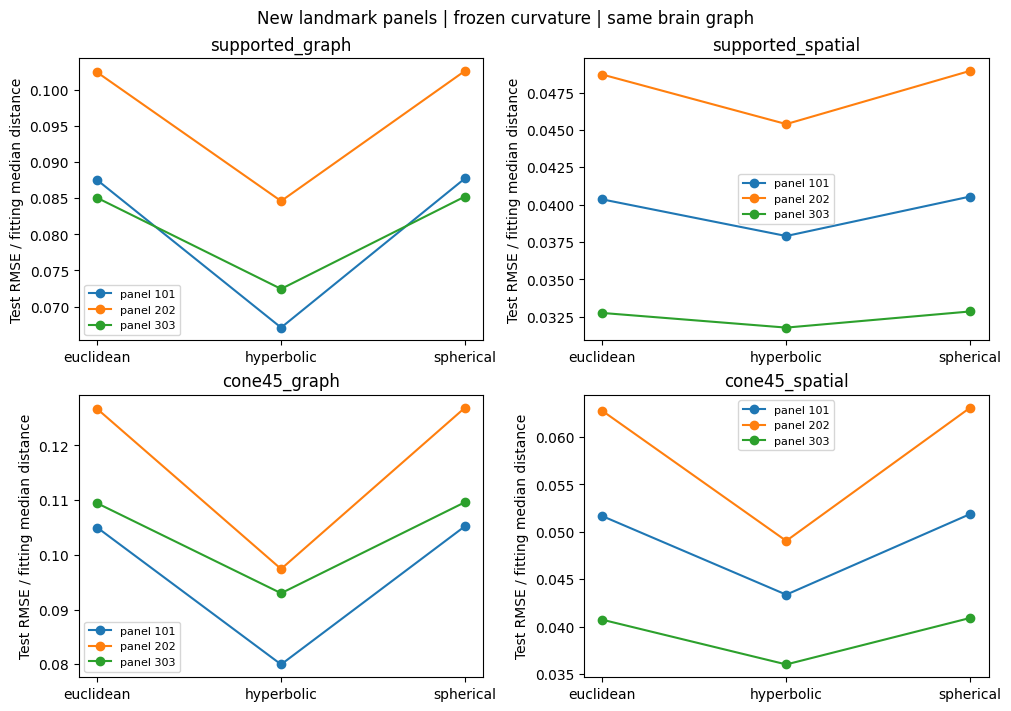


New-panel test summary (panel SD is not a confidence interval):
           metric      model  mean_test_nRMSE  sd_across_panels  all_converged  all_numerical_ok
  supported_graph  euclidean         0.091686          0.009411           True              True
  supported_graph hyperbolic         0.074718          0.008987           True              True
  supported_graph  spherical         0.091895          0.009414           True              True
supported_spatial  euclidean         0.040602          0.007976           True              True
supported_spatial hyperbolic         0.038354          0.006818           True              True
supported_spatial  spherical         0.040782          0.008050           True              True
     cone45_graph  euclidean         0.113701          0.011457           True              True
     cone45_graph hyperbolic         0.090119          0.009071           True              True
     cone45_graph  spherical         0.113922          0.01145

In [11]:
# Cell 11: new landmark panels, frozen curvature, held-out distance prediction.
# Reuses Cell 7 spatial_reference/metric_checks and Cell 9 fitting functions.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import dijkstra
from itertools import product

required11 = ("spatial_reference", "metric_checks", "training_starts",
              "encode_start", "fit_best", "pair_geometry", "OPT_LOG")
if any(k not in globals() for k in required11) or globals().get("DIM") != 3:
    raise RuntimeError("Run Cells 7 and 9 first in this kernel; DIM must remain 3.")


def run_cell11():
    root = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest/results")
    src, out = root / "cell04_orientation_graph", root / "cell11_new_landmarks"
    out.mkdir(parents=True, exist_ok=True)
    seeds, n, pair_seed = (101, 202, 303), 64, 711
    names, kinds = ("supported", "cone45"), ("euclidean", "hyperbolic", "spherical")
    fixed_H = {"supported_graph": -4., "supported_spatial": -0.25,
               "cone45_graph": -4., "cone45_spatial": -1.}
    fixed_S = 0.015625
    protocol = dict(
        landmark_seeds=seeds, landmarks_per_panel=n, pair_seed=pair_seed,
        dimension=3, fixed_H=fixed_H, fixed_S=fixed_S, maxiter=MAXITER, starts=2,
        selection="Frozen from Cell 10 before sampling; no curvature selection on new panels",
        sampling="Uniform common-LCC voxels; one eligible component per voxel; exclude old and prior-panel voxels",
        routing="Full graphs retain all intermediate nodes, including old landmarks",
        split="80% fitting pairs, 20% testing pairs; same index split for every panel/model/metric",
        normalization="Each target/panel uses its fitting-pair median; fixed normalized curvature",
        scope="Refit coordinates for new panels on the same brain graph; not new-subject validation or transfer of old coordinates",
        inference="Endpoint-sampling robustness; panels share the graph and are not independent subjects",
    )
    (out / "protocol.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
    nodes = {}
    for name in names:
        with np.load(src / f"nodes_{name}.npz") as z:
            nodes[name] = {k: z[k].copy() for k in
                          ("base_node_id", "ijk", "world_xyz_mm", "component", "in_largest")}
    a, b = nodes["supported"], nodes["cone45"]
    la, lb = np.flatnonzero(a["in_largest"]), np.flatnonzero(b["in_largest"])
    common, ia, ib = np.intersect1d(a["base_node_id"][la], b["base_node_id"][lb],
                                  assume_unique=True, return_indices=True)
    loc = dict(supported=la[ia], cone45=lb[ib])
    assert np.array_equal(a["ijk"][loc["supported"]], b["ijk"][loc["cone45"]])
    assert np.allclose(a["world_xyz_mm"][loc["supported"]], b["world_xyz_mm"][loc["cone45"]])
    assert np.array_equal(a["component"][loc["supported"]], b["component"][loc["cone45"]])
    shape = tuple(a["ijk"].max(axis=0) + 1)
    flat = np.ravel_multi_index(a["ijk"][loc["supported"]].T, shape)
    voxels, inverse = np.unique(flat, return_inverse=True)
    old_ids = pd.read_csv(root / "cell05_path_geometry/landmarks.csv").base_node_id.to_numpy()
    old_pos = pd.Index(a["base_node_id"]).get_indexer(old_ids)
    if np.any(old_pos < 0):
        raise ValueError("Old landmark IDs are absent from the supported node table.")
    old_voxels = np.ravel_multi_index(a["ijk"][old_pos].T, shape)
    available = np.flatnonzero(~np.isin(voxels, old_voxels))
    if len(available) < n * len(seeds):
        raise ValueError("Insufficient unused common-LCC voxels for disjoint panels.")
    panels, distances = {}, {}
    for seed in seeds:
        rng = np.random.default_rng(seed)
        selected_voxels = rng.choice(available, n, replace=False)
        chosen = np.array([rng.choice(np.flatnonzero(inverse == v)) for v in selected_voxels])
        available = available[~np.isin(available, selected_voxels)]
        panels[seed] = {name: loc[name][chosen] for name in names}
        xyz, ids = a["world_xyz_mm"][loc["supported"][chosen]], common[chosen]
        distances[seed] = dict(base_node_id=ids, world_xyz_mm=xyz,
                              euclidean=np.linalg.norm(xyz[:, None]-xyz[None, :], axis=2))
        pd.DataFrame(dict(landmark_id=np.arange(n), base_node_id=ids,
                          component=a["component"][panels[seed]["supported"]],
                          supported_node_id=panels[seed]["supported"], cone45_node_id=panels[seed]["cone45"],
                          x_mm=xyz[:, 0], y_mm=xyz[:, 1], z_mm=xyz[:, 2])).to_csv(
                              out / f"landmarks_{seed}.csv", index=False)
    print(f"New panels: {len(seeds)} x {n} landmarks; no voxel overlap with old or other panels.")
    print("Curvatures frozen before fitting:", fixed_H, "| spherical:", fixed_S)

    def measure(G, targets):
        D = np.empty((n, n))
        for start in range(0, n, 8):
            D[start:start+8] = dijkstra(G, directed=False, indices=targets[start:start+8])[:, targets]
        metric_checks(D)
        return D

    for name in names:
        G = sparse.load_npz(src / f"edge_lengths_{name}.npz").tocsr()
        if G.shape != (len(nodes[name]["base_node_id"]),)*2 or (G != G.T).nnz:
            raise ValueError("Graph/node mismatch or asymmetric graph.")
        if np.any(G.data <= 0) or not np.isfinite(G.data).all():
            raise ValueError("Invalid edge lengths.")
        for seed in seeds:
            distances[seed][name+"_graph"] = measure(G, panels[seed][name])
            print(f"Distances: {name}_graph, panel {seed} complete", flush=True)
        del G
        S, node_to_voxel = spatial_reference(nodes[name]["ijk"], nodes[name]["world_xyz_mm"])
        for seed in seeds:
            D = measure(S, node_to_voxel[panels[seed][name]])
            if np.any(D < distances[seed]["euclidean"]-1e-3) or np.any(D > distances[seed][name+"_graph"]+1e-3):
                raise ValueError("Expected Euclidean <= spatial <= orientation-graph distance.")
            distances[seed][name+"_spatial"] = D
            np.savez_compressed(out / f"matched_metrics_{seed}.npz", **distances[seed])
            print(f"Distances: {name}_spatial, panel {seed} complete", flush=True)
        del S, node_to_voxel
    for ds in distances.values():
        for suffix in ("graph", "spatial"):
            if np.any(ds["cone45_"+suffix] < ds["supported_"+suffix]-1e-3):
                raise ValueError("Removing support unexpectedly shortened a distance.")

    i, j = np.triu_indices(n, 1)
    tr, te = np.split(np.random.default_rng(pair_seed).permutation(len(i)), [int(.8*len(i))])
    np.savez_compressed(out / "pair_split.npz", i=i, j=j, train=tr, test=te, pair_seed=pair_seed)
    print(f"Fitting/test pairs per panel: {len(tr)}/{len(te)}; no new validation search.")
    rows, predictions, log_start = [], [], len(OPT_LOG)
    for seed in seeds:
        for metric, kh in fixed_H.items():
            raw = distances[seed][metric][i, j]
            scale = float(np.median(raw[tr]))
            target = raw / scale
            starts = training_starts(n, i[tr], j[tr], target[tr], pair_seed)
            for kind, k in zip(kinds, (0., kh, fixed_S)):
                Z, ok, loss = fit_best([encode_start(X, kind, k) for X in starts], kind, k,
                    i[tr], j[tr], target[tr], dict(graph=metric, seed=seed, stage="cell11_fixed"))
                pred = pair_geometry(Z, kind, k, i[te], j[te])[0]
                roundoff = 0.
                if kind == "hyperbolic":
                    A, B = Z[i[te]].astype(np.longdouble), Z[j[te]].astype(np.longdouble)
                    R = 1 / np.sqrt(np.longdouble(abs(k)))
                    c = (np.sqrt(R*R+(A*A).sum(1))*np.sqrt(R*R+(B*B).sum(1))-(A*B).sum(1))/(R*R)
                    roundoff = float(np.max(np.abs(R*np.arccosh(np.maximum(c, 1))-pred)))
                err = (pred-target[te])*scale
                rows.append(dict(panel_seed=seed, metric=metric, model=kind, curvature_scaled=k,
                    train_scale_mm=scale, train_nRMSE=np.sqrt(loss), test_RMSE_mm=np.sqrt(np.mean(err**2)),
                    test_nRMSE=np.sqrt(np.mean(err**2))/scale, test_MAE_mm=np.mean(np.abs(err)),
                    converged=ok, numerical_ok=bool(np.isfinite(roundoff) and roundoff <= 1e-6),
                    numerical_error_normalized=roundoff))
                predictions.append(pd.DataFrame(dict(panel_seed=seed, metric=metric, model=kind,
                    landmark_a=i[te], landmark_b=j[te], observed_mm=raw[te], predicted_mm=pred*scale)))
                np.savez_compressed(out / f"fit_{metric}_{seed}_{kind}.npz", coordinates=Z, kind=kind,
                    curvature_scaled=k, train_scale_mm=scale, base_node_id=distances[seed]["base_node_id"])
            pd.DataFrame(rows).to_csv(out / "test_results.csv", index=False)
            pd.DataFrame(OPT_LOG[log_start:]).to_csv(out / "optimizer_runs.csv", index=False)
            print(f"Fitted: panel {seed}, {metric}", flush=True)
    results = pd.DataFrame(rows)
    pd.concat(predictions, ignore_index=True).to_csv(out / "test_pair_predictions.csv", index=False)
    summary = results.groupby(["metric", "model"], sort=False).agg(
        mean_test_nRMSE=("test_nRMSE", "mean"), sd_across_panels=("test_nRMSE", "std"),
        all_converged=("converged", "all"), all_numerical_ok=("numerical_ok", "all")).reset_index()
    table = results.pivot(index=["panel_seed", "metric"], columns="model", values="test_nRMSE")
    gain = table.euclidean-table.hyperbolic
    contrast = pd.DataFrame([dict(panel_seed=s, graph=g,
        graph_reduction=gain.loc[(s, g+"_graph")], spatial_reduction=gain.loc[(s, g+"_spatial")],
        extra_reduction=gain.loc[(s, g+"_graph")]-gain.loc[(s, g+"_spatial")])
        for s in seeds for g in names])
    summary.to_csv(out / "panel_summary.csv", index=False)
    contrast.to_csv(out / "graph_spatial_contrast.csv", index=False)
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
    for ax, metric in zip(axes.ravel(), fixed_H):
        for seed in seeds:
            ax.plot(range(3), table.loc[(seed, metric), list(kinds)], "o-", label=f"panel {seed}")
        ax.set(title=metric, xticks=range(3), xticklabels=kinds, ylabel="Test RMSE / fitting median distance")
        ax.legend(fontsize=8)
    fig.suptitle("New landmark panels | frozen curvature | same brain graph")
    fig.savefig(out / "new_landmark_prediction.png", dpi=180)
    plt.show()
    print("\nNew-panel test summary (panel SD is not a confidence interval):")
    print(summary.to_string(index=False))
    print("\nEuclidean - hyperbolic test nRMSE (positive favors H):")
    print(contrast.to_string(index=False))
    print(f"\nOptimizer convergence: {sum(r['success'] for r in OPT_LOG[log_start:])}/{len(OPT_LOG)-log_start}")
    if not (results.converged & results.numerical_ok).all():
        print("WARNING: Review flagged fits before interpreting model rankings.")
    print(f"Saved: {out}")
    return results, contrast


results11, contrast11 = run_cell11()

Euclidean dimensions: (2, 3, 5, 8, 12); saved H^3 reference; no new shortest paths.
Reusing Cell 11 held-out pairs: dimension sensitivity, not independent confirmation.
Finished panel 101, supported_graph
Finished panel 101, supported_spatial
Finished panel 101, cone45_graph
Finished panel 101, cone45_spatial
Finished panel 202, supported_graph
Finished panel 202, supported_spatial
Finished panel 202, cone45_graph
Finished panel 202, cone45_spatial
Finished panel 303, supported_graph
Finished panel 303, supported_spatial
Finished panel 303, cone45_graph
Finished panel 303, cone45_spatial


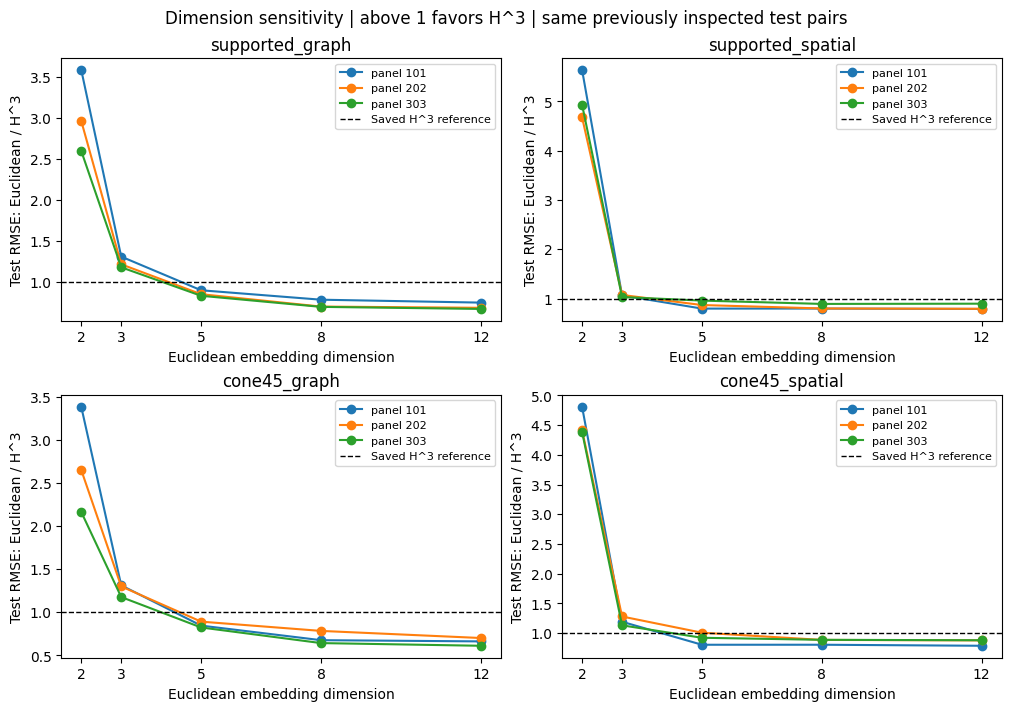


Dimension summary (descriptive comparison; no dimension selected on test):
           metric  euclidean_dimension  mean_E_train_nRMSE  mean_E_test_nRMSE  mean_H3_test_nRMSE  mean_ratio_E_over_H3  panels_E_le_H3  all_fit_ok
  supported_graph                    2            0.201226           0.226663            0.074718              3.051120               0        True
  supported_graph                    3            0.076636           0.091686            0.074718              1.229929               0        True
  supported_graph                    5            0.045768           0.063723            0.074718              0.854283               3        True
  supported_graph                    8            0.036551           0.053601            0.074718              0.720201               3        True
  supported_graph                   12            0.034893           0.051766            0.074718              0.694842               3        True
supported_spatial                   

In [12]:
# Cell 12: Euclidean dimension sensitivity against the saved H^3 fits.
# Uses the SAME already-inspected held-out pairs: not independent confirmation.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import dijkstra

if any(k not in globals() for k in ("fit_best", "pair_geometry", "OPT_LOG")):
    raise RuntimeError("Run Cell 9 first in this kernel to load its fitting functions.")


def run_cell12():
    root = Path("/mnt/g/Research/TUM_connectome/HyperbolicTest/results")
    src, out = root / "cell11_new_landmarks", root / "cell12_dimension_check"
    out.mkdir(parents=True, exist_ok=True)
    old_protocol = json.loads((src / "protocol.json").read_text())
    seeds, init_seed = old_protocol["landmark_seeds"], old_protocol["pair_seed"]
    metrics = tuple(old_protocol["fixed_H"])
    dims = (2, 3, 5, 8, 12)
    old = pd.read_csv(src / "test_results.csv").set_index(["panel_seed", "metric", "model"])
    with np.load(src / "pair_split.npz") as z:
        i, j, tr, te = (z[k].copy() for k in ("i", "j", "train", "test"))
    (out / "protocol.json").write_text(json.dumps(dict(
        dimensions=dims, reference="Cell 11 saved H^3; also reuse saved E^3",
        panels=seeds, initialization_seed=init_seed, maxiter=MAXITER,
        objective="Same equal-weight pair-distance MSE and fitting-median normalization as Cell 11",
        initialization="MDS from fitting distances plus random; d>3 also gets a lower-dimensional warm start",
        selection="Initialization selected by fitting loss only; no dimension selected for a new headline score",
        status="Exploratory sensitivity using already-inspected test pairs; not new independent test evidence",
        scope="Euclidean dimension versus fixed three-dimensional hyperbolic reference on the same graph",
    ), indent=2), encoding="utf-8")
    rows, predictions, log_start = [], [], len(OPT_LOG)
    print(f"Euclidean dimensions: {dims}; saved H^3 reference; no new shortest paths.")
    print("Reusing Cell 11 held-out pairs: dimension sensitivity, not independent confirmation.")

    for seed in seeds:
        with np.load(src / f"matched_metrics_{seed}.npz") as z:
            matrices = {metric: z[metric].astype(float) for metric in metrics}
            ids = z["base_node_id"].copy()
        n = len(ids)
        expected_i, expected_j = np.triu_indices(n, 1)
        assert np.array_equal(i, expected_i) and np.array_equal(j, expected_j)
        if max(dims) >= n or set(tr).intersection(te) or len(tr)+len(te) != len(i):
            raise ValueError("Invalid dimensions or pair partition.")
        for metric in metrics:
            raw = matrices[metric][i, j]
            scale = float(np.median(raw[tr]))
            target = raw / scale
            saved = {}
            for model in ("euclidean", "hyperbolic"):
                baseline = old.loc[(seed, metric, model)]
                with np.load(src / f"fit_{metric}_{seed}_{model}.npz") as z:
                    assert np.array_equal(z["base_node_id"], ids)
                    assert np.isclose(float(z["train_scale_mm"]), scale, rtol=1e-10)
                    Z, k = z["coordinates"].copy(), float(z["curvature_scaled"])
                pred = pair_geometry(Z, model, k, i[te], j[te])[0]
                score = float(np.sqrt(np.mean((pred-target[te])**2)))
                if not np.isclose(score, baseline.test_nRMSE, rtol=1e-6, atol=1e-9):
                    raise ValueError("Saved coordinates and Cell 11 results disagree.")
                if not (baseline.converged and baseline.numerical_ok):
                    raise ValueError("Review the flagged Cell 11 baseline before this comparison.")
                saved[model] = (Z, score, baseline)
            h3 = saved["hyperbolic"][1]
            if h3 <= 1e-12:
                raise ValueError("H^3 reference error is too small for a stable ratio.")

            # Construct initial coordinates from fitting distances ONLY.
            W = np.zeros((n, n))
            W[i[tr], j[tr]] = W[j[tr], i[tr]] = target[tr]
            filled = dijkstra(W, directed=False)
            if not np.isfinite(filled).all():
                raise ValueError("Fitting-pair graph is disconnected.")
            J = np.eye(n)-np.ones((n, n))/n
            eigenvalues, eigenvectors = np.linalg.eigh(-0.5*J@(filled**2)@J)
            previous, previous_loss = None, None
            for dim in dims:
                reused = dim == 3
                if reused:
                    Z, _, baseline = saved["euclidean"]
                    loss, ok = float(baseline.train_nRMSE)**2, bool(baseline.converged)
                else:
                    mds = eigenvectors[:, -dim:]*np.sqrt(np.maximum(eigenvalues[-dim:], 0))
                    random = np.random.default_rng(init_seed).normal(size=(n, dim))
                    starts = []
                    for X in (mds, random):
                        X = X-X.mean(axis=0)
                        current = np.linalg.norm(X[i[tr]]-X[j[tr]], axis=1)
                        X *= np.dot(current, target[tr])/np.dot(current, current)
                        starts.append(X)
                    if dim > 3:
                        extra = np.random.default_rng(init_seed+dim).normal(
                            scale=1e-3, size=(n, dim-previous.shape[1]))
                        warm = np.column_stack((previous, extra))
                        starts.append(warm-warm.mean(axis=0))
                    Z, ok, loss = fit_best(starts, "euclidean", 0., i[tr], j[tr], target[tr],
                        dict(graph=metric, seed=seed, dimension=dim, stage="cell12_dimension"))
                    np.savez_compressed(out / f"fit_{metric}_{seed}_E{dim}.npz", coordinates=Z,
                                        train_scale_mm=scale, base_node_id=ids, dimension=dim)
                regression = previous_loss is not None and loss > previous_loss+1e-6
                pred = np.linalg.norm(Z[i[te]]-Z[j[te]], axis=1)
                score = float(np.sqrt(np.mean((pred-target[te])**2)))
                rows.append(dict(panel_seed=seed, metric=metric, euclidean_dimension=dim,
                    coordinate_values=n*dim, train_nRMSE=np.sqrt(loss), test_nRMSE=score,
                    test_RMSE_mm=score*scale, H3_test_nRMSE=h3, E_over_H3=score/h3,
                    E_minus_H3=score-h3, E_le_H3=bool(score <= h3), converged=ok,
                    training_regression=regression, fit_ok=bool(ok and not regression), reused_cell11=reused))
                predictions.append(pd.DataFrame(dict(panel_seed=seed, metric=metric, dimension=dim,
                    landmark_a=i[te], landmark_b=j[te], observed_mm=raw[te], predicted_mm=pred*scale)))
                previous, previous_loss = Z, loss
            pd.DataFrame(rows).to_csv(out / "dimension_results.csv", index=False)
            pd.DataFrame(OPT_LOG[log_start:]).to_csv(out / "optimizer_runs.csv", index=False)
            print(f"Finished panel {seed}, {metric}", flush=True)

    results = pd.DataFrame(rows)
    pd.concat(predictions, ignore_index=True).to_csv(out / "test_pair_predictions.csv", index=False)
    summary = results.groupby(["metric", "euclidean_dimension"], sort=False).agg(
        mean_E_train_nRMSE=("train_nRMSE", "mean"), mean_E_test_nRMSE=("test_nRMSE", "mean"),
        mean_H3_test_nRMSE=("H3_test_nRMSE", "mean"), mean_ratio_E_over_H3=("E_over_H3", "mean"),
        panels_E_le_H3=("E_le_H3", "sum"), all_fit_ok=("fit_ok", "all")).reset_index()
    summary.to_csv(out / "dimension_summary.csv", index=False)
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
    for ax, metric in zip(axes.ravel(), metrics):
        for seed in seeds:
            part = results[(results.metric == metric) & (results.panel_seed == seed)]
            ax.plot(part.euclidean_dimension, part.E_over_H3, "o-", label=f"panel {seed}")
            bad = ~part.fit_ok
            ax.scatter(part.loc[bad, "euclidean_dimension"], part.loc[bad, "E_over_H3"],
                       marker="x", color="red", s=65, zorder=5)
        ax.axhline(1, ls="--", color="black", lw=1, label="Saved H^3 reference")
        ax.set(title=metric, xticks=dims, xlabel="Euclidean embedding dimension",
               ylabel="Test RMSE: Euclidean / H^3")
        ax.legend(fontsize=8)
    fig.suptitle("Dimension sensitivity | above 1 favors H^3 | same previously inspected test pairs")
    fig.savefig(out / "dimension_comparison.png", dpi=180)
    plt.show()
    print("\nDimension summary (descriptive comparison; no dimension selected on test):")
    print(summary.to_string(index=False))
    print(f"\nNew optimizer convergence: {sum(r['success'] for r in OPT_LOG[log_start:])}/{len(OPT_LOG)-log_start}")
    if not results.fit_ok.all():
        print("WARNING: Review nonconvergence/training regression before interpreting higher-dimensional fits.")
    print("A higher-dimensional Euclidean match would indicate a dimension/geometry tradeoff.")
    print(f"Saved: {out}")
    return results, summary


results12, summary12 = run_cell12()

Matched dimensions: (3, 5, 8); curvature chosen without test distances.
Inner train/validation: 1209/403; final fit/test: 1612/404
Already-inspected test pairs; exploratory comparison. No new shortest paths.
Panel 101, supported_graph, d=3: selected k=-4; fit_ok=True
Panel 101, supported_graph, d=5: selected k=-1; fit_ok=True
Panel 101, supported_graph, d=8: selected k=-0.0625; fit_ok=True
Panel 101, supported_spatial, d=3: selected k=-1; fit_ok=True
Panel 101, supported_spatial, d=5: selected k=-0.25; fit_ok=True
Panel 101, supported_spatial, d=8: selected k=-0.25; fit_ok=True
Panel 101, cone45_graph, d=3: selected k=-8; fit_ok=True
Panel 101, cone45_graph, d=5: selected k=-0.0625; fit_ok=True
Panel 101, cone45_graph, d=8: selected k=-0.25; fit_ok=True
Panel 101, cone45_spatial, d=3: selected k=-1; fit_ok=True
Panel 101, cone45_spatial, d=5: selected k=-1; fit_ok=True
Panel 101, cone45_spatial, d=8: selected k=-0.25; fit_ok=True
Panel 202, supported_graph, d=3: selected k=-4; fit_ok=T

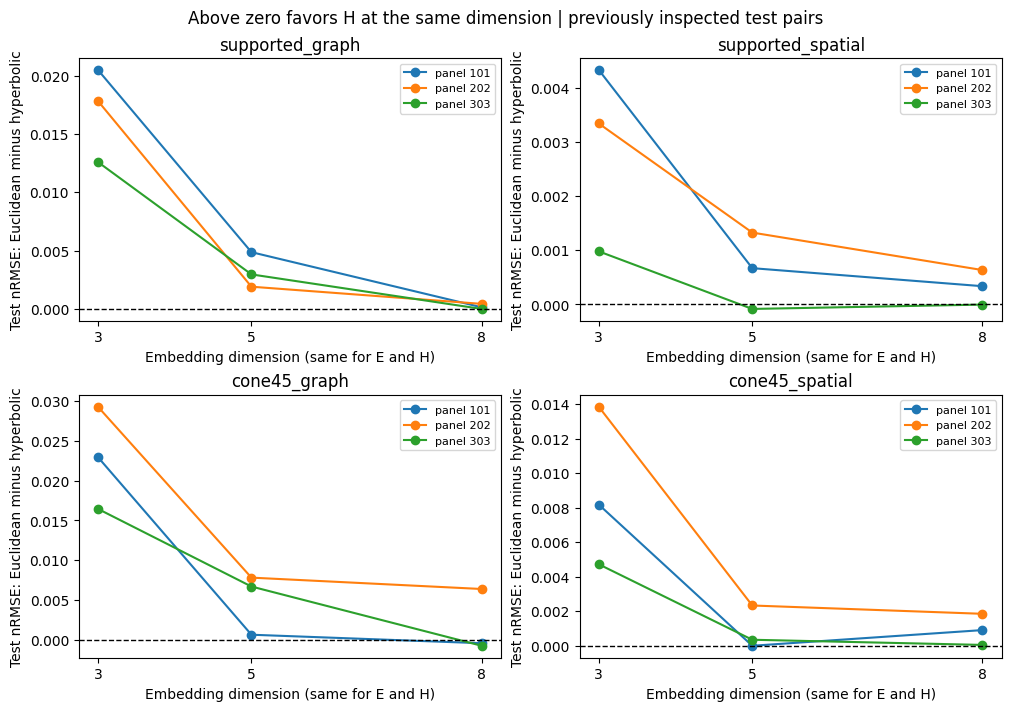


Matched-dimension summary (descriptive, not independent confirmation):
           metric  dimension  mean_E_test_nRMSE  mean_H_test_nRMSE  mean_E_minus_H  k_min     k_max  near_flat_selections  strong_boundary_selections  all_selected_ok  all_candidates_ok
  supported_graph          3           0.091687           0.074713        0.016973  -4.00 -4.000000                     0                           0             True               True
  supported_graph          5           0.063726           0.060481        0.003245  -1.00 -0.250000                     0                           0             True               True
  supported_graph          8           0.053595           0.053404        0.000191  -0.25 -0.015625                     1                           0             True               True
supported_spatial          3           0.040602           0.037718        0.002884  -1.00 -0.250000                     0                           0             True               Tru

In [13]:
# Cell 13: Compare Euclidean and hyperbolic embeddings at matched dimensions
# - Compare dimensions 3, 5, and 8 for both orientation graphs and spatial controls
# - Select hyperbolic curvature using an inner train/validation split of the fitting pairs
# - Refit E/H models and evaluate on the original 20% test pairs
# - Reuse saved distance matrices; no FSL or new shortest-path computations
# - Exploratory comparison: these test pairs have already been inspected
%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell13.py"

Graph controls: 3 per graph; 100 proposals per free edge.
Fixed spanning forest; exact degree/length/component checks; no curvature search.

supported: 147,840 nodes, 238,809 edges, 26,796 components
  seed 1401, 1/5: swaps=16,613, changed=10.8% of all edges
  seed 1401, 2/5: swaps=32,617, changed=17.2% of all edges
  seed 1401, 3/5: swaps=48,342, changed=21.4% of all edges
  seed 1401, 4/5: swaps=63,936, changed=24.6% of all edges
  seed 1401, 5/5: swaps=79,506, changed=26.8% of all edges
  seed 1402, 1/5: swaps=16,400, changed=10.5% of all edges
  seed 1402, 2/5: swaps=32,328, changed=17.1% of all edges
  seed 1402, 3/5: swaps=48,158, changed=21.4% of all edges
  seed 1402, 4/5: swaps=63,472, changed=24.3% of all edges
  seed 1402, 5/5: swaps=78,813, changed=26.6% of all edges
  seed 1403, 1/5: swaps=16,452, changed=10.6% of all edges
  seed 1403, 2/5: swaps=32,587, changed=17.0% of all edges
  seed 1403, 3/5: swaps=48,279, changed=21.3% of all edges
  seed 1403, 4/5: swaps=63,747, c

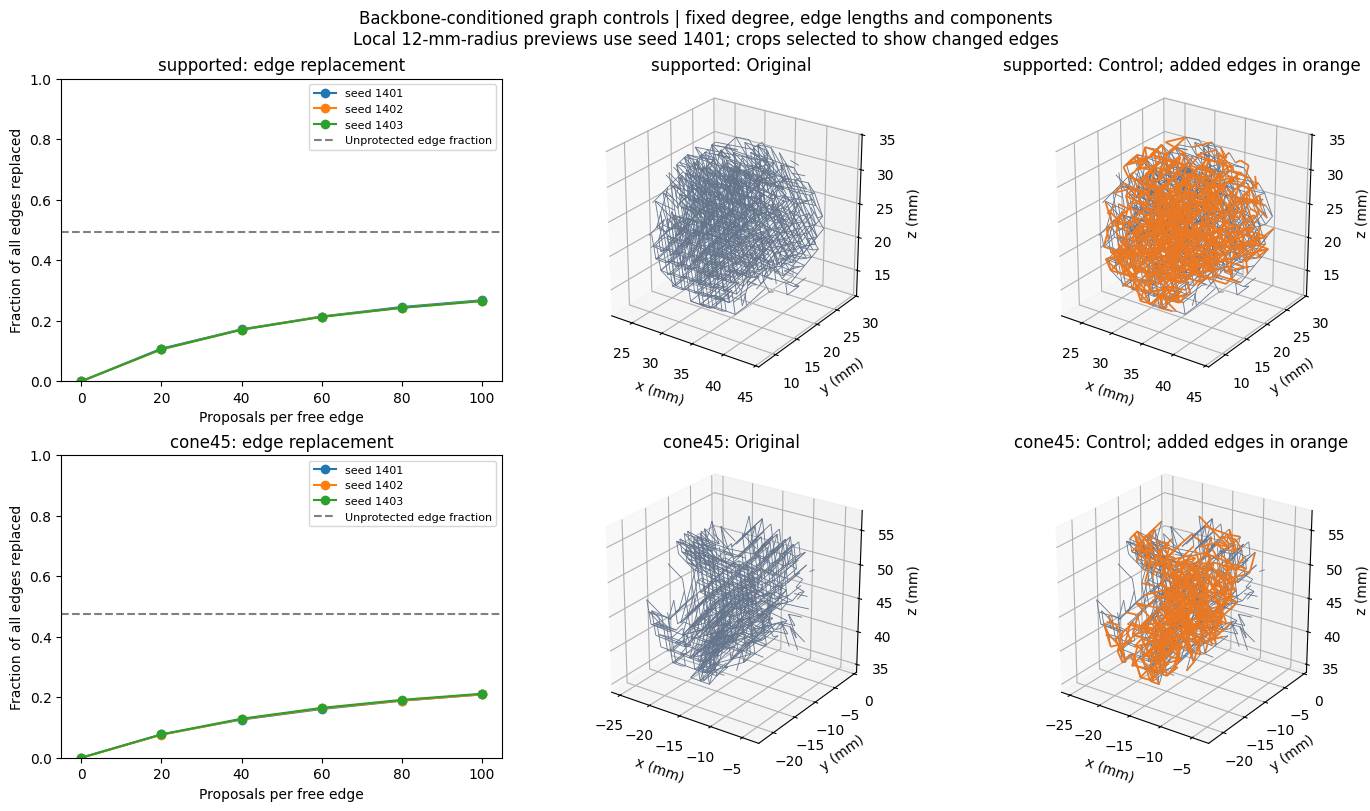


Construction summary:
    graph  seed  nodes  edges  protected_fraction  free_edges  proposals  accepted_swaps  acceptance_fraction  changed_edge_fraction  replaced_free_fraction  original_axis_step_angle_deg  null_axis_step_angle_deg  compatible_edge_fraction  degree_preserved  length_hist_preserved  components_preserved  forest_preserved  landmarks_connected  construction_ok   seconds
supported  1401 147840 238809            0.506865      117765   11776500           79506             0.006751               0.267833                0.543124                     27.227491                 37.695000                  0.732167              True                   True                  True              True                 True             True 35.502675
supported  1402 147840 238809            0.506865      117765   11776500           78813             0.006692               0.265828                0.539057                     27.227491                 37.619994                  0.734172   

In [14]:
# Cell 14: Construct spatial graph controls
# - Preserve nodes, per-node degree, global edge-length counts, and components
# - Rewire local edges while protecting a random spanning forest
# - Generate three controls per graph and save checks and local 3D previews
# - No curvature search, embedding fitting, or FSL

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell14.py"

In [15]:
# Cell 14b: Export whole-brain graph connections for FSLeyes
# - Export all original graph edges as NIfTI and TCK
# - Use a finer display grid without changing the MRI resolution
# - Preserve world coordinates and save endpoint node IDs
# - No tracking, rewiring, or geometry fitting

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell14b.py"

Native shape: (130, 130, 60); native voxel sizes: (2.0, 2.0, 2.0) mm
Display shape: (517, 517, 237); display voxel sizes: (0.4999999934980842, 0.5000000052488024, 0.5000000128549483) mm
Exporting all original graph edges, without landmark subsampling.
supported: 238,809 edges -> supported_graph_edges.nii.gz and supported_graph_edges.tck
cone45: 133,750 edges -> cone45_graph_edges.nii.gz and cone45_graph_edges.tck

    graph  nodes  undirected_edges  isolated_nodes  occupied_display_voxels  max_edge_visits                   nifti_file                  tck_file
supported 147840            238809           22518                   789711               19 supported_graph_edges.nii.gz supported_graph_edges.tck
   cone45  84328            133750           12211                   464102               16    cone45_graph_edges.nii.gz    cone45_graph_edges.tck
In FSLeyes, open the native mean_S0samples image, then one exported overlay.
For NIfTI, clip values below 0.5 to hide the background. For 

In [16]:
# Cell 14c: Export all graph views in fdt_paths space
%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell14c.py"

Registration: inverse of the seed-to-DWI FLIRT matrix recorded in probtrackx.log.
Transform: /mnt/g/Research/TUM_connectome/HyperbolicTest/BEDPOSTX.bedpostX/xfms/str2diff.mat
Target: (176, 240, 256); voxel sizes: (1.0, 1.0, 1.0) mm
Verified seed-space masks: 3
Forward/inverse agreement at DWI corners: 1.28936e-08 mm
Positive fdt_paths voxels inside transformed DWI mask: 99.57% (descriptive QC)
supported, original: 238,809 edges; exact target grid; 0 edges touch/exceed FOV
supported, null_1401: 238,809 edges; exact target grid; 0 edges touch/exceed FOV
supported, null_1402: 238,809 edges; exact target grid; 0 edges touch/exceed FOV
supported, null_1403: 238,809 edges; exact target grid; 0 edges touch/exceed FOV
cone45, original: 133,750 edges; exact target grid; 0 edges touch/exceed FOV
cone45, null_1401: 133,750 edges; exact target grid; 0 edges touch/exceed FOV
cone45, null_1402: 133,750 edges; exact target grid; 0 edges touch/exceed FOV
cone45, null_1403: 133,750 edges; exact target 

Reference: /mnt/g/Research/TUM_connectome/HyperbolicTest/PROBTRACKX/fdt_paths.nii.gz
Checking exports in: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell14c_fdt_space

Header checks:
                             file           shape  shape_match  affine_match  voxel_size_match  forms_match  units_match
   cone45_null_1401_in_fdt.nii.gz (176, 240, 256)         True          True              True         True         True
   cone45_null_1402_in_fdt.nii.gz (176, 240, 256)         True          True              True         True         True
   cone45_null_1403_in_fdt.nii.gz (176, 240, 256)         True          True              True         True         True
    cone45_original_in_fdt.nii.gz (176, 240, 256)         True          True              True         True         True
     dwi_brain_mask_in_fdt.nii.gz (176, 240, 256)         True          True              True         True         True
supported_null_1401_in_fdt.nii.gz (176, 240, 256)         True          True    

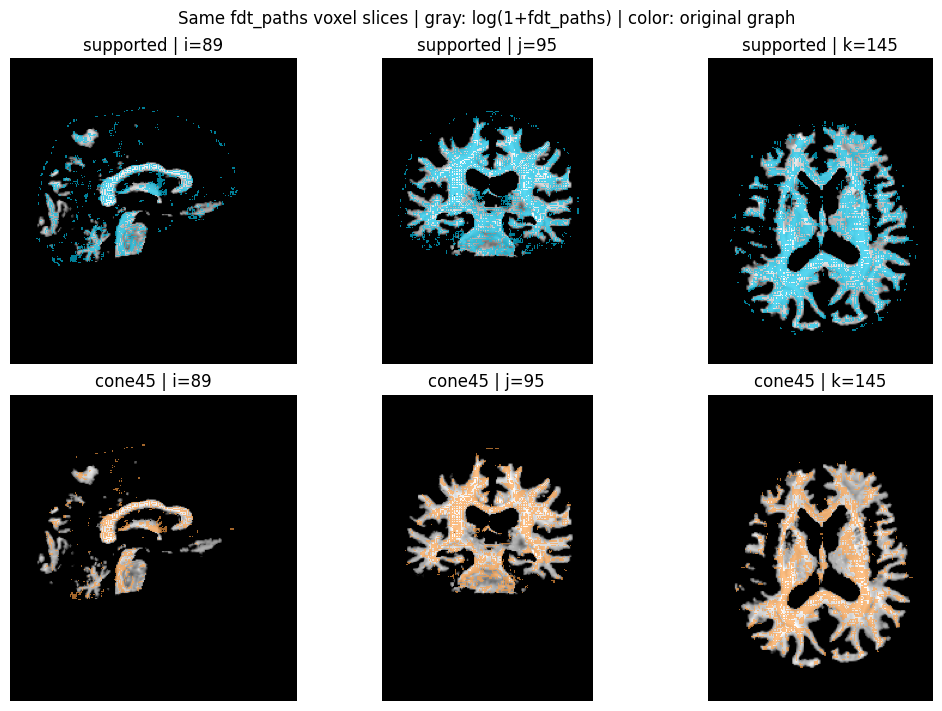


Grid agreement and subset checks do not independently validate anatomical registration.
Overlap with positive fdt_paths is descriptive; graph coverage need not equal tracking density support.
Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell14c_fdt_space/alignment_check


In [17]:
# Check exported coordinates and matched-slice overlays
%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/check_cell14c_alignment.py"

Fixed E^3/H^3 comparison; k=-4; panels (101, 202, 303); controls (1401, 1402, 1403).
Fitting/test pairs: 1612/404; two starts; original fits rerun identically.
No curvature search. Already-inspected pairs; conditional descriptive comparison.
Fitted: supported, original, panel 101; E/H fit_ok=True/True
Fitted: supported, original, panel 202; E/H fit_ok=True/True
Fitted: supported, original, panel 303; E/H fit_ok=True/True
Finished supported, original: 0.5 s
Distances: supported, null_1401, panel 101 complete
Fitted: supported, null_1401, panel 101; E/H fit_ok=True/True
Distances: supported, null_1401, panel 202 complete
Fitted: supported, null_1401, panel 202; E/H fit_ok=True/True
Distances: supported, null_1401, panel 303 complete
Fitted: supported, null_1401, panel 303; E/H fit_ok=True/True
Finished supported, null_1401: 13.0 s
Distances: supported, null_1402, panel 101 complete
Fitted: supported, null_1402, panel 101; E/H fit_ok=True/True
Distances: supported, null_1402, panel 202 co

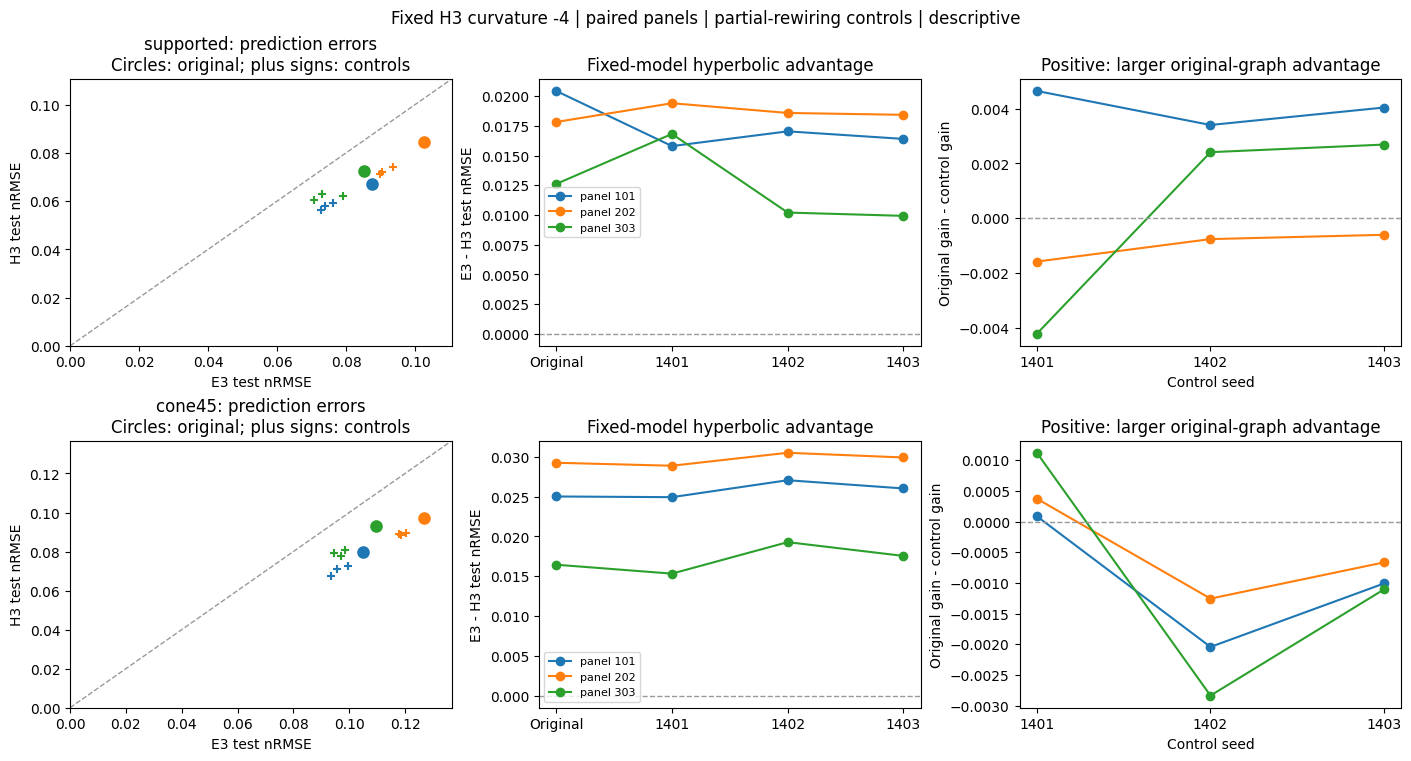


Model summary (means over panels of one brain; no inferential error bars):
    graph   variant  mean_E_test_nRMSE  mean_H_test_nRMSE  mean_H_gain  mean_relative_H_reduction  all_fit_ok
supported  original           0.091686           0.074718     0.016968                   0.185347        True
supported null_1401           0.082128           0.064778     0.017350                   0.211556        True
supported null_1402           0.078852           0.063569     0.015283                   0.191830        True
supported null_1403           0.078683           0.063757     0.014926                   0.188628        True
   cone45  original           0.113701           0.090119     0.023582                   0.206583        True
   cone45 null_1401           0.102741           0.079685     0.023056                   0.222565        True
   cone45 null_1402           0.105523           0.079896     0.025628                   0.241711        True
   cone45 null_1403           0.103414      

In [18]:
# Cell 15: Compare original graphs with rewired controls
# Fixed dimension 3 and hyperbolic curvature -4
# Reuse Cell 11 landmarks and fitting/test pairs
# No curvature search or FSL

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell15.py"

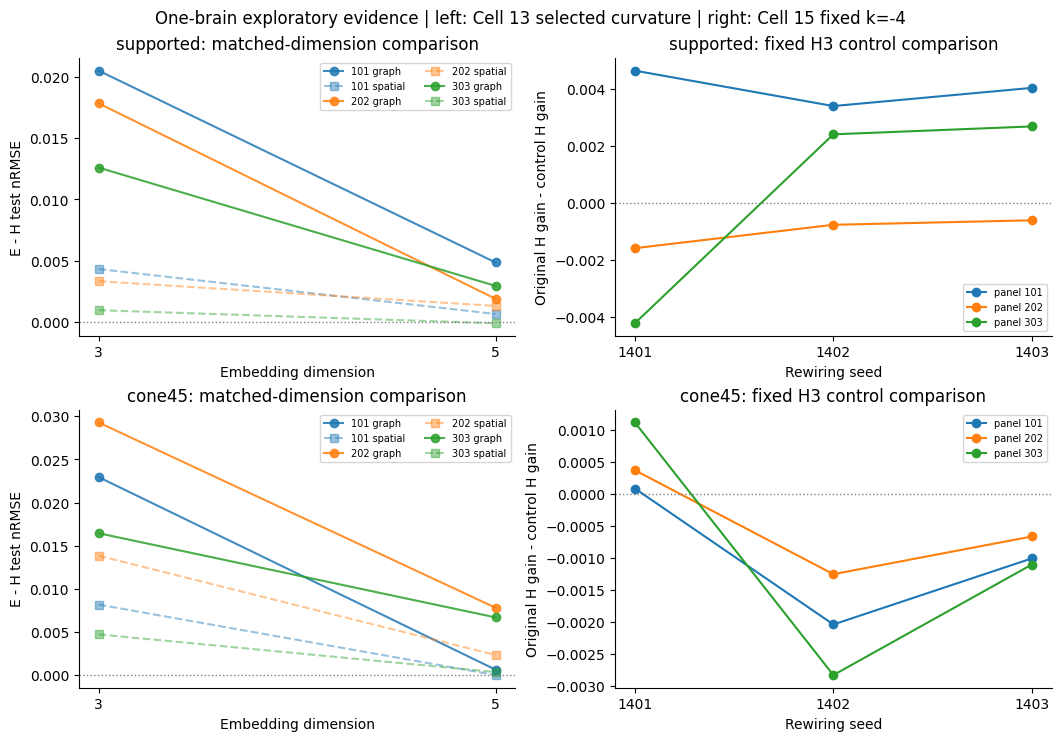

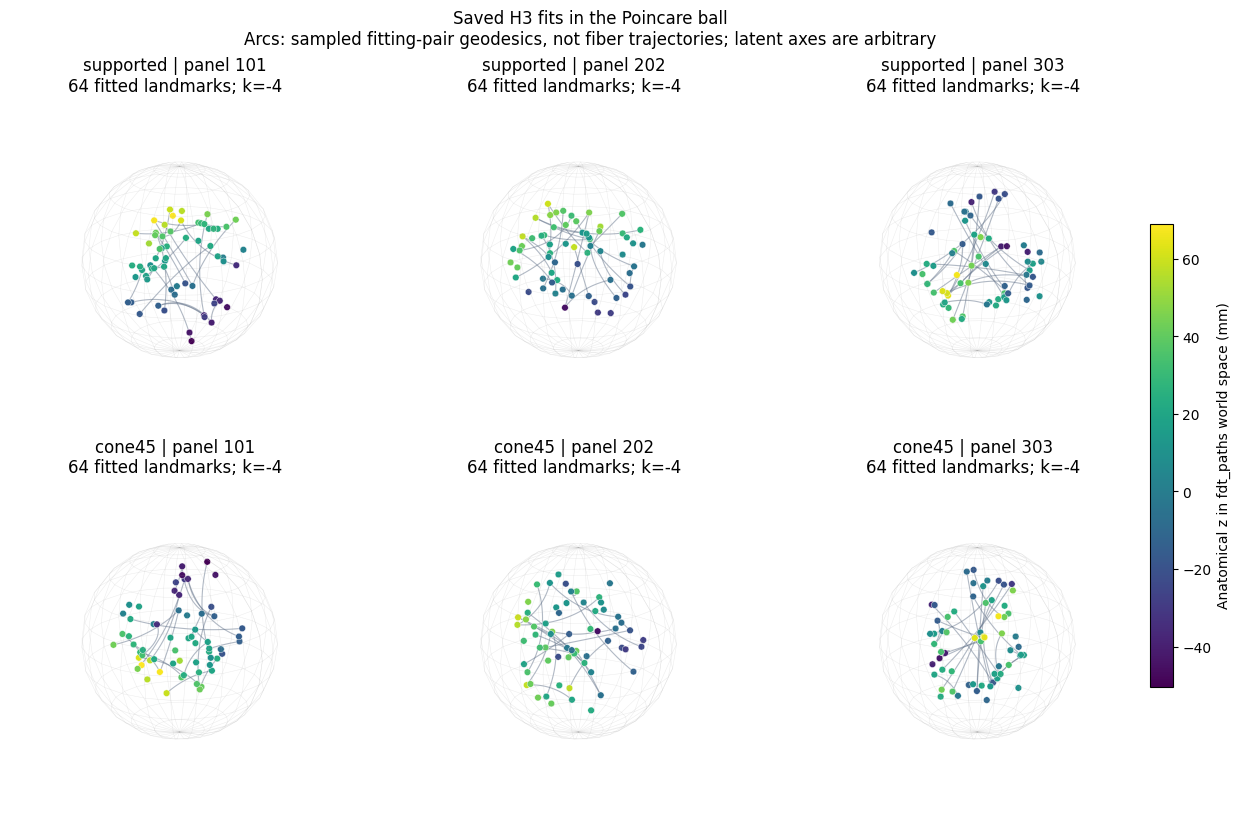

No new fitting, curvature search, shortest paths, or image checks.

Matched-dimension summary:
           metric  dimension  panels  mean_E_test_nRMSE  mean_H_test_nRMSE  mean_H_gain  mean_relative_H_reduction
  supported_graph          3       3           0.091687           0.074713     0.016973                   0.185407
  supported_graph          5       3           0.063726           0.060481     0.003245                   0.052481
supported_spatial          3       3           0.040602           0.037718     0.002884                   0.068609
supported_spatial          5       3           0.033359           0.032722     0.000637                   0.017672
     cone45_graph          3       3           0.113701           0.090802     0.022898                   0.200058
     cone45_graph          5       3           0.077932           0.072888     0.005045                   0.061294
   cone45_spatial          3       3           0.051710           0.042798     0.008912             

In [19]:
# Cell 16: Summarize evidence and visualize saved H3 embeddings
# Reuse existing results; no new fitting or curvature search

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell16.py"

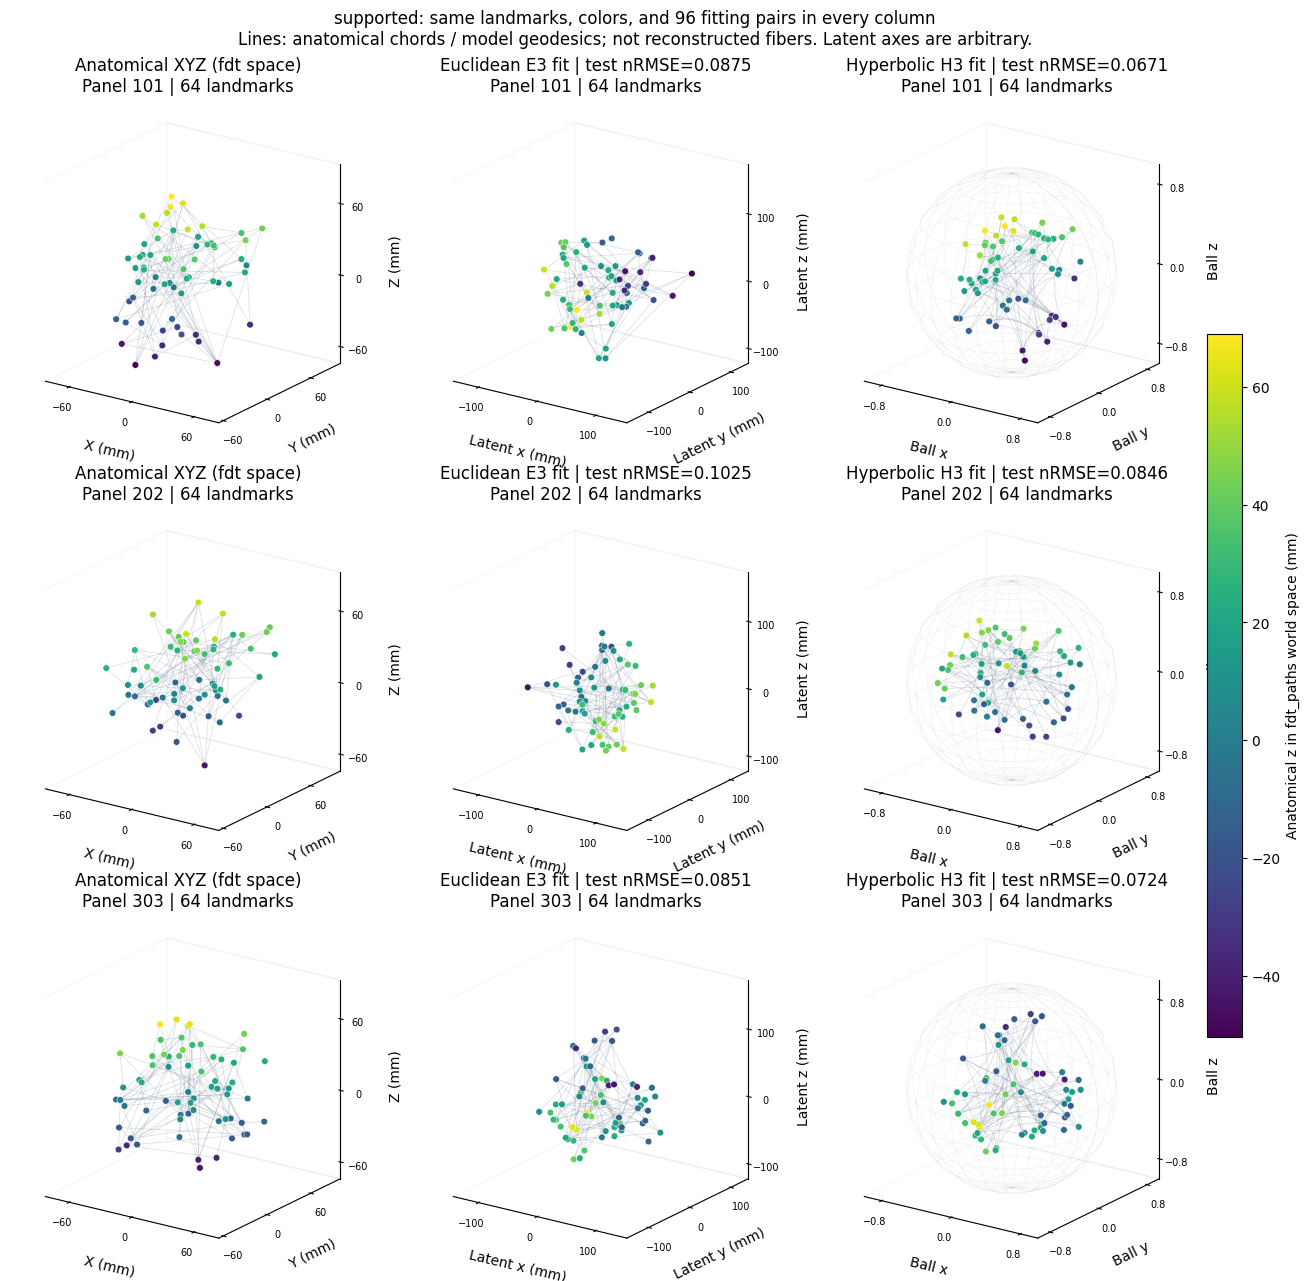

Saved comparison: supported, 3 panels, 96 lines per panel.


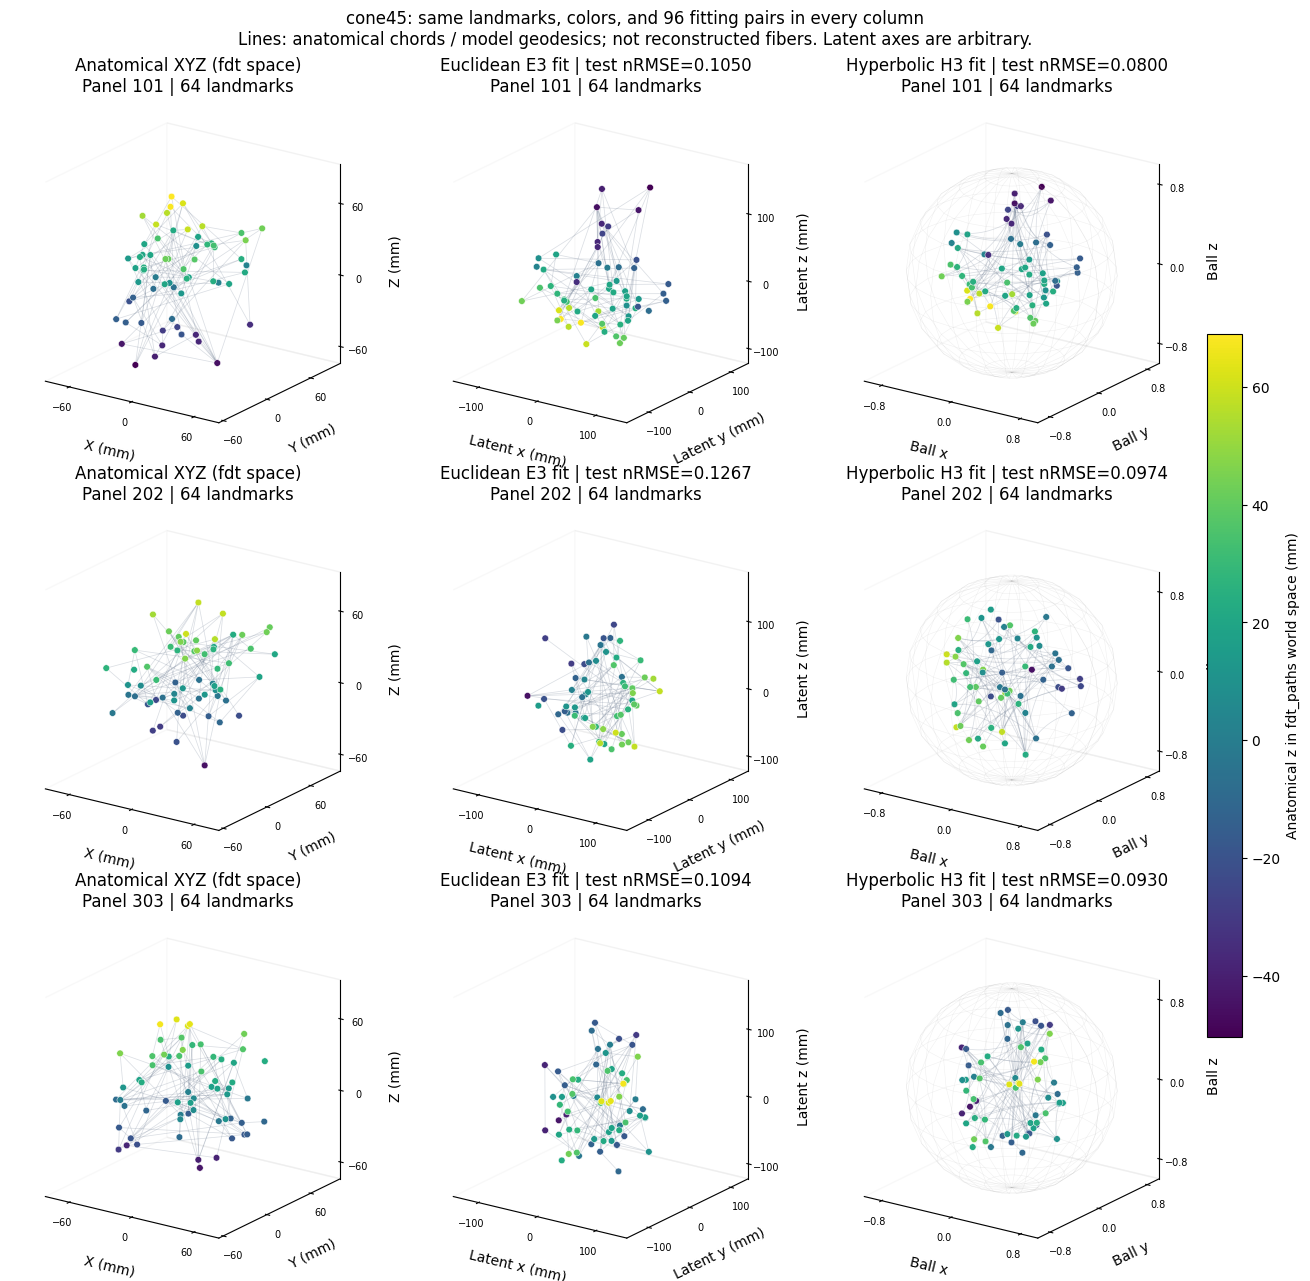

Saved comparison: cone45, 3 panels, 96 lines per panel.

Reproduced saved scores; no models were fitted:
    graph  panel_seed      model  landmarks  displayed_pairs  test_nRMSE  train_scale_mm
supported         101  euclidean         64               96    0.087535      103.428347
supported         101 hyperbolic         64               96    0.067085      103.428347
supported         202  euclidean         64               96    0.102459       93.582140
supported         202 hyperbolic         64               96    0.084623       93.582140
supported         303  euclidean         64               96    0.085064       95.774893
supported         303 hyperbolic         64               96    0.072446       95.774893
   cone45         101  euclidean         64               96    0.104990      113.995625
   cone45         101 hyperbolic         64               96    0.079961      113.995625
   cone45         202  euclidean         64               96    0.126679      103.038713
   co

In [20]:
# Cell 17: Anatomical XYZ versus fitted E3 and H3
# Same landmarks, colors, and displayed pairs; reuse saved fits

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell17.py"

Fixed ROI 1: /mnt/g/Research/TUM_connectome/HyperbolicTest/CC/roi_1.nii.gz
Distances use only edges between ROI-assigned nodes; paths cannot use outside nodes.

ROI coverage:
 roi_id     graph  mask_voxels  roi_nodes  roi_voxels  roi_edges  roi_components  roi_isolates  largest_nodes  largest_voxels  largest_node_fraction
      1 supported         9813        764         722        462             359           286             98              90               0.128272
Landmarks: 90; pairs: 4005; E3 versus H3 with frozen k=-4.
Three pair splits reuse these same landmarks and the same regional component.
Split 1807: E=0.1080; H=0.0645; fit_ok=True/True
Split 1817: E=0.1057; H=0.0656; fit_ok=True/True
Split 1827: E=0.1033; H=0.0633; fit_ok=True/True


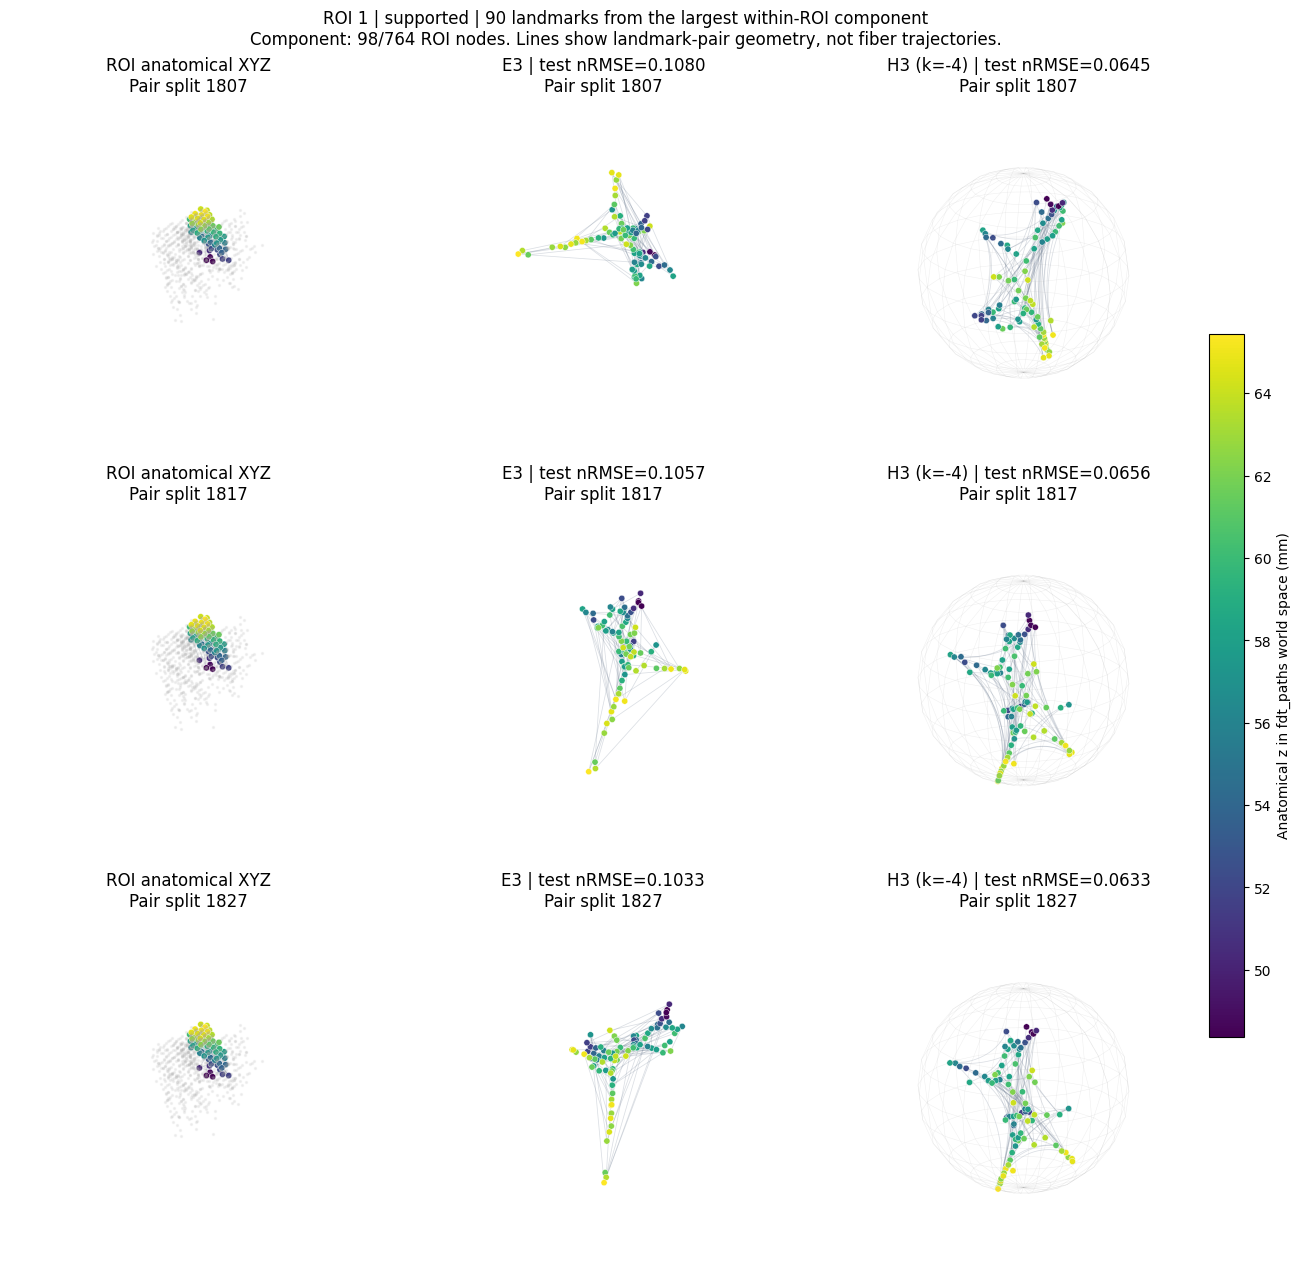

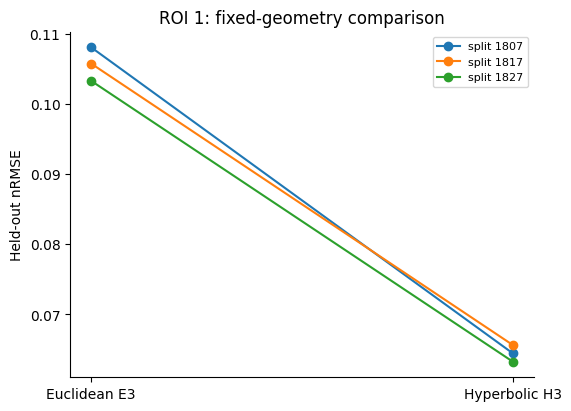


Paired results (descriptive; positive E_minus_H favors H):
 split_seed  euclidean  hyperbolic  E_minus_H  relative_H_reduction  both_fits_ok
       1807   0.108048    0.064459   0.043589              0.403423          True
       1817   0.105733    0.065642   0.040091              0.379169          True
       1827   0.103273    0.063271   0.040003              0.387348          True
Optimizer convergence: 12/12
Fixed regional component and fixed curvature; no claim about all ROI tissue or optimal regional geometry.
Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell18_roi_001_supported


In [21]:
# Cell 18: Within-ROI geometry comparison
# Fixed ROI 1; matched E3/H3 fits; no curvature search or FSL

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell18.py"

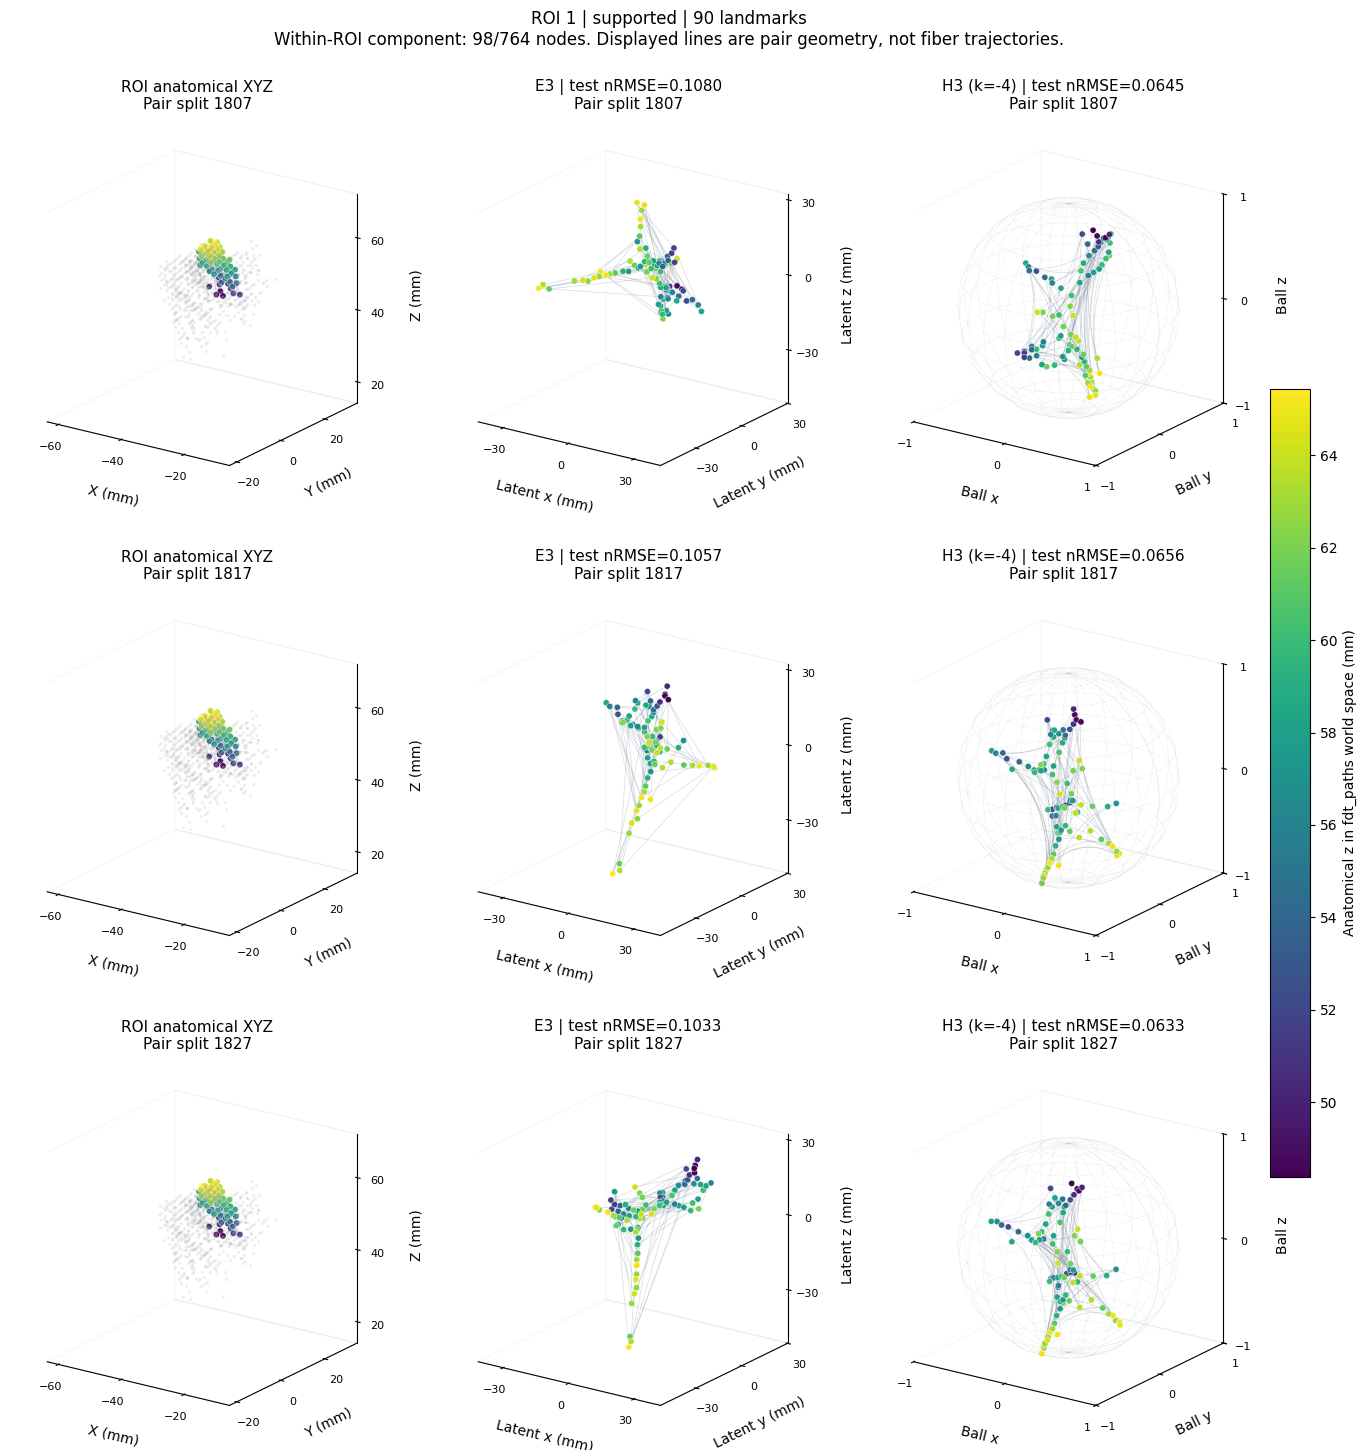

Redrawn with labeled XYZ axes and numerical ticks. No fitting was run.
Coordinates: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell18_roi_001_supported/with_axes/point_coordinates.csv
Figures: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell18_roi_001_supported/with_axes/roi_xyz_E3_H3_axes.png
         /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell18_roi_001_supported/with_axes/roi_xyz_E3_H3_axes.pdf


In [22]:
# Cell 18b: Restore XYZ axes, numeric ticks, and coordinate exports
# Redraw saved results without refitting

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell18b.py"

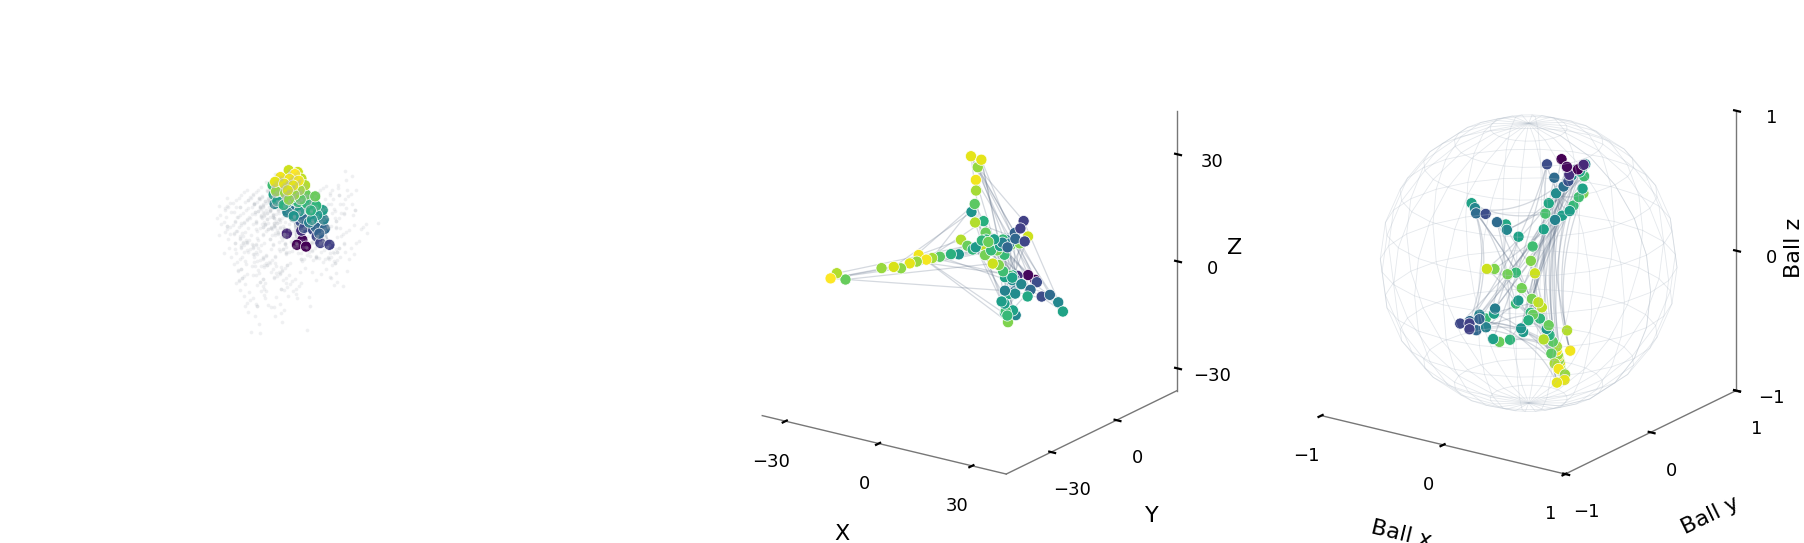

Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell18_roi_001_supported/figure_row


In [23]:
# Cell 18c: aligned single-row ROI visualization
# Anatomical points | Euclidean XYZ | Poincare ball
# Reuse saved split 1807; no refitting or new shortest paths.

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell18c.py"

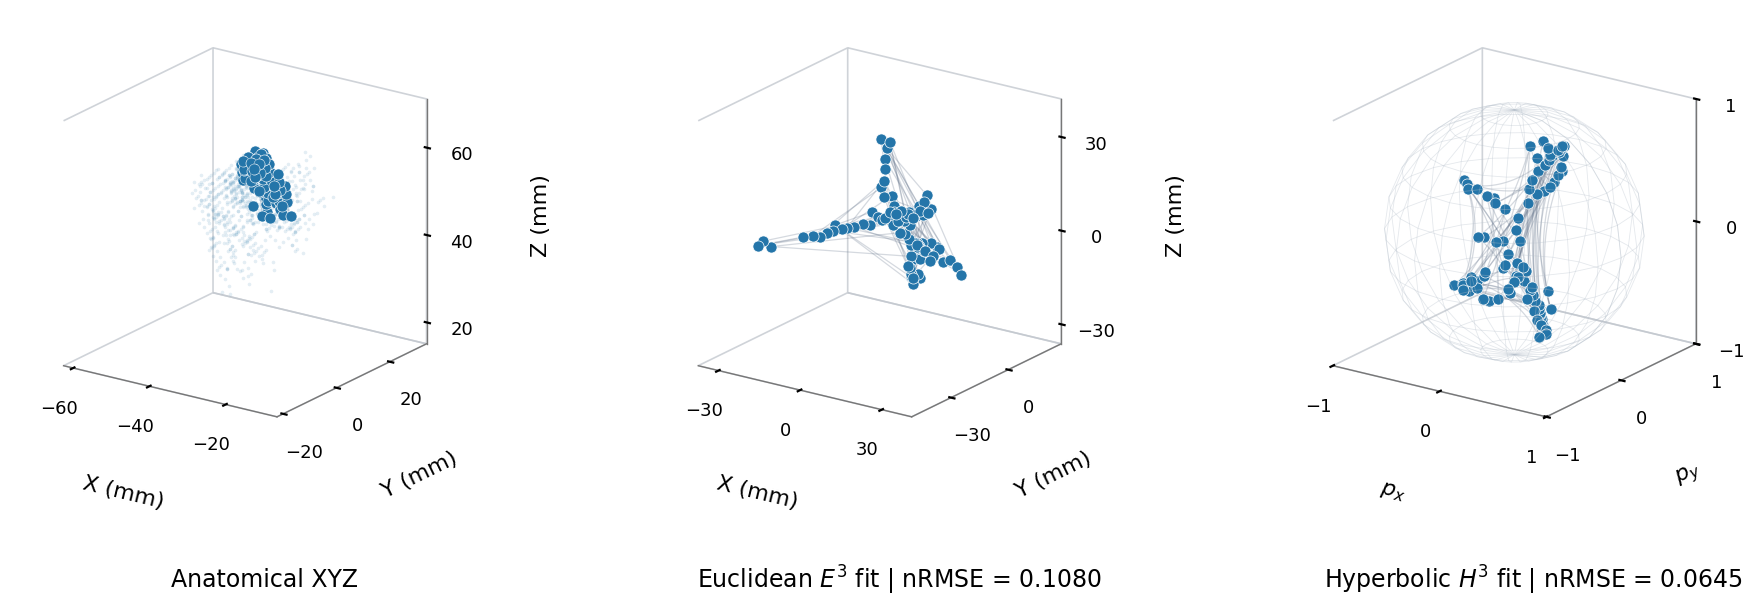

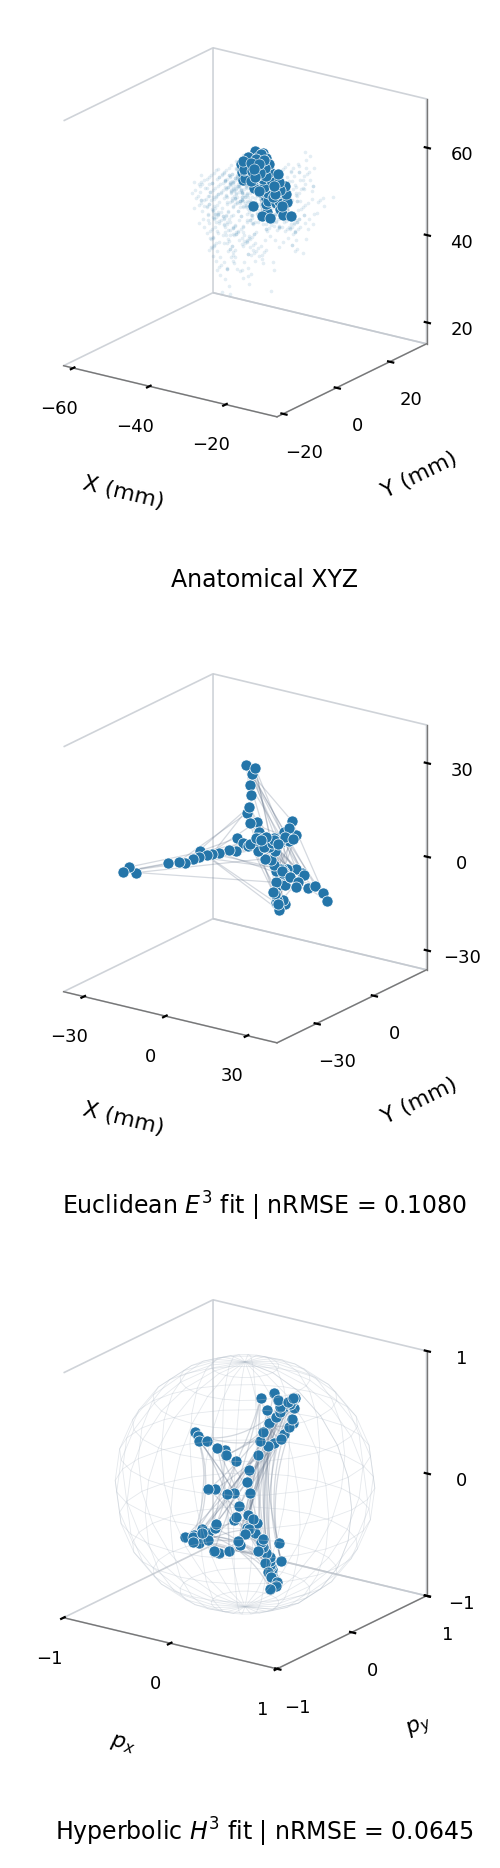

Saved: /mnt/g/Research/TUM_connectome/HyperbolicTest/results/cell19_roi_001_supported
Row and column layouts: preview PNG, 600-dpi PNG, and vector PDF.
Split 1807: held-out E3 nRMSE = 0.1080; H3 nRMSE = 0.0645.
Anatomical/E3 axes: mm. Poincare ball axes: dimensionless p_x, p_y, p_z.

Landmark sampling (voxel-based selection; node ratios are descriptive):
                   reference  landmarks  denominator  sampled_percent
ROI largest-component voxels         90           90         100.0000
 ROI largest-component nodes         90           98          91.8367
         All ROI graph nodes         90          764          11.7801
Faint anatomical context: 764 displayed / 764 ROI graph nodes.
Routing used the saved full ROI graph, including non-landmark intermediate nodes.


In [27]:
# Cell 19: Full axes, light-gray spatial frames, and landmark sampling summary.
%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell19.py"

In [28]:
# Cell 20: Compare E3 and H3 across all 120 ROIs.
# Save per-ROI metrics, coordinates, horizontal figures and vector PDFs.
# Resume completed ROIs automatically.

%run -i "/mnt/g/Research/TUM_connectome/HyperbolicTest/fiber_geometry_cell20.py"

Loading saved supported graph and fdt-space node assignments ...
ROIs: 120 | E3/H3 | fixed k=-4 | up to 128 landmarks per ROI.
Three paired 80/20 splits; figures always show split 1807. No curvature search.
Each ROI saves its own results, horizontal preview/600-dpi PNG and vector PDF.
[001/120] ROI 001: analyzing ...
    ROI nodes/edges: 764/462; landmarks: 90/90 largest-component voxels (100.00%).
    Split 1807: E=0.10805; H=0.06446; fit_ok=True/True
    Split 1817: E=0.10573; H=0.06564; fit_ok=True/True
    Split 1827: E=0.10327; H=0.06327; fit_ok=True/True
  ok | mean E-H=+0.04123 | 4.8 s | rough remaining 9.5 min
[002/120] ROI 002: analyzing ...
    ROI nodes/edges: 788/376; landmarks: 38/38 largest-component voxels (100.00%).
    Split 1807: E=0.09796; H=0.11045; fit_ok=True/True
    Split 1817: E=0.10648; H=0.12583; fit_ok=True/True
    Split 1827: E=0.10014; H=0.11569; fit_ok=True/True
  ok | mean E-H=-0.01580 | 3.3 s | rough remaining 8.0 min
[003/120] ROI 003: analyzing ...
 